<a href="https://colab.research.google.com/github/Opsimtech/CFD-ML-model/blob/main/Flettner_PINN_Final_TwoCases.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Flettner rotor PINN: final results for the manuscript (two training cases)

This notebook produces every flow-field result used in the manuscript, from **two trained runs** of the same PINN:

| Case | Run id | Training data | Role in the manuscript |
|---|---|---|---|
| **A** | `FULL_E_ncp30_s0` | 30 **experimental** wall-Cp points (Bordogna et al., 2019) | Main result: reconstruction from measured surface pressure |
| **B** | `FULL_ECFD_ncp30_s0` | 30 **CFD** wall-Cp points (same CFD as the reference) | Method check: consistent data, wall pressure only |

Both runs already exist in `refined_runs`. **This notebook does not train them again.** It loads the saved weights
(`ALLOW_TRAINING = False`). If a run is missing, it stops and tells you, instead of training.

**Model (both cases):** 2D steady incompressible momentum and continuity, one learned effective viscosity
ν_eff = 1/Re_eff, no-slip built into the network, ideal-flow starting field with a learned circulation Γ, far field =
wind + lift vortex with the velocity left free in a ±30° wake sector and Bernoulli pressure at every far-field point,
zero vorticity in the incoming flow, 30 wall-Cp observations. 6 × 128 tanh network, 6000 Adam epochs.

**Note on Γ:** in both runs the circulation Γ started from the reference lift of its own data set (wind-tunnel CL for
Case A, CFD CL for Case B) and was then optimised freely during training. The manuscript should state this
(see the methods text). A rerun that starts Γ from the Cp observations instead is optional (`gamma_init_from="cp_data"`).

Order: run every cell from top to bottom.

## 1. Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


## 2. Core module

Writes `flettner_pinn_core.py` (the model code). Run it first.


In [2]:
%%writefile flettner_pinn_core.py
"""
flettner_pinn_core.py  (REFINED copy)
======================
REFINED VERSION: identical to the original module when every refinement switch in RunConfig is left at its
default (turb_model="outer_kw", exact_noslip=False, ff_pressure="mean", gamma_init_from="cp_data" [only used with F7/F13], reproducible_seed=False, fix_best_after_ramp=False, nut_max=0.1, wall_omega="original", full_stress=False, turb_model="outer_kw",
turb_residual="clip", ff_vortex=False, ff_wake_exempt_deg=0, input_scaling="none", near_wall_frac=0,
wake_box_frac=0, wall_treatment="noslip", W_IRROT=0, ideal_flow_prior=False). Each switch is marked [F1]..[F13]
in the code. Changes outside those switches: the training log also prints the epoch the "best" weights come from,
the results json stores it, and evaluate() also reports MAE_no_shift.

Unified, parameterized core for the Flettner-rotor PINN app.

Consolidates what was previously spread across five separate notebooks
(Flettner_PINN_NCp8.ipynb, Flettner_PINN_DataEfficiency.ipynb,
Flettner_PINN_ClosureStudies.ipynb Study A + Study B,
Flettner_PINN_ControlAlpha0.ipynb v1-v4) into one reusable library that
every case in the app runs through. A "case" is fully described by a
RunConfig; running one case always goes through the same four functions:
build_model -> train -> evaluate -> flow_field_diagnostics.

IMPORTANT — read before treating this as a drop-in replacement:
The Cp-data loss term (active whenever cfg.NCp > 0) is NEWLY WRITTEN for
this module. The physics-only (NCp=0) training loop is a direct,
verified port of Flettner_PINN_ControlAlpha0.ipynb's Cell 4 (validated
across v1/v2/v3/v4 this session). The NCp>0 data-loss code path, however,
was authored fresh from the documented conventions in
Manuscript_Chat_Summary.md Section 3 (pressure gauge = mean far-field p,
post-hoc Cp shift at evaluation only) because the actual Cell 4 code from
NCp8.ipynb / DataEfficiency.ipynb was never shown in this session — only
its *results* (e.g. NCp=8 best run: MAE=0.219, CL=5.046, CD=1.692) were
recorded. Before relying on this module as the sole system of record,
re-run NCp=8 @ alpha=2 through it and confirm it reproduces MAE ~ 0.219.
If it doesn't, do not treat the old notebooks as superseded until the
discrepancy is understood.

Every run is resume-safe (local backup -> Drive remount check -> write ->
read-back verification), matching the pattern used throughout this
project's other notebooks.
"""

import os
import json
import time
import shutil
from dataclasses import dataclass, field, asdict
from typing import Optional, List, Tuple, Dict, Any

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt


# ══════════════════════════════════════════════════════════════════════
# 1. RunConfig — one dataclass describes every case type this app
#    supports (core sweep, Study A hyperparameter variants, Study B
#    sector masking, ControlAlpha0 compact-domain / hard-constraint).
# ══════════════════════════════════════════════════════════════════════

@dataclass
class RunConfig:
    run_id: str                                   # unique, user-set or auto-generated
    RE: float = 3.6e5
    ALPHA: float = 2.0
    R_IN: float = 0.5
    R_OUT: float = 25.0

    # ── Data (Cp) configuration ──
    NCp: int = 8                                   # 0 = physics only
    cp_selection: str = "evenly_spaced_index"      # or "explicit"
    cp_theta_explicit: Optional[List[float]] = None    # used iff cp_selection == "explicit"
    mask_sectors: Optional[List[Tuple[float, float]]] = None
    # sectors given as (theta_start_deg, theta_end_deg), wrapping allowed
    # (e.g. (315, 45)). Points in these sectors are ALWAYS excluded from
    # the training loss regardless of NCp, and scored separately as
    # "masked-sector MAE" in evaluate() — this is Study B's methodology,
    # generalized so the same run can also carry an NCp limit if desired.

    # ── Architecture ──
    hard_constrain_farfield: bool = False          # v3-style Sukumar & Srivastava (2022) hard BC
    pp_pointwise: bool = False
    net_depth: int = 6
    net_width: int = 64

    # ── Training schedule ──
    EPOCHS: int = 6000
    LR: float = 1e-4
    LR_DECAY_EPOCH: int = 3000
    LR_DECAY_TO: float = 3e-5
    TURB_RAMP_START: int = 1000
    TURB_RAMP_LEN: int = 1000
    N_INT: int = 2000
    N_WALL: int = 300
    N_FF: int = 150

    # ── Loss weights ──
    W_PDE: float = 100.
    W_VWALL: float = 300.
    W_VFF: float = 10.
    W_PP: float = 50.
    W_CP: float = 10.
    W_TURB: float = 1.

    # ── Warm start / curriculum (Study A P6-style) ──
    warm_start_run_id: Optional[str] = None        # load initial weights from another run's checkpoint

    # ── Refinements (each switch defaults to the ORIGINAL behaviour; turn them on one at a time) ──
    # See the "Diagnosis" section of the notebook for why each one exists.
    reproducible_seed: bool = False     # [F0] also fix the Keras/NumPy seeds (tf.random.set_seed alone does NOT fix
                                        #      the weight initialisation in Keras 3, so "seed=0" runs differ each time)
    fix_best_after_ramp: bool = False   # [F1] keep "best" weights only once the turbulence ramp is complete
    nut_max: float = 0.1                # [F2] cap on nu_t (original 0.1 = nu_t/nu 36,000 = Re_eff 10)
    wall_omega: str = "original"        # [F3] wall omega: "original" (60*nu) | "menter" (60*nu/(beta1*wall_y1^2))
    wall_y1: float = 1e-3               #      first-point distance used by wall_omega="menter"
    full_stress: bool = False           # [F4] add grad(nu_t) terms: div[nu_eff (grad u + grad u^T)] and in k/omega diffusion
    turb_model: str = "outer_kw"        # [F5] "outer_kw" (original: outer constants only, nu_t = k/omega)
                                        #      | "sst" (Menter 2003: F1/F2 blending + nu_t = a1 k / max(a1 omega, S F2))
                                        #      | "constant_nu" [F14] (one learned viscosity, see below)
    turb_residual: str = "clip"         # [F6] "clip" (original: clip at +-100, zero gradient outside)
                                        #      | "scaled" (divide by each equation's own source terms)
    ff_vortex: bool = False             # [F7] far-field u, v = wind + lift vortex with learned circulation Gamma
    ff_wake_exempt_deg: float = 0.0     # [F8] half-angle (deg) of the wake sector at R_OUT where u, v, k, omega are not forced
    input_scaling: str = "none"         # [F9] "none" (raw x, y) | "logpolar" (log r, cos, sin inside the network)
    near_wall_frac: float = 0.0         # [F10] extra share of interior points in the band R_wall .. R_wall + 0.15
    wake_box_frac: float = 0.0          #       extra share of interior points in the box x 0..8, y -4..2
    wall_treatment: str = "noslip"      # [F11] "noslip" (original) | "wall_function" (log-law at R_IN + wall_fn_dist)
    wall_fn_dist: float = 0.01          #       wall-function distance in D (y+ about 50-300 at Re 3.6e5)
    wf_shear_weight: float = 0.01       #       weight of the log-law wall-shear term inside the wall loss (x W_VWALL)
    W_IRROT: float = 0.0                # [F12] weight of "no vorticity in the incoming air" (x < 0, r > R_IN + 0.25)
    ideal_flow_prior: bool = False      # [F13] u, v = ideal flow with circulation Gamma + network correction
    # ── Two parts taken from the Claude PINN (PyTorch notebook) ──
    # [F14] turb_model="constant_nu": ONE learned viscosity nu_eff = 1/Re_eff everywhere, used from epoch 0
    #       (the k-omega outputs are then ignored: no k/omega equations, wall or far-field conditions)
    re_eff_init: float = 1000.0         #       starting Re_eff (Claude PINN: 1000 for k = 2, 200 for k = 0)
    re_eff_min: float = 300.0           #       Re_eff is learned inside [min, max] (k = 2: 300..10000; k = 0: 20..5000)
    re_eff_max: float = 10000.0
    exact_noslip: bool = False          # [F15] wall speed built into the network output (no-slip always exact):
                                        #       u = (1 - d) u_wall + d u_net,  d = 1 - exp(-(r - R_IN) / spin_layer)
    spin_layer: float = 0.05            #       thickness (D) of the layer over which the wall speed fades out
    gamma_init_from: str = "cp_data"    # [F17] starting value of the learned circulation Gamma (F7/F13):
                                        #       "cp_data" = lift implied by the Cp observations given to the PINN (no force data)
                                        #       | "zero" | "cl_ref" = measured lift (uses force-balance data: avoid in the paper)
    ff_pressure: str = "mean"           # [F16] far-field pressure: "mean" (original: only the AVERAGE far-field p = 0)
                                        #       | "bernoulli": at EVERY far-field point p = 0.5 (1 - |u_target|^2)
                                        #       (u_target = wind + lift swirl if ff_vortex, else wind)

    seed: Optional[int] = None
    notes: str = ""

    def to_dict(self) -> Dict[str, Any]:
        return asdict(self)


# ══════════════════════════════════════════════════════════════════════
# 2. Drive-safe I/O — same pattern as every other notebook in this
#    project (local backup -> remount check -> write -> read-back).
# ══════════════════════════════════════════════════════════════════════

def drive_alive(drive_path="/content/drive"):
    return os.path.ismount(drive_path)


def ensure_drive(drive_path="/content/drive", out_dir=None):
    if not drive_alive(drive_path):
        print("  ⚠ Drive mount lost — remounting...")
        from google.colab import drive as _drv
        _drv.mount(drive_path, force_remount=True)
        if out_dir:
            os.makedirs(out_dir, exist_ok=True)


def safe_save_json(obj, path, backup_path="/content/_core_backup.json"):
    with open(backup_path, "w") as f:
        json.dump(obj, f)
        f.flush(); os.fsync(f.fileno())
    ensure_drive(out_dir=os.path.dirname(path))
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)
        f.flush(); os.fsync(f.fileno())
    with open(path) as f:
        json.load(f)  # read-back verification
    print(f"  💾 verified: {os.path.basename(path)} "
          f"({os.path.getsize(path)/1024:.0f} KB) ✓")


def safe_save_weights(model, path, tmp_path="/content/_tmp_core.weights.h5"):
    model.save_weights(tmp_path)
    ensure_drive(out_dir=os.path.dirname(path))
    shutil.copy(tmp_path, path)
    if os.path.exists(path) and os.path.getsize(path) > 0:
        print(f"  💾 weights verified: {os.path.basename(path)} ✓")
    else:
        print(f"  ✗ WEIGHTS SAVE FAILED: {path}")


def run_paths(cfg: RunConfig, out_dir: str):
    base = f"{out_dir}/{cfg.run_id}"
    return dict(
        results=f"{base}_results.json",
        weights=f"{base}.weights.h5",
        cp_plot=f"{base}_cp.png",
        flowfield_plot=f"{base}_flowfield.png",
        farfield_json=f"{base}_farfield_diagnostic.json",
    )


# ══════════════════════════════════════════════════════════════════════
# 3. Bordogna experimental data loader — direct port of Cell 2, shared
#    across every case type (unchanged from the validated original).
# ══════════════════════════════════════════════════════════════════════

RE_COL_MAP = {1.8e5: {0, 12, 24, 36, 48, 60},
              2.5e5: {3, 15, 27, 39, 51, 63, 69, 75, 81, 87, 93},
              3.6e5: {6, 18, 30, 42, 54, 72, 78, 84, 90, 96},
              1.0e6: {9, 21, 33, 45, 57, 66}}


def load_cp(folder, re_t, a_t, tol=0.1):
    for nm in ["CP_data.xlsx", "CP data.xlsx"]:
        p = os.path.join(folder, nm)
        if os.path.exists(p):
            break
    raw = pd.read_excel(p, sheet_name="Master Data", header=None)
    row0 = raw.iloc[0]
    for col in range(0, len(row0) - 1, 3):
        lab = str(row0.iloc[col])
        if "k =" not in lab:
            continue
        try:
            kv = float(lab.split(",")[0].replace("k =", "").strip())
        except Exception:
            continue
        if abs(kv - a_t) > tol:
            continue
        rm = None
        for rv, cs in RE_COL_MAP.items():
            if col in cs:
                rm = rv
                break
        if rm is None or abs(rm - re_t) > re_t * 0.1:
            continue
        th = pd.to_numeric(raw.iloc[2:, col], errors="coerce").values
        cp = pd.to_numeric(raw.iloc[2:, col + 1], errors="coerce").values
        m = ~np.isnan(th) & ~np.isnan(cp)
        if m.sum() < 3:
            continue
        return th[m].astype(np.float32), cp[m].astype(np.float32)
    raise ValueError(f"No Cp data for alpha={a_t}, Re={re_t:.2e}")


def load_cl_cd(folder, re_t):
    sheet = {1.8e5: "Re=1.8e5", 2.5e5: "Re=2.5e5", 3.6e5: "Re=3.6e5",
              5.5e5: "Re=5.5e5", 1.0e6: "Re=1e6"}[min(
        {1.8e5, 2.5e5, 3.6e5, 5.5e5, 1.0e6}, key=lambda r: abs(r - re_t))]
    for nm in ["CL_data.xlsx", "CL data.xlsx"]:
        p = os.path.join(folder, nm)
        if os.path.exists(p):
            clp = p
            break
    for nm in ["CD_data.xlsx", "CD data.xlsx"]:
        p = os.path.join(folder, nm)
        if os.path.exists(p):
            cdp = p
            break
    dcl = pd.read_excel(clp, sheet_name=sheet, header=None)
    dcd = pd.read_excel(cdp, sheet_name=sheet, header=None)
    dcl.columns = ["alpha", "CL"] + list(dcl.columns[2:])
    dcd.columns = ["alpha", "CD"] + list(dcd.columns[2:])
    return (dcl["alpha"].dropna().values.astype(np.float32),
            dcl["CL"].dropna().values.astype(np.float32),
            dcd["alpha"].dropna().values.astype(np.float32),
            dcd["CD"].dropna().values.astype(np.float32))


def load_bordogna(data_dir: str, cfg: RunConfig):
    theta_exp, cp_exp = load_cp(data_dir, cfg.RE, cfg.ALPHA)
    al_cl, CL_e, al_cd, CD_e = load_cl_cd(data_dir, cfg.RE)
    tol = 0.25
    cl_ref = float(CL_e[np.abs(al_cl - cfg.ALPHA) < tol].mean()) \
        if np.any(np.abs(al_cl - cfg.ALPHA) < tol) else 0.0
    cd_ref = float(CD_e[np.abs(al_cd - cfg.ALPHA) < tol].mean()) \
        if np.any(np.abs(al_cd - cfg.ALPHA) < tol) else np.nan
    return dict(theta_exp=theta_exp, cp_exp=cp_exp, cl_ref=cl_ref, cd_ref=cd_ref)


def load_cfd_wall_cp(csv_path, n_points=120, r_wall=0.5, diameter=1.0, tol=1e-3):
    """Wall Cp from a Fluent node export (columns x-coordinate, y-coordinate, expr:P_scaled), in the SAME format as
    load_bordogna(): theta_exp in degrees with the paper's convention (0 = facing the wind, 90 = lift side),
    resampled to n_points equally spaced angles. cl_ref and cd_ref are the pressure-only integrals of that curve,
    so the PINN is scored against the CFD. Use it in place of load_bordogna() to train on CFD data (method check)."""
    d = pd.read_csv(csv_path)
    d.columns = [c.strip().replace(chr(0xFEFF), "") for c in d.columns]
    x = d["x-coordinate"].values / diameter; y = d["y-coordinate"].values / diameter
    on_wall = np.abs(np.hypot(x, y) - r_wall) < tol
    th = np.mod(np.degrees(np.arctan2(y[on_wall], -x[on_wall])), 360.0)
    cp = d["expr:P_scaled"].values[on_wall]
    o = np.argsort(th); th, cp = th[o], cp[o]
    grid = np.arange(n_points) * 360.0 / n_points
    cp_g = np.interp(grid, np.r_[th, th[0] + 360.0], np.r_[cp, cp[0]])
    t = np.radians(grid); dt = 2 * np.pi / n_points
    cd_ref = float(0.5 * np.sum(cp_g * np.cos(t)) * dt)
    cl_ref = float(-0.5 * np.sum(cp_g * np.sin(t)) * dt)
    print(f"CFD wall Cp: {on_wall.sum()} wall nodes -> {n_points} angles | pressure-only CL = {cl_ref:.3f}, CD = {cd_ref:.3f}")
    return dict(theta_exp=grid.astype(np.float32), cp_exp=cp_g.astype(np.float32), cl_ref=cl_ref, cd_ref=cd_ref)


# ══════════════════════════════════════════════════════════════════════
# 4. Cp point selection — generalizes NCp sweeps (DataEfficiency) AND
#    sector masking (Study B) into one mechanism. train_idx feeds the
#    Cp-data loss; masked_idx is scored separately at evaluation time
#    but never trained on; all points remain in eval_idx for the
#    standard overall-MAE metric already used throughout this project.
# ══════════════════════════════════════════════════════════════════════

def _in_sector(theta, start, end):
    """theta, start, end all in degrees [0,360). Handles wraparound
    sectors like (315, 45)."""
    theta = theta % 360.0
    if start <= end:
        return (theta >= start) & (theta <= end)
    return (theta >= start) | (theta <= end)


def select_cp_points(theta_exp: np.ndarray, cp_exp: np.ndarray, cfg: RunConfig):
    n = len(theta_exp)
    masked = np.zeros(n, dtype=bool)
    if cfg.mask_sectors:
        for (s, e) in cfg.mask_sectors:
            masked |= _in_sector(theta_exp, s, e)

    available = np.where(~masked)[0]  # indices eligible for training

    if cfg.NCp <= 0:
        train_idx = np.array([], dtype=int)
    elif cfg.cp_selection == "explicit" and cfg.cp_theta_explicit is not None:
        train_idx = np.array([int(np.argmin(np.abs(theta_exp - t)))
                               for t in cfg.cp_theta_explicit], dtype=int)
        train_idx = np.array([i for i in train_idx if i in available], dtype=int)
    else:
        # evenly_spaced_index: pick NCp indices evenly spaced through the
        # available (non-masked) points, in angular order — this is the
        # same "phase bins of the phase-averaged curve" framing used for
        # the DataEfficiency sweep (see Manuscript_Chat_Summary.md Sec.1).
        order = available[np.argsort(theta_exp[available])]
        k = min(cfg.NCp, len(order))
        if k <= 0:
            train_idx = np.array([], dtype=int)
        else:
            pick = np.linspace(0, len(order) - 1, k).round().astype(int)
            train_idx = np.unique(order[pick])

    masked_idx = np.where(masked)[0]
    eval_idx = np.arange(n)
    return dict(train_idx=train_idx, masked_idx=masked_idx, eval_idx=eval_idx)


# ══════════════════════════════════════════════════════════════════════
# 5. Model — direct generalization of ControlAlpha0 v3's Cell 3.
#    hard_constrain_farfield=False reproduces v1/v2/v4's plain
#    Dense(3) output exactly; =True reproduces v3's Lambda hard-BC layer.
#    net_depth/net_width generalize Study A's P4_big8x128 network-size
#    variant.
# ══════════════════════════════════════════════════════════════════════

def r_wall(cfg: RunConfig):
    """Radius where the wall condition, Cp data and wall forces are applied: R_IN, or R_IN + wall_fn_dist
    with wall functions [F11]."""
    return cfg.R_IN + (cfg.wall_fn_dist if cfg.wall_treatment == "wall_function" else 0.0)


class GammaLayer(tf.keras.layers.Layer):
    """Holds the learned circulation Gamma [F7, F13]. Returns its input unchanged; Gamma is read with .gamma."""
    def build(self, input_shape):
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)

    def call(self, x):
        return x


class ReEffLayer(tf.keras.layers.Layer):
    """Holds the learned log(Re_eff) [F14]. Returns its input unchanged."""
    def __init__(self, init_value=1000.0, **kw):
        super().__init__(**kw)
        self.init_value = float(init_value)

    def build(self, input_shape):
        self.log_re = self.add_weight(name="log_re_eff", shape=(),
                                      initializer=tf.keras.initializers.Constant(np.log(self.init_value)),
                                      trainable=True)

    def call(self, x):
        return x


def re_eff_of(model, cfg):
    """Learned effective Reynolds number, kept inside [re_eff_min, re_eff_max] [F14]."""
    return tf.clip_by_value(tf.exp(model.get_layer("re_eff").log_re), cfg.re_eff_min, cfg.re_eff_max)


def get_gamma(model):
    try:
        return model.get_layer("gamma").gamma
    except ValueError:
        return None


def build_model(cfg: RunConfig):
    tf.keras.backend.clear_session()
    if cfg.seed is not None:
        tf.random.set_seed(cfg.seed)
        if cfg.reproducible_seed:                       # [F0]
            tf.keras.utils.set_random_seed(cfg.seed)

    inp = tf.keras.Input(shape=(3,))
    use_gamma = cfg.ff_vortex or cfg.ideal_flow_prior
    gl = GammaLayer(name="gamma") if use_gamma else None
    h = gl(inp) if use_gamma else inp
    if cfg.turb_model == "constant_nu":                 # [F14]
        h = ReEffLayer(cfg.re_eff_init, name="re_eff")(h)

    # [F9] the network sees (log r, cos phi, sin phi, alpha) instead of raw (x, y, alpha). The transform is inside
    # the network, so the model input stays (x, y, alpha/5) and all derivatives are still with respect to x and y.
    if cfg.input_scaling == "logpolar":
        r_lo, r_hi = float(r_wall(cfg)), float(cfg.R_OUT)
        def _logpolar(a):
            x, y, al = a[:, 0:1], a[:, 1:2], a[:, 2:3]
            r = tf.sqrt(x ** 2 + y ** 2)
            rho = 2.0 * tf.math.log(r / r_lo) / np.log(r_hi / r_lo) - 1.0
            return tf.concat([rho, x / r, y / r, al], axis=1)
        h = tf.keras.layers.Lambda(_logpolar, name="logpolar")(h)

    for _ in range(cfg.net_depth):
        h = tf.keras.layers.Dense(cfg.net_width, activation="tanh")(h)

    if cfg.hard_constrain_farfield:
        uv_corr = tf.keras.layers.Dense(2, activation=None)(h)
        p_out = tf.keras.layers.Dense(1, activation=None)(h)
        ko = tf.keras.layers.Dense(2, activation="softplus")(h)

        R_OUT_local = cfg.R_OUT

        def _hard_bc_uv(args):
            inp_full, corr = args
            x = inp_full[:, 0:1]
            y = inp_full[:, 1:2]
            r = tf.sqrt(x ** 2 + y ** 2)
            d = 1.0 - tf.clip_by_value(r / R_OUT_local, 0.0, 1.0) ** 2
            u = 1.0 + d * corr[:, 0:1]
            v = 0.0 + d * corr[:, 1:2]
            return tf.concat([u, v], axis=1)

        uv_hard = tf.keras.layers.Lambda(_hard_bc_uv, name="hard_bc_uv")([inp, uv_corr])
        uvp = tf.keras.layers.Concatenate(name="uvp")([uv_hard, p_out])
    elif cfg.ideal_flow_prior:
        # [F13] u, v = ideal flow around a cylinder with circulation Gamma (clockwise = lift to +y) + correction
        uvp_corr = tf.keras.layers.Dense(3, activation=None)(h)
        ko = tf.keras.layers.Dense(2, activation="softplus")(h)
        Rc = float(cfg.R_IN)

        def _prior(args):
            inp_full, corr = args
            x, y = inp_full[:, 0:1], inp_full[:, 1:2]
            r2 = x ** 2 + y ** 2
            g = gl.gamma
            u0 = 1.0 - Rc ** 2 * (x ** 2 - y ** 2) / r2 ** 2 + g * y / (2 * np.pi * r2)
            v0 = -2.0 * Rc ** 2 * x * y / r2 ** 2 - g * x / (2 * np.pi * r2)
            return tf.concat([u0 + corr[:, 0:1], v0 + corr[:, 1:2], corr[:, 2:3]], axis=1)

        uvp = tf.keras.layers.Lambda(_prior, name="ideal_prior")([inp, uvp_corr])
    else:
        uvp = tf.keras.layers.Dense(3, activation=None)(h)
        ko = tf.keras.layers.Dense(2, activation="softplus")(h)

    if cfg.exact_noslip:
        # [F15] no-slip built in: on r = R_IN the velocity IS the wall speed (Omega*y, -Omega*x); the network's own
        # velocity takes over within a few spin_layer thicknesses. Pressure is not touched.
        Om, Rw, lay = float(cfg.ALPHA / cfg.R_IN), float(cfg.R_IN), float(cfg.spin_layer)

        def _noslip(args):
            inp_full, o = args
            x, y = inp_full[:, 0:1], inp_full[:, 1:2]
            r = tf.sqrt(x ** 2 + y ** 2)
            d = 1.0 - tf.exp(-(r - Rw) / lay)
            u = (1.0 - d) * (Om * y * Rw / r) + d * o[:, 0:1]
            v = (1.0 - d) * (-Om * x * Rw / r) + d * o[:, 1:2]
            return tf.concat([u, v, o[:, 2:3]], axis=1)

        uvp = tf.keras.layers.Lambda(_noslip, name="exact_noslip")([inp, uvp])
    model = tf.keras.Model(inp, [uvp, ko])

    if cfg.warm_start_run_id is not None:
        pass  # weight loading handled by caller (train()) once paths are known

    return model


def get_uvp(o):
    return o[0]


def get_ko(o):
    return o[1]


def mse(a, b=0.0):
    return tf.reduce_mean(tf.square(a - b))


def make_turb_constants(cfg: RunConfig):
    NU = 1.0 / cfg.RE
    ow = 60. * float(NU)                                            # original wall omega [F3]
    if cfg.wall_omega == "menter":
        ow = 60. * float(NU) / (0.075 * cfg.wall_y1 ** 2)
    return dict(
        NU=tf.constant(float(NU), tf.float32), BSTAR=tf.constant(.09, tf.float32),
        BETA2=tf.constant(.0828, tf.float32), SK2=tf.constant(1., tf.float32),
        SO2=tf.constant(.856, tf.float32),
        GAM2=tf.constant(.0828 / .09 - .856 * .41 ** 2 / .09 ** .5, tf.float32),
        EPS=tf.constant(1e-8, tf.float32), KW=tf.constant(0., tf.float32),
        OW=tf.constant(ow, tf.float32),
        KI=tf.constant(1.5e-4, tf.float32), OI=tf.constant(2., tf.float32),
        # inner (k-omega) SST constants, used only with turb_model="sst" [F5]
        BETA1=tf.constant(.075, tf.float32), SK1=tf.constant(.85, tf.float32), SO1=tf.constant(.5, tf.float32),
        GAM1=tf.constant(.075 / .09 - .5 * .41 ** 2 / .09 ** .5, tf.float32), A1=tf.constant(.31, tf.float32),
        KAPPA=0.41, E_LOG=9.793,
    )


def make_input_fn(cfg: RunConfig):
    def make_input(x, y):
        a = np.full_like(x, cfg.ALPHA / 5.0, dtype=np.float32)
        return tf.constant(np.hstack([x, y, a]))
    return make_input


def sample_functions(cfg: RunConfig):
    rw = r_wall(cfg)

    def sample_interior(n):
        # original: log-uniform in r between the wall and R_OUT, uniform angle
        n_near = int(cfg.near_wall_frac * n); n_box = int(cfg.wake_box_frac * n)      # [F10]
        n_main = n - n_near - n_box
        th = np.random.uniform(0, 2 * np.pi, n_main).astype(np.float32)
        r = np.exp(np.random.uniform(np.log(rw), np.log(cfg.R_OUT), n_main)).astype(np.float32)
        xs, ys = [r * np.cos(th)], [r * np.sin(th)]
        if n_near > 0:
            th2 = np.random.uniform(0, 2 * np.pi, n_near); r2 = rw + 0.15 * np.random.rand(n_near) ** 2
            xs.append(r2 * np.cos(th2)); ys.append(r2 * np.sin(th2))
        if n_box > 0:
            bx, by = np.empty(0), np.empty(0)
            while len(bx) < n_box:
                cx, cy = np.random.uniform(0, 8, n_box), np.random.uniform(-4, 2, n_box)
                ok = np.hypot(cx, cy) > rw + 0.01
                bx, by = np.r_[bx, cx[ok]], np.r_[by, cy[ok]]
            xs.append(bx[:n_box]); ys.append(by[:n_box])
        x = np.concatenate(xs).astype(np.float32); y = np.concatenate(ys).astype(np.float32)
        return x.reshape(-1, 1), y.reshape(-1, 1)

    def sample_wall(n):
        th = np.linspace(0, 2 * np.pi, n, endpoint=False, dtype=np.float32)
        return (-rw * np.cos(th)).reshape(-1, 1), (+rw * np.sin(th)).reshape(-1, 1)

    def sample_ff(n):
        th = np.linspace(0, 2 * np.pi, n, endpoint=False, dtype=np.float32)
        return (cfg.R_OUT * np.cos(th)).reshape(-1, 1), (cfg.R_OUT * np.sin(th)).reshape(-1, 1)

    return sample_interior, sample_wall, sample_ff


def turbulence_terms(cfg, C, x, y, u, v, k, om, du_dx, du_dy, dv_dx, dv_dy, dk_dx, dk_dy, do_dx, do_dy):
    """nu_t, production and the coefficients of the k and omega equations.
    turb_model="outer_kw" reproduces the original exactly; "sst" adds the F1/F2 blending and the SST limiter [F5]."""
    S2 = 2 * (du_dx ** 2 + dv_dy ** 2) + (du_dy + dv_dx) ** 2
    cross = dk_dx * do_dx + dk_dy * do_dy
    if cfg.turb_model == "sst":
        d = tf.maximum(tf.sqrt(x ** 2 + y ** 2) - cfg.R_IN, 1e-4)          # distance to the rotor surface
        sqk = tf.sqrt(k)
        CD = tf.maximum(2. * C["SO2"] * cross / (om + C["EPS"]), 1e-10)
        arg1 = tf.minimum(tf.maximum(sqk / (C["BSTAR"] * om * d), 500. * C["NU"] / (d ** 2 * om)),
                          4. * C["SO2"] * k / (CD * d ** 2))
        F1 = tf.tanh(tf.minimum(arg1, 10.) ** 4)
        arg2 = tf.maximum(2. * sqk / (C["BSTAR"] * om * d), 500. * C["NU"] / (d ** 2 * om))
        F2 = tf.tanh(tf.minimum(arg2, 10.) ** 2)
        S = tf.sqrt(S2 + 1e-12)
        nu_t_raw = C["A1"] * k / tf.maximum(C["A1"] * om, S * F2)
        bl = lambda a, b: F1 * C[a] + (1. - F1) * C[b]
        sk, so, beta, gam = bl("SK1", "SK2"), bl("SO1", "SO2"), bl("BETA1", "BETA2"), bl("GAM1", "GAM2")
        cross_coef = 2. * (1. - F1) * C["SO2"]
        pk_cap = 10.
    else:
        nu_t_raw = k / (om + C["EPS"])
        sk, so, beta, gam = C["SK2"], C["SO2"], C["BETA2"], C["GAM2"]
        cross_coef = 2. * C["SO2"]
        pk_cap = 20.
    return dict(S2=S2, cross=cross, nu_t_raw=nu_t_raw, sk=sk, so=so, beta=beta, gam=gam,
                cross_coef=cross_coef, pk_cap=pk_cap)


def nu_t_simple(cfg, C, ko):
    """nu_t from k and omega only (used for its gradient at the finite-difference points and at the wall)."""
    k = ko[:, 0:1] + C["EPS"]; om = ko[:, 1:2] + C["EPS"]
    return tf.clip_by_value(k / (om + C["EPS"]), 0., cfg.nut_max)


def log_law_u_tau(cfg, C, Us):
    """Friction velocity from the slip speed Us >= 0 at distance wall_fn_dist (log-law, linear law if y+ < 11) [F11]."""
    nu = float(1.0 / cfg.RE); yw = cfg.wall_fn_dist
    ut = tf.fill(tf.shape(Us), 0.04)
    for _ in range(8):
        yp = tf.maximum(yw * ut / nu, 1.0)
        ut = C["KAPPA"] * Us / tf.math.log(C["E_LOG"] * yp)
    ut_lin = tf.sqrt(nu * Us / yw + 1e-12)
    return tf.maximum(tf.maximum(ut, ut_lin), 1e-4)


# ══════════════════════════════════════════════════════════════════════
# 6. Training — resume-safe, generalized from ControlAlpha0's Cell 4.
#    NEW relative to the original: a Cp-data loss term (active when
#    cfg.NCp > 0 and/or explicit theta points are given), and support
#    for sector-masked training sets. See module docstring — this loss
#    term has NOT been validated against the original NCp8/DataEfficiency
#    notebooks' (unseen) code; parity-check required (Task #3).
# ══════════════════════════════════════════════════════════════════════

def train(cfg: RunConfig, data: dict, out_dir: str, resume: bool = True,
          progress_every: int = 500, checkpoint_every: int = 1000,
          live_callback=None):
    theta_exp, cp_exp = data["theta_exp"], data["cp_exp"]
    sel = select_cp_points(theta_exp, cp_exp, cfg)
    train_idx = sel["train_idx"]

    C = make_turb_constants(cfg)
    make_input = make_input_fn(cfg)
    sample_interior, sample_wall, sample_ff = sample_functions(cfg)
    paths = run_paths(cfg, out_dir)
    rw = r_wall(cfg)

    model = build_model(cfg)
    gamma = get_gamma(model)
    if gamma is not None:                       # [F7, F13, F17] starting circulation, Cl = 2 Gamma
        if cfg.gamma_init_from == "cl_ref":
            cl0 = float(data.get("cl_ref", 0.0) or 0.0)
        elif cfg.gamma_init_from == "cp_data" and len(train_idx) >= 3:
            # lift implied by the TRAINING Cp points only (trapezoid around the circle; theta from the stagnation side)
            th_o = np.radians(theta_exp[train_idx]).astype(np.float64); cp_o = cp_exp[train_idx].astype(np.float64)
            o = np.argsort(th_o); th_o, cp_o = th_o[o], cp_o[o]
            th_c = np.r_[th_o, th_o[0] + 2 * np.pi]; cp_c = np.r_[cp_o, cp_o[0]]
            cl0 = float(-0.5 * np.trapezoid(cp_c * np.sin(th_c), th_c))
        else:
            cl0 = 0.0
        gamma.assign(0.5 * cl0)
        print(f"  Gamma starts at {0.5 * cl0:.3f} (from {cfg.gamma_init_from}; Cl0 = {cl0:.3f})")

    # ── Warm start from another run's checkpoint (Study A P6-style) ──
    if cfg.warm_start_run_id is not None:
        warm_weights = f"{out_dir}/{cfg.warm_start_run_id}.weights.h5"
        if os.path.exists(warm_weights):
            model.load_weights(warm_weights)
            print(f"↻ Warm-started from {cfg.warm_start_run_id}")
        else:
            print(f"  ⚠ warm_start_run_id={cfg.warm_start_run_id} has no "
                  f"checkpoint at {warm_weights} — starting from random init instead.")

    # Wall BC (rotating cylinder): u_wall=+Omega*y, v_wall=-Omega*x
    Omega = float(cfg.ALPHA / cfg.R_IN)
    xw, yw = sample_wall(cfg.N_WALL)
    xff, yff = sample_ff(cfg.N_FF)
    xw_tf = make_input(xw, yw)
    xff_tf = make_input(xff, yff)
    u_wall = tf.constant((Omega * yw).astype(np.float32))
    v_wall = tf.constant((-Omega * xw).astype(np.float32))
    rwall_np = np.hypot(xw, yw).astype(np.float32)
    # [F8] far-field points outside the wake sector (all points if ff_wake_exempt_deg = 0, as in the original)
    ff_keep = (xff / cfg.R_OUT <= np.cos(np.radians(cfg.ff_wake_exempt_deg))) if cfg.ff_wake_exempt_deg > 0 \
        else np.ones_like(xff, dtype=bool)
    ff_keep = tf.constant(ff_keep.astype(np.float32))
    ff_mean = lambda a: tf.reduce_sum(ff_keep * a) / tf.reduce_sum(ff_keep)

    # Cp training points: exact experimental (theta, Cp) pairs selected by select_cp_points(), evaluated on the wall
    # (or at the wall-function radius, where the pressure is the same) at their true angle.
    have_cp = len(train_idx) > 0
    if have_cp:
        th_train_rad = np.radians(theta_exp[train_idx]).astype(np.float32)
        x_cp = (-rw * np.cos(th_train_rad)).reshape(-1, 1).astype(np.float32)
        y_cp = (+rw * np.sin(th_train_rad)).reshape(-1, 1).astype(np.float32)
        xcp_tf = make_input(x_cp, y_cp)
        cp_target = tf.constant(cp_exp[train_idx].reshape(-1, 1).astype(np.float32))

    optimizer = tf.keras.optimizers.Adam(cfg.LR)
    EPS_FD = 1e-3
    history = {k: [] for k in ["loss", "pde", "wall", "cp", "turb", "epoch"]}
    best_loss, best_w = np.inf, None
    best_epoch = -1
    start_epoch = 0
    prev_min = 0.0                                  # training time of earlier sessions of this run (resume)
    already_done = False
    ramp_end = cfg.TURB_RAMP_START + cfg.TURB_RAMP_LEN

    resume_ckpt = resume and os.path.exists(paths["weights"]) and drive_alive()
    if resume_ckpt:
        model.load_weights(paths["weights"])
        best_w = model.get_weights()
        if os.path.exists(paths["results"]):
            with open(paths["results"]) as f:
                ckpt = json.load(f)
            if ckpt.get("completed", False):
                already_done = True
                best_loss = ckpt.get("best_loss", np.inf)
                history = ckpt.get("history", history)
                print(f"✓ Run '{cfg.run_id}' already completed — skipping training.")
            else:
                start_epoch = ckpt.get("last_epoch", 0) + 1
                history = ckpt.get("history", history)
                best_loss = ckpt.get("best_loss", np.inf)
                best_epoch = ckpt.get("best_epoch", -1)
                prev_min = float(ckpt.get("elapsed_min_so_far", 0.0) or 0.0)
                print(f"↻ Resuming '{cfg.run_id}' from epoch {start_epoch}")
        else:
            print(f"↻ Weights found but no results log for '{cfg.run_id}' — resuming from epoch 0.")

    t0 = time.time()
    if not already_done and start_epoch > cfg.LR_DECAY_EPOCH:
        optimizer.learning_rate.assign(cfg.LR_DECAY_TO)   # resumed after the decay epoch: keep the decayed rate
    if not already_done:
        print(f"Training '{cfg.run_id}': epochs {start_epoch}→{cfg.EPOCHS} | "
              f"alpha={cfg.ALPHA} NCp={cfg.NCp} (train points={len(train_idx)}) "
              f"R_OUT={cfg.R_OUT} hard_constrain={cfg.hard_constrain_farfield}")

        for ep in range(start_epoch, cfg.EPOCHS):
            x_i, y_i = sample_interior(cfg.N_INT)
            n_i = x_i.shape[0]
            xy_var = tf.Variable(make_input(x_i, y_i), trainable=False, dtype=tf.float32)
            tr = float(min(1., max(0., (ep - cfg.TURB_RAMP_START) / cfg.TURB_RAMP_LEN)))
            tr_tf = tf.constant(tr, tf.float32)

            with tf.GradientTape() as tape:
                with tf.GradientTape(watch_accessed_variables=False, persistent=True) as it:
                    it.watch(xy_var)
                    out = model(xy_var, training=True)
                    uvp = get_uvp(out)
                    u, v, p = uvp[:, 0:1], uvp[:, 1:2], uvp[:, 2:3]
                    ko = get_ko(out)
                    k = ko[:, 0:1] + C["EPS"]; om = ko[:, 1:2] + C["EPS"]
                du = it.gradient(u, xy_var); dv = it.gradient(v, xy_var); dp = it.gradient(p, xy_var)
                du_dx, du_dy = du[:, 0:1], du[:, 1:2]
                dv_dx, dv_dy = dv[:, 0:1], dv[:, 1:2]
                dp_dx, dp_dy = dp[:, 0:1], dp[:, 1:2]
                del it
                xc, yc = xy_var[:, 0:1], xy_var[:, 1:2]

                dX = tf.constant(np.hstack([np.full((n_i, 1), EPS_FD),
                                             np.zeros((n_i, 1)), np.zeros((n_i, 1))]).astype(np.float32))
                dY = tf.constant(np.hstack([np.zeros((n_i, 1)),
                                             np.full((n_i, 1), EPS_FD), np.zeros((n_i, 1))]).astype(np.float32))
                oxp = model(xy_var + dX, training=True); oxm = model(xy_var - dX, training=True)
                oyp = model(xy_var + dY, training=True); oym = model(xy_var - dY, training=True)
                uxp, uxm, uyp, uym = get_uvp(oxp), get_uvp(oxm), get_uvp(oyp), get_uvp(oym)
                kxp, kxm = get_ko(oxp), get_ko(oxm); kyp, kym = get_ko(oyp), get_ko(oym)
                ie2 = 1. / EPS_FD ** 2; iv = .5 / EPS_FD
                d2u_dx2 = (uxp[:, 0:1] - 2 * u + uxm[:, 0:1]) * ie2
                d2u_dy2 = (uyp[:, 0:1] - 2 * u + uym[:, 0:1]) * ie2
                d2v_dx2 = (uxp[:, 1:2] - 2 * v + uxm[:, 1:2]) * ie2
                d2v_dy2 = (uyp[:, 1:2] - 2 * v + uym[:, 1:2]) * ie2
                dk_dx = (kxp[:, 0:1] - kxm[:, 0:1]) * iv; dk_dy = (kyp[:, 0:1] - kym[:, 0:1]) * iv
                do_dx = (kxp[:, 1:2] - kxm[:, 1:2]) * iv; do_dy = (kyp[:, 1:2] - kym[:, 1:2]) * iv

                T = turbulence_terms(cfg, C, xc, yc, u, v, k, om, du_dx, du_dy, dv_dx, dv_dy,
                                     dk_dx, dk_dy, do_dx, do_dy)
                use_kw = cfg.turb_model != "constant_nu"
                if use_kw:
                    nu_t = tr_tf * tf.clip_by_value(T["nu_t_raw"], 0., cfg.nut_max) if tr > 0 else tf.constant(0.)
                    nu_eff = C["NU"] + nu_t
                else:                                # [F14] one learned viscosity, from epoch 0
                    nu_eff = 1.0 / re_eff_of(model, cfg)
                    nu_t = nu_eff - C["NU"]

                visc_x = nu_eff * (d2u_dx2 + d2u_dy2)
                visc_y = nu_eff * (d2v_dx2 + d2v_dy2)
                if cfg.full_stress and tr > 0 and use_kw:
                    # [F4] div[nu_eff (grad u + grad u^T)] = nu_eff lap(u) + 2 S . grad(nu_t)  (incompressible)
                    # grad(nu_t) by central differences of nu_t = k/omega at the shifted points
                    dnt_dx = tr_tf * (nu_t_simple(cfg, C, kxp) - nu_t_simple(cfg, C, kxm)) * iv
                    dnt_dy = tr_tf * (nu_t_simple(cfg, C, kyp) - nu_t_simple(cfg, C, kym)) * iv
                    visc_x += 2. * dnt_dx * du_dx + dnt_dy * (du_dy + dv_dx)
                    visc_y += dnt_dx * (du_dy + dv_dx) + 2. * dnt_dy * dv_dy
                r_c = du_dx + dv_dy
                r_x = u * du_dx + v * du_dy + dp_dx - visc_x
                r_y = u * dv_dx + v * dv_dy + dp_dy - visc_y
                loss_pde = mse(r_c) + mse(r_x) + mse(r_y)

                loss_turb = tf.constant(0.)
                if tr > 0 and use_kw:
                    d2k_x = (kxp[:, 0:1] - 2 * k + kxm[:, 0:1]) * ie2; d2k_y = (kyp[:, 0:1] - 2 * k + kym[:, 0:1]) * ie2
                    d2o_x = (kxp[:, 1:2] - 2 * om + kxm[:, 1:2]) * ie2; d2o_y = (kyp[:, 1:2] - 2 * om + kym[:, 1:2]) * ie2
                    Pk = tf.clip_by_value(nu_t * T["S2"], 0., T["pk_cap"] * C["BSTAR"] * k * om)
                    nk = C["NU"] + T["sk"] * nu_t; no = C["NU"] + T["so"] * nu_t
                    crs = T["cross_coef"] / (om + C["EPS"]) * T["cross"]
                    diff_k = nk * (d2k_x + d2k_y); diff_o = no * (d2o_x + d2o_y)
                    if cfg.full_stress:              # [F4] + grad(sigma nu_t) . grad(k), grad(omega)
                        diff_k += T["sk"] * (dnt_dx * dk_dx + dnt_dy * dk_dy)
                        diff_o += T["so"] * (dnt_dx * do_dx + dnt_dy * do_dy)
                    prod_o = T["gam"] * (om / (k + C["EPS"])) * Pk
                    rk = u * dk_dx + v * dk_dy - Pk + C["BSTAR"] * om * k - diff_k
                    ro = u * do_dx + v * do_dy - prod_o + T["beta"] * om ** 2 - diff_o - crs
                    if cfg.turb_residual == "scaled":   # [F6] relative residuals, no clipping (gradient everywhere)
                        # scale by each equation's own source terms, floored at their free-stream size so that
                        # near-zero k or omega (softplus outputs) cannot blow the residual up
                        rk = rk / tf.stop_gradient(C["BSTAR"] * om * k + Pk + C["BSTAR"] * C["KI"] * C["OI"])
                        ro = ro / tf.stop_gradient(T["beta"] * om ** 2 + prod_o + C["BETA2"] * C["OI"] ** 2)
                        loss_turb = tr_tf * (mse(rk) + mse(ro))
                    else:
                        loss_turb = tr_tf * (mse(tf.clip_by_value(rk, -100., 100.))
                                              + mse(tf.clip_by_value(ro, -100., 100.)))

                # [F12] no vorticity in the incoming air (ahead of the rotor, outside the wall layer)
                loss_irrot = tf.constant(0.)
                if cfg.W_IRROT > 0:
                    up = tf.cast((xc < 0.) & (tf.sqrt(xc ** 2 + yc ** 2) > cfg.R_IN + 0.25), tf.float32)
                    loss_irrot = tf.reduce_sum(up * (dv_dx - du_dy) ** 2) / tf.maximum(tf.reduce_sum(up), 1.)

                if cfg.wall_treatment == "wall_function":
                    # [F11] log-law at r = R_IN + wall_fn_dist: no flow through the wall, wall shear from the log-law,
                    # k = u_tau^2 / sqrt(beta*), omega = u_tau / (sqrt(beta*) kappa y)
                    xwv = tf.Variable(xw_tf, trainable=False, dtype=tf.float32)
                    with tf.GradientTape(watch_accessed_variables=False) as wt:
                        wt.watch(xwv)
                        ow = model(xwv, training=True); uw = get_uvp(ow); kw = get_ko(ow)
                        xq, yq = xwv[:, 0:1], xwv[:, 1:2]; rq = tf.sqrt(xq ** 2 + yq ** 2)
                        ut = -uw[:, 0:1] * yq / rq + uw[:, 1:2] * xq / rq        # counter-clockwise tangential velocity
                    dut = wt.gradient(ut, xwv)
                    dut_dr = (xq * dut[:, 0:1] + yq * dut[:, 1:2]) / rq
                    ur = uw[:, 0:1] * xq / rq + uw[:, 1:2] * yq / rq
                    Us = ut + Omega * rq                                            # slip relative to the wall
                    u_tau = log_law_u_tau(cfg, C, tf.abs(Us))
                    nu_w = C["NU"] + tr_tf * nu_t_simple(cfg, C, kw)
                    tau = nu_w * (dut_dr - ut / rq)
                    k_t = tf.stop_gradient(u_tau ** 2 / np.sqrt(0.09))
                    o_t = tf.stop_gradient(u_tau / (np.sqrt(0.09) * C["KAPPA"] * cfg.wall_fn_dist))
                    loss_wall = (mse(ur) + tr_tf * cfg.wf_shear_weight * mse((tau - tf.sign(Us) * u_tau ** 2)
                                                        / (tf.stop_gradient(u_tau) ** 2 + 1e-4)))
                    if tr > 0:
                        loss_wall += tr_tf * (mse(tf.math.log(kw[:, 0:1] + C["EPS"]), tf.math.log(k_t))
                                              + mse(tf.math.log(kw[:, 1:2] + C["EPS"]), tf.math.log(o_t)))
                else:
                    ow = model(xw_tf, training=True); uw = get_uvp(ow)
                    loss_wall = mse(uw[:, 0:1], u_wall) + mse(uw[:, 1:2], v_wall)
                    if tr > 0 and use_kw:
                        kw = get_ko(ow)
                        loss_wall += tr_tf * (mse(kw[:, 0:1], C["KW"]) + mse(kw[:, 1:2], C["OW"]))

                off = model(xff_tf, training=True); uff = get_uvp(off)
                if cfg.ff_vortex:                    # [F7] wind + lift vortex (Gamma learned)
                    r2f = xff ** 2 + yff ** 2
                    u_ff_t = 1. + gamma * yff / (2 * np.pi * r2f)
                    v_ff_t = -gamma * xff / (2 * np.pi * r2f)
                else:
                    u_ff_t, v_ff_t = tf.ones_like(uff[:, 0:1]), tf.zeros_like(uff[:, 0:1])
                if cfg.ff_wake_exempt_deg > 0 or cfg.ff_vortex:
                    loss_ff = ff_mean((uff[:, 0:1] - u_ff_t) ** 2) + ff_mean((uff[:, 1:2] - v_ff_t) ** 2)
                else:                                # original expression
                    loss_ff = mse(uff[:, 0:1], 1.) + mse(uff[:, 1:2])
                pfm = tf.reduce_mean(uff[:, 2:3]);
                if cfg.ff_pressure == "bernoulli":       # [F16] pressure pinned point by point
                    p_ff_t = 0.5 * (1. - (u_ff_t ** 2 + v_ff_t ** 2))
                    loss_pp = mse(uff[:, 2:3], p_ff_t)
                else:
                    loss_pp = mse(uff[:, 2:3]) if cfg.pp_pointwise else tf.square(pfm)
                if tr > 0 and use_kw:
                    kff = get_ko(off)
                    if cfg.ff_wake_exempt_deg > 0:
                        loss_ff += tr_tf * (ff_mean((kff[:, 0:1] - C["KI"]) ** 2) + ff_mean((kff[:, 1:2] - C["OI"]) ** 2))
                    else:                            # original expression
                        loss_ff += tr_tf * (mse(kff[:, 0:1], C["KI"]) + mse(kff[:, 1:2], C["OI"]))

                if have_cp:
                    ocp = model(xcp_tf, training=True); ucp = get_uvp(ocp)
                    cp_pred = 2. * (ucp[:, 2:3] - pfm)
                    loss_cp = mse(cp_pred, cp_target)
                else:
                    loss_cp = tf.constant(0.)

                loss = (cfg.W_PDE * loss_pde + cfg.W_VWALL * loss_wall + cfg.W_VFF * loss_ff
                        + cfg.W_PP * loss_pp + cfg.W_CP * loss_cp + cfg.W_TURB * loss_turb
                        + cfg.W_IRROT * loss_irrot)

            g = tape.gradient(loss, model.trainable_variables)
            g, _ = tf.clip_by_global_norm(g, 5.)
            optimizer.apply_gradients(zip(g, model.trainable_variables))
            L = float(loss)
            # [F1] with fix_best_after_ramp, a "best" model can only come from the fully turbulent phase
            eligible = (not cfg.fix_best_after_ramp) or (ep >= ramp_end)
            if not np.isnan(L) and L < best_loss and eligible:
                best_loss = L; best_w = model.get_weights(); best_epoch = ep

            if ep % progress_every == 0:
                phase = "TURB" if tr > 0 else "lam "
                history["loss"].append(L); history["pde"].append(float(loss_pde))
                history["wall"].append(float(loss_wall)); history["cp"].append(float(loss_cp))
                history["turb"].append(float(loss_turb)); history["epoch"].append(ep)
                g_txt = f" Gamma={float(gamma):.3f}" if gamma is not None else ""
                if cfg.turb_model == "constant_nu":
                    g_txt += f" Re_eff={float(re_eff_of(model, cfg)):.0f}"
                msg = (f"  ep {ep:5d} [{phase} r={tr:.2f}] L={L:.3f} pde={float(loss_pde):.4f} "
                       f"wall={float(loss_wall):.4f} cp={float(loss_cp):.4f} turb={float(loss_turb):.4f}"
                       f"{g_txt} | best ep {best_epoch} | {time.time()-t0:.0f}s")
                print(msg)
                if live_callback:
                    live_callback(ep, cfg.EPOCHS, history)

            if ep % checkpoint_every == 0 and ep > 0:
                _cur_w = model.get_weights()
                model.set_weights(best_w if best_w is not None else _cur_w)
                safe_save_weights(model, paths["weights"])
                model.set_weights(_cur_w)
                safe_save_json({"last_epoch": ep, "best_loss": best_loss, "best_epoch": best_epoch,
                                 "history": history, "completed": False,
                                 "elapsed_min_so_far": prev_min + (time.time() - t0) / 60.,
                                 "config": cfg.to_dict()}, paths["results"])

            if ep == cfg.LR_DECAY_EPOCH:
                optimizer.learning_rate.assign(cfg.LR_DECAY_TO)

        elapsed = prev_min + (time.time() - t0) / 60.     # all sessions of this run together
        if best_w:
            model.set_weights(best_w)
        print(f"  best weights come from epoch {best_epoch} "
              f"({'turbulent phase' if best_epoch >= ramp_end else 'BEFORE the turbulence ramp finished'})")
        safe_save_weights(model, paths["weights"])
        safe_save_json({"last_epoch": cfg.EPOCHS - 1, "best_loss": best_loss, "best_epoch": best_epoch,
                         "history": history, "completed": True,
                         "elapsed_min": elapsed, "resumed": bool(start_epoch > 0), "config": cfg.to_dict()}, paths["results"])
        print(f"Done '{cfg.run_id}' in {elapsed:.1f} min | best loss={best_loss:.4f}")
    else:
        if best_w:
            model.set_weights(best_w)
        elapsed = None

    return dict(model=model, history=history, best_loss=best_loss, best_epoch=best_epoch,
                cp_selection=sel, paths=paths, elapsed_min=elapsed,
                make_input=make_input)


# ══════════════════════════════════════════════════════════════════════
# 7. Evaluation — generalizes ControlAlpha0's Cell 5. Reports overall
#    MAE/RMSE (all eval_idx points, as in every prior notebook) AND,
#    when mask_sectors is set, a separate masked-sector MAE (Study B
#    methodology) computed only over the withheld points.
# ══════════════════════════════════════════════════════════════════════

def evaluate(cfg: RunConfig, model, data: dict, cp_selection: dict, out_dir: str):
    theta_exp, cp_exp = data["theta_exp"], data["cp_exp"]
    cl_ref, cd_ref = data["cl_ref"], data["cd_ref"]
    make_input = make_input_fn(cfg)

    def get_p_ref(n=256):
        th = np.linspace(0, 2 * np.pi, n, dtype=np.float32)
        xy = make_input((cfg.R_OUT * np.cos(th)).reshape(-1, 1),
                         (cfg.R_OUT * np.sin(th)).reshape(-1, 1))
        return float(get_uvp(model(xy, training=False)).numpy()[:, 2].mean())

    rw = r_wall(cfg)                       # = R_IN unless wall functions are used [F11]
    th_deg = np.linspace(0, 360, 360, dtype=np.float32)
    th_rad = np.radians(th_deg)
    x = (-rw * np.cos(th_rad)).reshape(-1, 1); y = (+rw * np.sin(th_rad)).reshape(-1, 1)
    uvp = get_uvp(model(make_input(x, y), training=False)).numpy()
    pr = get_p_ref()
    Cp_raw = 2. * (uvp[:, 2] - pr)
    Cp = Cp_raw + (float(cp_exp.max()) - Cp_raw.max())

    Cp_at_exp = np.interp(theta_exp, th_deg, Cp)
    abs_err = np.abs(Cp_at_exp - cp_exp)
    eval_idx = cp_selection["eval_idx"]
    masked_idx = cp_selection["masked_idx"]

    mae_overall = float(np.mean(abs_err[eval_idx]))
    # same error WITHOUT the post-hoc shift that aligns the PINN Cp maximum with the measured maximum
    mae_no_shift = float(np.mean(np.abs(np.interp(theta_exp, th_deg, Cp_raw) - cp_exp)[eval_idx]))
    rmse_overall = float(np.sqrt(np.mean(abs_err[eval_idx] ** 2)))
    mae_masked = float(np.mean(abs_err[masked_idx])) if len(masked_idx) else None
    rmse_masked = float(np.sqrt(np.mean(abs_err[masked_idx] ** 2))) if len(masked_idx) else None

    # Forces — full stress-tensor integration, unchanged from Cell 5
    n_f = 512; dth = 2 * np.pi / n_f
    th_f = np.linspace(0, 2 * np.pi, n_f, endpoint=False, dtype=np.float32)
    xf = (-rw * np.cos(th_f)).reshape(-1, 1); yf = (+rw * np.sin(th_f)).reshape(-1, 1)
    nx = xf / rw; ny = yf / rw
    p_shift = (float(cp_exp.max()) - Cp_raw.max()) / 2.

    def uv(xp, yp):
        o = get_uvp(model(make_input(xp, yp), training=False)).numpy()
        return o[:, 0:1], o[:, 1:2], o[:, 2:3]

    u0, v0, p0 = uv(xf, yf); p0 = p0 - pr - p_shift
    uxp, vxp, _ = uv(xf + 1e-3, yf); uxm, vxm, _ = uv(xf - 1e-3, yf)
    uyp, vyp, _ = uv(xf, yf + 1e-3); uym, vym, _ = uv(xf, yf - 1e-3)
    du_dx = (uxp - uxm) / 2e-3; du_dy = (uyp - uym) / 2e-3
    dv_dx = (vxp - vxm) / 2e-3; dv_dy = (vyp - vym) / 2e-3
    nu_v = 1.0 / cfg.RE
    if cfg.turb_model == "constant_nu":                    # [F14]
        nu_v = 1.0 / float(re_eff_of(model, cfg))
    txx = 2 * nu_v * du_dx; txy = nu_v * (du_dy + dv_dx); tyy = 2 * nu_v * dv_dy
    if cfg.wall_treatment == "wall_function":
        # [F11] wall shear from the log-law (the velocity gradient at the wall-function point is not the wall shear)
        C_ = make_turb_constants(cfg)
        ut = -u0 * yf / rw + v0 * xf / rw
        Us = ut + float(cfg.ALPHA / cfg.R_IN) * rw
        u_tau = log_law_u_tau(cfg, C_, tf.constant(np.abs(Us).astype(np.float32))).numpy()
        tau = np.sign(Us) * u_tau ** 2                              # traction along e_theta (counter-clockwise)
        fx_v = np.sum(tau * (-yf / rw)) * cfg.R_IN * dth; fy_v = np.sum(tau * (xf / rw)) * cfg.R_IN * dth
    else:
        fx_v = np.sum(txx * nx + txy * ny) * cfg.R_IN * dth; fy_v = np.sum(txy * nx + tyy * ny) * cfg.R_IN * dth
    CL_p = float((np.sum(-p0 * ny * cfg.R_IN * dth) + fy_v) / .5)
    CD_p = float((np.sum(-p0 * nx * cfg.R_IN * dth) + fx_v) / .5)

    CL_err_pct = abs(CL_p - cl_ref) / abs(cl_ref) * 100 if cl_ref not in (0, None) and not np.isnan(cl_ref) else None
    CD_err_pct = abs(CD_p - cd_ref) / abs(cd_ref) * 100 if cd_ref not in (0, None) and not np.isnan(cd_ref) else None

    metrics = dict(
        MAE=mae_overall, RMSE=rmse_overall, MAE_no_shift=mae_no_shift,
        MAE_masked=mae_masked, RMSE_masked=rmse_masked,
        CL=CL_p, CD=CD_p, CL_ref=cl_ref, CD_ref=cd_ref,
        CL_err_pct=CL_err_pct, CD_err_pct=CD_err_pct,
        n_train_points=len(cp_selection["train_idx"]),
        n_masked_points=len(masked_idx),
    )

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(th_deg, Cp, "b-", lw=2.2, label=f"PINN ({cfg.run_id})")
    retained = np.setdiff1d(eval_idx, np.union1d(cp_selection["train_idx"], masked_idx))
    ax.scatter(theta_exp[cp_selection["train_idx"]], cp_exp[cp_selection["train_idx"]],
               color="green", s=30, zorder=5, label="Exp. (trained on)")
    if len(masked_idx):
        ax.scatter(theta_exp[masked_idx], cp_exp[masked_idx],
                   color="red", s=30, marker="x", zorder=5, label="Exp. (masked, held out)")
    if len(retained):
        ax.scatter(theta_exp[retained], cp_exp[retained],
                   color="gray", s=20, zorder=4, label="Exp. (not used)")
    ax.axhline(0, color="k", lw=.5, ls="--")
    ax.set_xlabel("θ (°)"); ax.set_ylabel("Cp")
    title = f"Cp(θ) — {cfg.run_id} | MAE={mae_overall:.3f}"
    if mae_masked is not None:
        title += f" | masked MAE={mae_masked:.3f}"
    ax.set_title(title)
    ax.set_xlim([0, 360]); ax.set_xticks([0, 90, 180, 270, 360])
    ax.legend(fontsize=8); ax.grid(True, alpha=.3)
    plt.tight_layout()

    return dict(metrics=metrics, Cp_curve=(th_deg, Cp), fig=fig)


# ══════════════════════════════════════════════════════════════════════
# 8. Flow-field diagnostics — same functions as pinn_flow_field_template.py,
#    inlined here so this module is self-contained for the app.
# ══════════════════════════════════════════════════════════════════════

def check_farfield_convergence(model, make_input_fn_, get_uvp_fn, R_in, R_out,
                                radii=None, n=256, U_inf=1.0):
    if radii is None:
        radii = sorted(set([R_in * 1.2, 1.0, 2.0, 4.0, R_out * 0.5, R_out]))
        radii = [r for r in radii if r <= R_out]
    th = np.linspace(0, 2 * np.pi, n, dtype=np.float32)
    results = []
    for r in radii:
        x = (r * np.cos(th)).reshape(-1, 1).astype(np.float32)
        y = (r * np.sin(th)).reshape(-1, 1).astype(np.float32)
        uvp_r = get_uvp_fn(model(make_input_fn_(x, y), training=False)).numpy()
        speed = np.sqrt(uvp_r[:, 0] ** 2 + uvp_r[:, 1] ** 2)
        results.append({"r": float(r), "mean_speed": float(speed.mean()),
                         "std_speed": float(speed.std())})
    return results


def plot_flow_field(model, make_input_fn_, get_uvp_fn, R_in, alpha_label, extent=4.0,
                     n_grid=200, cmap_speed="viridis", cmap_p="RdBu_r",
                     p_shift=0.0, p_ref=0.0, streamline_density=1.6):
    xg = np.linspace(-extent, extent, n_grid, dtype=np.float64)
    yg = np.linspace(-extent, extent, n_grid, dtype=np.float64)
    XG, YG = np.meshgrid(xg, yg)
    Rg = np.sqrt(XG ** 2 + YG ** 2)
    inside = Rg < R_in

    Xf = XG.reshape(-1, 1).astype(np.float32); Yf = YG.reshape(-1, 1).astype(np.float32)
    uvp_g = get_uvp_fn(model(make_input_fn_(Xf, Yf), training=False)).numpy()
    U = uvp_g[:, 0].reshape(XG.shape); V = uvp_g[:, 1].reshape(XG.shape)
    P = uvp_g[:, 2].reshape(XG.shape) - p_ref - p_shift
    speed = np.sqrt(U ** 2 + V ** 2)

    U_stream = np.where(inside, 0.0, U); V_stream = np.where(inside, 0.0, V)
    speed_m = np.ma.array(speed, mask=inside); P_m = np.ma.array(P, mask=inside)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    c0 = axes[0].contourf(XG, YG, speed_m, levels=30, cmap=cmap_speed)
    fig.colorbar(c0, ax=axes[0], label="|u|"); axes[0].set_title(f"Speed |u| (α={alpha_label})")
    axes[1].streamplot(XG, YG, U_stream, V_stream, color="purple",
                        density=streamline_density, linewidth=0.7, arrowsize=1.0)
    axes[1].set_title(f"Streamlines (α={alpha_label})")
    vmax = float(np.nanmax(np.abs(P_m))) if np.any(~inside) else 1.0
    c2 = axes[2].contourf(XG, YG, P_m, levels=30, cmap=cmap_p, vmin=-vmax, vmax=vmax)
    fig.colorbar(c2, ax=axes[2], label="p (gauge)"); axes[2].set_title(f"Pressure (α={alpha_label})")
    for ax in axes:
        ax.add_patch(plt.Circle((0, 0), R_in, facecolor="lightgray", edgecolor="k", zorder=5))
        ax.set_xlabel("x/D"); ax.set_ylabel("y/D")
        ax.set_xlim([-extent, extent]); ax.set_ylim([-extent, extent]); ax.set_aspect("equal")
    plt.tight_layout()
    return dict(fig=fig, X=XG, Y=YG, U=U, V=V, P=P, speed=speed)


def flow_field_diagnostics(cfg: RunConfig, model, eval_result, extent=None):
    make_input = make_input_fn(cfg)
    ff_diag = check_farfield_convergence(model, make_input, get_uvp, cfg.R_IN, cfg.R_OUT)
    th_deg, Cp = eval_result["Cp_curve"]
    field = plot_flow_field(model, make_input, get_uvp, cfg.R_IN, alpha_label=cfg.ALPHA,
                             extent=extent or min(6.0, cfg.R_OUT))
    return dict(farfield=ff_diag, field=field)


def _verify_saved_fig(save_path):
    if os.path.exists(save_path) and os.path.getsize(save_path) > 0:
        print(f"  💾 figure verified: {os.path.basename(save_path)} ✓")
    else:
        print(f"  ✗ FIGURE SAVE FAILED: {save_path}")


def plot_collocation_points(cfg: RunConfig, n_interior=800, n_wall=None, n_ff=None,
                             save_path=None, ensure_drive_fn=None):
    """
    Scatter plot of the three collocation-point sets actually used in
    training (interior, wall, far-field) — for the Methodology section's
    domain/sampling figure. Calls the SAME sample_functions() used by
    train(), so this plot shows what was actually sampled, not an
    illustrative approximation of it.

    Two panels, because R_OUT/R_IN is typically 50 (25/0.5): a full-domain
    linear-scale view (left) and a near-wall zoom (right) — a single
    linear-scale panel at full extent would compress the near-wall points
    down to an indistinguishable smudge at the origin, hiding the sampling
    density that matters most for resolving the boundary layer.
    """
    sample_interior, sample_wall, sample_ff = sample_functions(cfg)
    xi, yi = sample_interior(n_interior)
    xw, yw = sample_wall(n_wall or cfg.N_WALL)
    xf, yf = sample_ff(n_ff or cfg.N_FF)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, zoom in zip(axes, [False, True]):
        ax.scatter(xi, yi, s=4, c="tab:blue", alpha=.5, label=f"Interior (N={n_interior})")
        ax.scatter(xw, yw, s=10, c="tab:red", label=f"Wall (N={len(xw)})")
        ax.scatter(xf, yf, s=10, c="tab:green", label=f"Far-field (N={len(xf)})")
        ax.add_patch(plt.Circle((0, 0), cfg.R_IN, facecolor="lightgray",
                                 edgecolor="k", zorder=5))
        ax.set_aspect("equal"); ax.set_xlabel("x/D"); ax.set_ylabel("y/D")
        if zoom:
            ext = cfg.R_IN * 6
            ax.set_title(f"Near-wall detail (±{ext:.1f}D)")
        else:
            ext = cfg.R_OUT * 1.05
            ax.set_title(f"Full domain (R_out={cfg.R_OUT:.0f}D)")
        ax.set_xlim([-ext, ext]); ax.set_ylim([-ext, ext])
    axes[0].legend(fontsize=8, loc="upper right")
    plt.tight_layout()

    if save_path:
        if ensure_drive_fn is not None:
            ensure_drive_fn()
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        _verify_saved_fig(save_path)
    return fig


def plot_training_history(history: dict, run_id: str, save_path=None, ensure_drive_fn=None):
    """
    Loss-component convergence plot (total + PDE residual + wall BC +
    Cp-data + turbulence-closure terms) vs. epoch, from the `history`
    dict returned by train(). Log-scale y-axis, since the loss terms span
    several orders of magnitude, especially across the laminar-to-turbulent
    ramp (TURB_RAMP_START/TURB_RAMP_LEN).
    """
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ep = history.get("epoch", [])
    for key, label, style in [
        ("loss", "Total", "k-"), ("pde", "PDE residual", "b--"),
        ("wall", "Wall BC", "r--"), ("cp", "Cp data", "g--"),
        ("turb", "Turbulence closure", "m--"),
    ]:
        y = history.get(key, [])
        if len(y) == len(ep) and len(y) > 0:
            y_plot = np.clip(np.array(y, dtype=float), 1e-8, None)  # avoid log(0)
            ax.semilogy(ep, y_plot, style, label=label, lw=1.6, alpha=.85)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss (log scale)")
    ax.set_title(f"Training convergence — {run_id}")
    ax.legend(fontsize=8); ax.grid(True, alpha=.3, which="both")
    plt.tight_layout()

    if save_path:
        if ensure_drive_fn is not None:
            ensure_drive_fn()
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        _verify_saved_fig(save_path)
    return fig


# ══════════════════════════════════════════════════════════════════════
# 9. Results ledger — accumulate independent runs for cross-run
#    comparison (Stage 3 UI reads/writes through these functions).
# ══════════════════════════════════════════════════════════════════════

LEDGER_COLUMNS_NOTE = (
    "One row per completed run: every RunConfig field flattened, plus "
    "every metrics field from evaluate(), plus elapsed_min and a "
    "'source' column ('app' for runs made through this module, or "
    "'backfill' for pre-existing results manually entered from "
    "Manuscript_Chat_Summary.md)."
)


def append_to_ledger(cfg: RunConfig, metrics: dict, elapsed_min, ledger_path: str,
                      source: str = "app", timestamp: str = None):
    row = {**cfg.to_dict(), **metrics, "elapsed_min": elapsed_min,
           "source": source, "timestamp": timestamp}
    row_df = pd.DataFrame([row])

    backup_path = "/content/_ledger_backup.csv"
    if os.path.exists(ledger_path):
        ensure_drive(out_dir=os.path.dirname(ledger_path))
        existing = pd.read_csv(ledger_path)
        combined = pd.concat([existing, row_df], ignore_index=True, sort=False)
    else:
        combined = row_df

    combined.to_csv(backup_path, index=False)
    ensure_drive(out_dir=os.path.dirname(ledger_path))
    combined.to_csv(ledger_path, index=False)
    # read-back verification
    check = pd.read_csv(ledger_path)
    assert len(check) == len(combined), "ledger read-back row count mismatch"
    print(f"  💾 ledger updated: {os.path.basename(ledger_path)} "
          f"({len(combined)} rows total) ✓")
    return combined


def load_ledger(ledger_path: str) -> pd.DataFrame:
    return pd.read_csv(ledger_path)


def plot_comparison(ledger_df: pd.DataFrame, x_param: str, y_metric: str,
                     group_by: str = None, title: str = None):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    if group_by and group_by in ledger_df.columns:
        for gval, sub in ledger_df.groupby(group_by):
            sub = sub.sort_values(x_param)
            ax.plot(sub[x_param], sub[y_metric], "o-", label=f"{group_by}={gval}")
        ax.legend(fontsize=8)
    else:
        sub = ledger_df.sort_values(x_param)
        ax.plot(sub[x_param], sub[y_metric], "o-")
    ax.set_xlabel(x_param); ax.set_ylabel(y_metric)
    ax.set_title(title or f"{y_metric} vs {x_param}")
    ax.grid(True, alpha=.3)
    plt.tight_layout()
    return fig


Writing flettner_pinn_core.py


## 3. Import and paths

In [3]:
import os, glob, json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import importlib
import flettner_pinn_core as core
importlib.reload(core)
print("flettner_pinn_core loaded OK | pp_pointwise default =", core.RunConfig(run_id="_t").pp_pointwise)

# ---- EDIT THESE ----
DATA_DIR = "/content/drive/MyDrive/PINN_Flettner2"                  # must contain CP_data.xlsx, CL_data.xlsx, CD_data.xlsx
OUT_DIR  = "/content/drive/MyDrive/PINN_Flettner2/refined_runs"     # NEW folder for the refined runs
CFD_NODE_CSV = None      # None = search DATA_DIR for u_p_CFD*.csv (the node export that has x-velocity, y-velocity)
# --------------------
os.makedirs(OUT_DIR, exist_ok=True)
if CFD_NODE_CSV is None:
    hits = sorted(glob.glob(f"{DATA_DIR}/**/u_p_CFD*.csv", recursive=True))
    print("CFD csv candidates:", hits)
    CFD_NODE_CSV = hits[0] if hits else None
print("CFD file used:", CFD_NODE_CSV, "| exists:", bool(CFD_NODE_CSV) and os.path.exists(CFD_NODE_CSV))
print("files already in OUT_DIR:", len(os.listdir(OUT_DIR)))

flettner_pinn_core loaded OK | pp_pointwise default = False
CFD csv candidates: ['/content/drive/MyDrive/PINN_Flettner2/cfd_validation/u_p_CFD_new.csv', '/content/drive/MyDrive/PINN_Flettner2/outputs/u_p_CFD.csv']
CFD file used: /content/drive/MyDrive/PINN_Flettner2/cfd_validation/u_p_CFD_new.csv | exists: True
files already in OUT_DIR: 73


## 4. Data, helper functions and the two trained cases

In [4]:
BEST_DEPTH, BEST_WIDTH, BEST_W_CP = 6, 128, 50
BEST_CFG_FIELDS = dict(net_depth=BEST_DEPTH, net_width=BEST_WIDTH, W_CP=BEST_W_CP, N_INT=20000)
CHECKPOINT_EVERY = 250

def run_one(cfg, data, out_dir=OUT_DIR):
    # train + evaluate one RunConfig, return a flat dict of metrics (resume-safe)
    result = core.train(cfg, data, out_dir, checkpoint_every=CHECKPOINT_EVERY)
    ev = core.evaluate(cfg, result["model"], data, result["cp_selection"], out_dir)
    m = ev["metrics"]
    ledger_path = f"{out_dir}/ledger.csv"
    already_logged = False
    if os.path.exists(ledger_path):
        try:
            existing = pd.read_csv(ledger_path)
            already_logged = cfg.run_id in existing.get("run_id", pd.Series(dtype=str)).values
        except Exception:
            pass
    if not already_logged:
        core.append_to_ledger(cfg, m, result["elapsed_min"], ledger_path, source="app")
    return {"run_id": cfg.run_id, "model": result["model"], "eval": ev,
            "history": result["history"], "cp_selection": result["cp_selection"],
            **m, "elapsed_min": result["elapsed_min"]}

# Experimental data at the paper condition (Re = 3.6e5, alpha = 2)
base_cfg = core.RunConfig(run_id="_probe", RE=3.6e5, ALPHA=2.0)
data_main = core.load_bordogna(DATA_DIR, base_cfg)
data = data_main
print(f"Loaded {len(data_main['theta_exp'])} Cp points | CL_ref={data_main['cl_ref']:.3f} CD_ref={data_main['cd_ref']:.3f}")

RUNS = {}     # the comparison section reads the trained models from here

def run_case(ncp):
    cfg = core.RunConfig(
        run_id=f"{RUN_TAG}_ncp{ncp}_s0", RE=3.6e5, ALPHA=2.0, NCp=ncp, cp_selection="evenly_spaced_index",
        seed=0, **BEST_CFG_FIELDS, notes=f"recovered notebook, best config, NCp={ncp}")
    r = run_one(cfg, data_main)
    ev = r["eval"]
    ev["fig"].savefig(f"{OUT_DIR}/{cfg.run_id}_cp_curve.png", dpi=200, bbox_inches="tight")
    th, cp = ev["Cp_curve"]
    pd.DataFrame({"theta_deg": th, "Cp_pinn": cp}).to_csv(f"{OUT_DIR}/{cfg.run_id}_cp_curve.csv", index=False)
    RUNS[f"ncp{ncp}"] = dict(cfg=cfg, model=r["model"], history=r["history"], metrics=ev["metrics"])
    m = ev["metrics"]
    print(f"{cfg.run_id}: MAE={m['MAE']:.4f}  CL={m['CL']:.3f} (err {m['CL_err_pct']:.1f}%)  CD={m['CD']:.3f} (err {m['CD_err_pct']:.1f}%)")
    plt.show()
    return RUNS[f"ncp{ncp}"]

Loaded 30 Cp points | CL_ref=5.917 CD_ref=1.745


### 4.1  The two cases: settings exactly as they were trained (loaded, not retrained)

In [5]:
ALLOW_TRAINING = False     # keep False: the runs exist already. True would train a missing run (about 1 h each on a GPU).

CASE_SETTINGS = dict(
    reproducible_seed=True,
    turb_model="constant_nu", re_eff_init=1000.0, re_eff_min=300.0, re_eff_max=10000.0,   # learned effective viscosity
    exact_noslip=True,                 # no-slip built into the network
    ideal_flow_prior=True,             # ideal flow with learned circulation Gamma as the starting field
    ff_vortex=True, ff_wake_exempt_deg=30, ff_pressure="bernoulli",   # far-field conditions
    W_IRROT=500.0,                     # zero vorticity in the incoming flow
    input_scaling="logpolar",
    gamma_init_from="cl_ref",          # as these two runs were trained (Gamma started from the data set's reference CL)
)

data_cfd = core.load_cfd_wall_cp(CFD_NODE_CSV)       # Case B data: CFD wall Cp in the same format as data_main

CASES = {
    "full_e_ncp30":    dict(run_id="FULL_E_ncp30_s0",    data=data_main, label="A: experimental Cp"),
    "full_ecfd_ncp30": dict(run_id="FULL_ECFD_ncp30_s0", data=data_cfd,  label="B: CFD Cp (method check)"),
}

def load_case(key):
    case = CASES[key]
    settings = {**CASE_SETTINGS, **case.get("extra", {})}        # a case may change some settings (Option 2 run)
    cfg = core.RunConfig(run_id=case["run_id"], RE=3.6e5, ALPHA=2.0, NCp=case.get("ncp", 30), cp_selection="evenly_spaced_index",
                         seed=0, **BEST_CFG_FIELDS, **settings)
    res_path = f"{OUT_DIR}/{case['run_id']}_results.json"
    done = os.path.exists(res_path) and json.load(open(res_path)).get("completed", False)
    if not done and not (ALLOW_TRAINING or case.get("allow_training", False)):
        print(f"!! {case['run_id']}: no completed run in {OUT_DIR}. Not training (ALLOW_TRAINING = False).")
        return None
    r = run_one(cfg, case["data"])                     # loads the saved weights; trains only if allowed and missing
    m = r["eval"]["metrics"]
    RUNS[key] = dict(cfg=cfg, model=r["model"], history=r["history"], metrics=m, label=case["label"], data=case["data"])
    g = core.get_gamma(r["model"])
    print(f"{case['label']:28s} | wall-Cp MAE {m['MAE']:.3f} (no shift {m['MAE_no_shift']:.3f}) | "
          f"CL {m['CL']:.3f} (ref {case['data']['cl_ref']:.3f}) | CD {m['CD']:.3f} (ref {case['data']['cd_ref']:.3f}) | "
          f"Re_eff {float(core.re_eff_of(r['model'], cfg)):.0f} | Gamma {float(g):.3f} (CL from Gamma {2*float(g):.3f})")
    plt.close("all")
    return RUNS[key]

for key in CASES:
    load_case(key)

CFD wall Cp: 118 wall nodes -> 120 angles | pressure-only CL = 5.145, CD = 0.182
  Gamma starts at 2.959 (from cl_ref; Cl0 = 5.917)
✓ Run 'FULL_E_ncp30_s0' already completed — skipping training.
A: experimental Cp           | wall-Cp MAE 0.047 (no shift 0.034) | CL 5.208 (ref 5.917) | CD 1.939 (ref 1.745) | Re_eff 836 | Gamma 2.942 (CL from Gamma 5.884)
  Gamma starts at 2.572 (from cl_ref; Cl0 = 5.145)
✓ Run 'FULL_ECFD_ncp30_s0' already completed — skipping training.
B: CFD Cp (method check)     | wall-Cp MAE 0.051 (no shift 0.030) | CL 5.244 (ref 5.145) | CD 0.314 (ref 0.182) | Re_eff 902 | Gamma 2.561 (CL from Gamma 5.123)


### 4.3  Option 2 (optional, trains ONE new run): improved Case B

Same model and same CFD wall-Cp data as Case B, with five changes aimed at the near-wall pressure error:

| Setting | Case B | Option 2 | Why |
|---|---|---|---|
| wall-Cp points `NCp` | 30 | **60** | denser pressure information along the wall |
| no-slip blend layer `spin_layer` | 0.05 D | **0.02 D** | wall speed fades out over a thinner layer, closer to the CFD boundary layer |
| upper limit of Re_eff `re_eff_max` | 1e4 | **3e4** | allows a lower effective viscosity, needed for a thinner layer |
| extra points near the wall `near_wall_frac` | 0 | **0.15** | 15% of the 20 000 interior points placed within 0.15 D of the wall, so the thin layer is sampled |
| starting circulation `gamma_init_from` | reference CL | **cp_data** | Γ starts from the Cp points only; no force data enter the training |

The run is saved as `FULL_ECFD2_ncp60_s0` in `refined_runs`. If it already exists it is only loaded.
Training takes about 1–1.5 h on a GPU and resumes from the last checkpoint if Colab disconnects (run the cell again).
Set `RUN_OPTION2 = False` to skip it. After it finishes, run section 5: every figure and table includes it automatically.


In [6]:
RUN_OPTION2 = True      # False = skip this run

if RUN_OPTION2:
    CASES["full_ecfd2_ncp60"] = dict(
        run_id="FULL_ECFD2_ncp60_s0", data=data_cfd, label="B2: CFD Cp, option 2",
        ncp=60, allow_training=True,
        extra=dict(spin_layer=0.02, re_eff_max=3.0e4, near_wall_frac=0.15, gamma_init_from="cp_data"),
    )
    load_case("full_ecfd2_ncp60")
    if "full_ecfd2_ncp60" in RUNS and "full_ecfd_ncp30" in RUNS:
        a, b = RUNS["full_ecfd_ncp30"]["metrics"], RUNS["full_ecfd2_ncp60"]["metrics"]
        print("\n                 Case B    Option 2")
        for k in ["MAE", "MAE_no_shift", "CL", "CD"]:
            print(f"wall {k:13s} {a[k]:8.3f}  {b[k]:8.3f}")
        print("(field errors against the CFD: see 5.2 figures and the 5.10 table)")


  Gamma starts at 2.572 (from cp_data; Cl0 = 5.144)
✓ Run 'FULL_ECFD2_ncp60_s0' already completed — skipping training.
B2: CFD Cp, option 2         | wall-Cp MAE 0.136 (no shift 0.060) | CL 5.246 (ref 5.145) | CD 0.278 (ref 0.182) | Re_eff 986 | Gamma 2.558 (CL from Gamma 5.117)

                 Case B    Option 2
wall MAE              0.051     0.136
wall MAE_no_shift     0.030     0.060
wall CL               5.244     5.246
wall CD               0.314     0.278
(field errors against the CFD: see 5.2 figures and the 5.10 table)


### 4.2  BASELINE (no PINN): integrate the observed Cp points directly

For the manuscript: how much of the CL / CD error is already in the pressure data itself? This cell integrates the
NCp observed Cp values around the circle (trapezoid rule, pressure only, no PINN) and compares with the wind tunnel.
* If the NCp = 30 integral already gives CL ≈ 5.2, the "lift error" comes from the data (sectional Cp vs the
  reported coefficient), not from the PINN or its turbulence model.
* The PINN's added value is then the flow field and the sparse-data cases (NCp = 4, 8), where direct integration is poor.

In [7]:
def integrate_cp(theta_deg, cp):
    th = np.radians(np.asarray(theta_deg, float)); c = np.asarray(cp, float)
    o = np.argsort(th); th, c = th[o], c[o]
    th_c = np.r_[th, th[0] + 2 * np.pi]; c_c = np.r_[c, c[0]]
    return float(-0.5 * np.trapezoid(c_c * np.sin(th_c), th_c)), float(0.5 * np.trapezoid(c_c * np.cos(th_c), th_c))

rows = []
for ncp in [4, 8, 16, 30]:
    sel = core.select_cp_points(data_main["theta_exp"], data_main["cp_exp"], core.RunConfig(run_id="_b", NCp=ncp))
    idx = sel["train_idx"]
    cl_b, cd_b = integrate_cp(data_main["theta_exp"][idx], data_main["cp_exp"][idx])
    rows.append(dict(NCp=ncp, CL_direct=cl_b, CL_err_pct=100 * abs(cl_b - data_main["cl_ref"]) / data_main["cl_ref"],
                     CD_direct=cd_b, CD_err_pct=100 * abs(cd_b - data_main["cd_ref"]) / data_main["cd_ref"]))
cl_all, cd_all = integrate_cp(data_main["theta_exp"], data_main["cp_exp"])
print(f"All {len(data_main['theta_exp'])} measured points: CL = {cl_all:.3f}, CD = {cd_all:.3f}  |  "
      f"wind tunnel: CL = {data_main['cl_ref']:.3f}, CD = {data_main['cd_ref']:.3f}")
display(pd.DataFrame(rows).round(3))

All 30 measured points: CL = 5.085, CD = 1.809  |  wind tunnel: CL = 5.917, CD = 1.745


,NCp,CL_direct,CL_err_pct,CD_direct,CD_err_pct
0,4,4.409,25.486,3.041,74.318
1,8,4.629,21.769,2.038,16.837
2,16,4.948,16.374,1.827,4.694
3,30,5.085,14.058,1.809,3.701


# 5. Comparison with the CFD (both cases)

### 5.1  Settings, CFD loading, helper functions

In [8]:
# ---------------- SETTINGS (edit and re-run the figure cells) ----------------
CMP_RUN        = "full_e_ncp30"     # case for the single-case figures: "full_e_ncp30" (A), "full_ecfd_ncp30" (B), "full_ecfd2_ncp60" (option 2)
EXTENT         = 4.0                # half-width of the plot window in D (try 2, 4, 8, 25)
NGRID          = 300                # grid resolution of the plots
FIELDS         = ["speed", "pressure"]        # rows: speed |u| and Cp - same quantities as Tables 3 and 4

STREAM_ON_CFD   = True              # streamlines drawn on the CFD panel
STREAM_ON_PINN  = True              # streamlines drawn on the PINN panel
STREAM_ON_ERROR = False             # CFD streamlines drawn over the error panel
STREAM_DENSITY  = 1.5
STREAM_COLOR    = "k"
STREAM_LW       = 0.6

ERR_SHOW  = ("abs",)                # error panel(s): "abs" (standard in PINN papers); "signed", "percent_of_range" optional
P_GAUGE    = "farfield"             # "farfield" = Cp relative to the PINN free-stream pressure, as in the manuscript tables
                                    # "best_constant" = subtract one fitted constant (not used in the manuscript)
CLIP_PCT   = 99                     # error colour range = this percentile of |error|
# -----------------------------------------------------------------------------

from scipy.interpolate import LinearNDInterpolator

# the diagnostics use the functions of the core module as they are
make_input_fn = core.make_input_fn; get_uvp = core.get_uvp; get_ko = core.get_ko; make_turb_constants = core.make_turb_constants

def load_cfd_nodes(csv_path, r_in, r_out):
    """Fluent node export. u_scaled = speed/U_inf. P_scaled = p/(0.5 rho U_inf^2), a Cp-type pressure.
    Velocity components are divided by U_inf, estimated as median(|velocity| / u_scaled)."""
    d = pd.read_csv(csv_path)
    d.columns = [c.strip().replace(chr(0xFEFF), "") for c in d.columns]
    x = d["x-coordinate"].values.astype(np.float64); y = d["y-coordinate"].values.astype(np.float64)
    speed = d["expr:u_scaled"].values.astype(np.float64); cp = d["expr:P_scaled"].values.astype(np.float64)
    has_vel = ("x-velocity" in d.columns) and ("y-velocity" in d.columns)
    if has_vel:
        sp_raw = np.hypot(d["x-velocity"].values, d["y-velocity"].values)
        ok = speed > 0.5
        u_inf = float(np.median(sp_raw[ok] / speed[ok]))
        u = d["x-velocity"].values / u_inf; v = d["y-velocity"].values / u_inf
    else:
        u_inf = np.nan; u = np.full_like(x, np.nan); v = np.full_like(x, np.nan)
        print("NOTE: this csv has no velocity columns. Speed and pressure can be compared; u, v and CFD streamlines cannot.")
    r = np.hypot(x, y)
    keep = (r >= r_in * 0.999) & (r <= r_out * 1.001)
    return dict(x=x[keep], y=y[keep], u=u[keep], v=v[keep], speed=speed[keep], pressure=cp[keep],
                u_inf=u_inf, has_vel=has_vel)

def nu_eff_of(model, cfg, ko):
    """Total viscosity nu + nu_t the run actually uses: the learned constant for turb_model="constant_nu",
    otherwise nu + clip(k/omega, 0, nut_max) (for SST runs this ignores the SST limiter, so it is an upper value)."""
    ko = np.asarray(ko)
    if getattr(cfg, "turb_model", "") == "constant_nu":
        return np.full((ko.shape[0], 1), 1.0 / float(core.re_eff_of(model, cfg)), dtype=np.float32)
    nu = 1.0 / cfg.RE
    return (nu + np.clip(ko[:, 0:1] / (ko[:, 1:2] + 1e-8), 0.0, getattr(cfg, "nut_max", 0.1))).astype(np.float32)

def pinn_eval(model, cfg, x, y, chunk=20000):
    """u, v, p of the PINN at arbitrary points (1-D arrays)."""
    mk = make_input_fn(cfg); out = []
    for i in range(0, len(x), chunk):
        xi = x[i:i+chunk].reshape(-1, 1).astype(np.float32); yi = y[i:i+chunk].reshape(-1, 1).astype(np.float32)
        out.append(get_uvp(model(mk(xi, yi), training=False)).numpy())
    return np.vstack(out)

def pinn_pref(model, cfg, n=256):
    th = np.linspace(0, 2 * np.pi, n, dtype=np.float32)
    o = pinn_eval(model, cfg, cfg.R_OUT * np.cos(th), cfg.R_OUT * np.sin(th))
    return float(o[:, 2].mean())

def pinn_fields(model, cfg, x, y, cfd=None):
    """dict(speed, u, v, pressure) of the PINN at points; pressure is Cp-type, 2(p - p_ref)."""
    o = pinn_eval(model, cfg, x, y)
    pref = pinn_pref(model, cfg)
    cp = 2.0 * (o[:, 2] - pref)
    return dict(u=o[:, 0], v=o[:, 1], speed=np.hypot(o[:, 0], o[:, 1]), pressure=cp)

cfd = load_cfd_nodes(CFD_NODE_CSV, 0.5, 25.0)
print(f"CFD nodes: {len(cfd['x'])} | U_inf (from export) = {cfd['u_inf']:.3f} | velocity columns: {cfd['has_vel']}")
print("CFD far field (r > 24): mean speed = %.4f, mean pressure = %.4f" % (
    cfd["speed"][np.hypot(cfd["x"], cfd["y"]) > 24].mean(), cfd["pressure"][np.hypot(cfd["x"], cfd["y"]) > 24].mean()))

# interpolator over the whole CFD mesh (used for grids and line profiles)
_pts = np.column_stack([cfd["x"], cfd["y"]])
_vals = np.column_stack([cfd["speed"], cfd["u"], cfd["v"], cfd["pressure"]])
_interp = LinearNDInterpolator(_pts, _vals)

def cfd_at(x, y):
    out = _interp(x, y)
    return dict(speed=out[..., 0], u=out[..., 1], v=out[..., 2], pressure=out[..., 3])

def gauge_shift(pred_nodes, name="pressure"):
    """constant to subtract from the PINN pressure when P_GAUGE == 'best_constant'."""
    if P_GAUGE == "best_constant":
        return float(np.mean(pred_nodes[name] - cfd[name]))
    return 0.0

CFD nodes: 14319 | U_inf (from export) = 5.466 | velocity columns: True
CFD far field (r > 24): mean speed = 1.0010, mean pressure = 0.0012


### 5.2  Side-by-side fields and error maps

Layout used in the manuscript: rows |u|/U and Cp (same quantities as Tables 3 and 4); columns CFD, PINN, absolute error |PINN − CFD|.
CFD and PINN panels share the same colour limits. Velocity panels report the relative L2 error and the MAE;
the Cp panel reports the MAE only, because Cp ≈ 0 over most of the field and the relative L2 of Cp is not meaningful.
Cp is drawn relative to the free-stream pressure, as in the manuscript tables (`P_GAUGE` in 5.1). The figure is drawn for both cases (A: experimental Cp, B: CFD Cp).
`EXTENT` sets the window (try 4, 8, 15, 25). No training is done here.


saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_fields_uvp_ext4.png


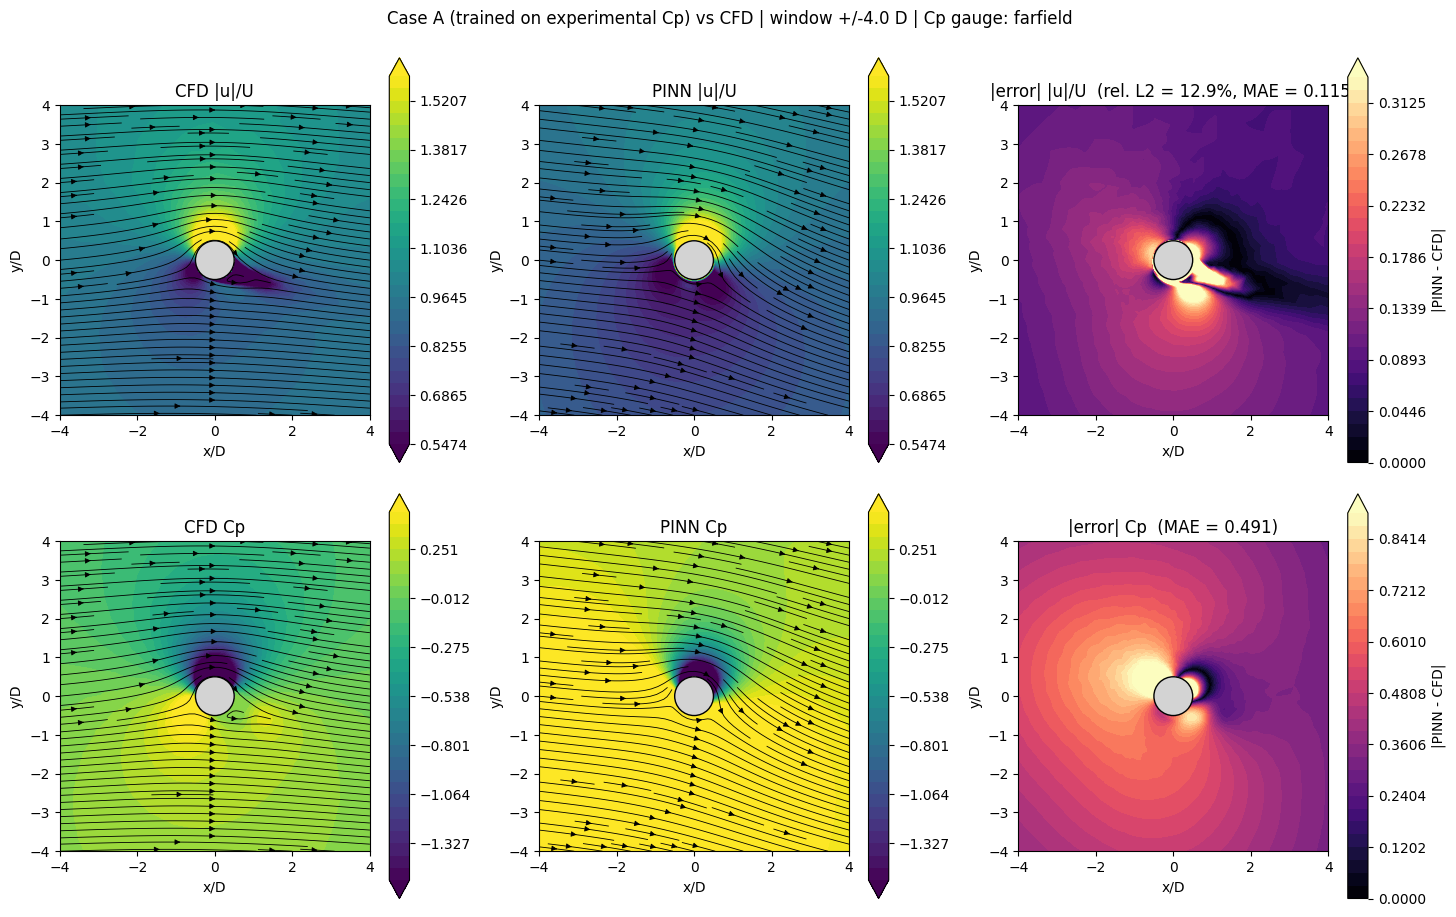

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD_ncp30_s0_fields_uvp_ext4.png


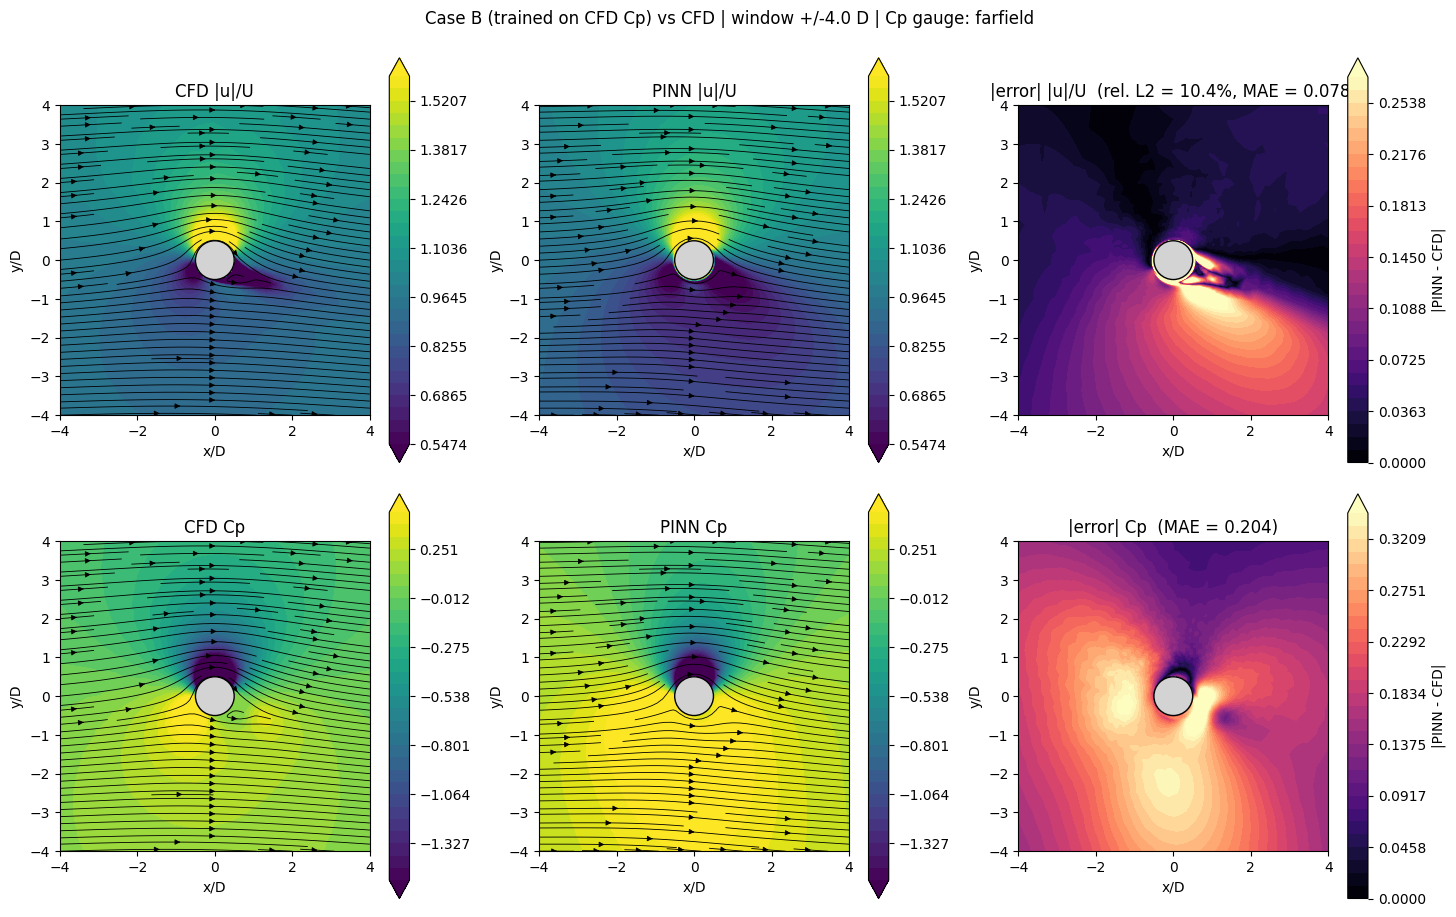

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD2_ncp60_s0_fields_uvp_ext4.png


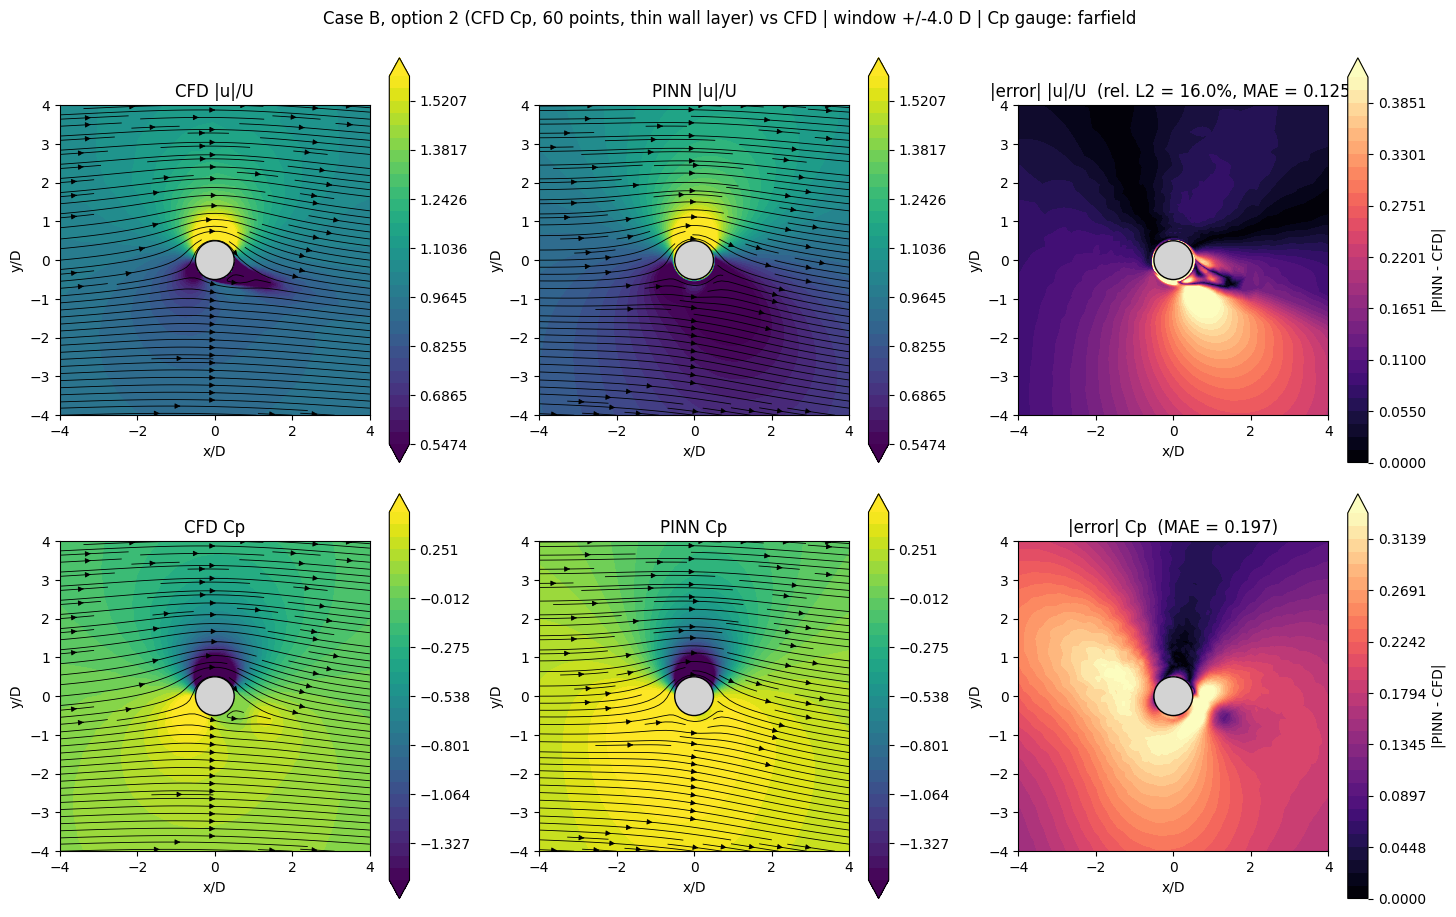

In [9]:
def add_streams(ax, X, Y, U, V, inside):
    Us = np.where(inside | ~np.isfinite(U), 0.0, U); Vs = np.where(inside | ~np.isfinite(V), 0.0, V)
    ax.streamplot(X[0, :], Y[:, 0], Us, Vs, density=STREAM_DENSITY, color=STREAM_COLOR, linewidth=STREAM_LW, arrowsize=0.8)

def compare_figure(run_key=CMP_RUN, save=True):
    r = RUNS[run_key]; cfg, model = r["cfg"], r["model"]
    xg = np.linspace(-EXTENT, EXTENT, NGRID); X, Y = np.meshgrid(xg, xg)
    inside = np.hypot(X, Y) < cfg.R_IN
    ref = cfd_at(X, Y)
    pf = pinn_fields(model, cfg, X.ravel(), Y.ravel())
    pred = {k: v.reshape(X.shape) for k, v in pf.items()}
    pred["pressure"] = pred["pressure"] - gauge_shift(pinn_fields(model, cfg, cfd["x"], cfd["y"]))

    fields = [f for f in FIELDS if cfd["has_vel"] or f in ("speed", "pressure")]
    ncol = 2 + len(ERR_SHOW)
    fig, axes = plt.subplots(len(fields), ncol, figsize=(4.9 * ncol, 4.6 * len(fields)), squeeze=False)
    labels = dict(speed="|u|/U", u="u/U", v="v/U", pressure="Cp")
    for row, name in enumerate(fields):
        a, b = ref[name].copy(), pred[name].copy()
        a[inside] = np.nan; b[inside] = np.nan
        ok = np.isfinite(a)
        lo, hi = np.percentile(a[ok], [1, 99]); levels = np.linspace(lo, hi, 31)
        err = np.where(ok, b - a, np.nan)
        c0 = axes[row, 0].contourf(X, Y, np.ma.masked_invalid(a), levels=levels, cmap="viridis", extend="both")
        c1 = axes[row, 1].contourf(X, Y, np.ma.masked_invalid(b), levels=levels, cmap="viridis", extend="both")
        fig.colorbar(c0, ax=axes[row, 0]); fig.colorbar(c1, ax=axes[row, 1])
        axes[row, 0].set_title(f"CFD {labels[name]}"); axes[row, 1].set_title(f"PINN {labels[name]}")
        mae = np.nanmean(np.abs(err)); rl2 = np.sqrt(np.nanmean(err ** 2)) / np.sqrt(np.nanmean(a ** 2))
        for j, mode in enumerate(ERR_SHOW):
            ax = axes[row, 2 + j]
            if mode == "abs":
                ep = np.abs(err); em = max(np.nanpercentile(ep, CLIP_PCT), 1e-9)
                c = ax.contourf(X, Y, np.ma.masked_invalid(ep), levels=np.linspace(0, em, 31), cmap="magma", extend="max")
                fig.colorbar(c, ax=ax, label="|PINN - CFD|")
                if name == "pressure":
                    ax.set_title(f"|error| {labels[name]}  (MAE = {mae:.3f})")
                else:
                    ax.set_title(f"|error| {labels[name]}  (rel. L2 = {rl2*100:.1f}%, MAE = {mae:.3f})")
            elif mode == "percent_of_range":
                ep = 100.0 * err / (hi - lo); em = max(np.nanpercentile(np.abs(ep), CLIP_PCT), 1e-9)
                c = ax.contourf(X, Y, np.ma.masked_invalid(ep), levels=np.linspace(-em, em, 31), cmap="RdBu_r", extend="both")
                fig.colorbar(c, ax=ax, label="% of CFD range"); ax.set_title(f"error, % of CFD range {labels[name]}")
            else:
                em = max(np.nanpercentile(np.abs(err), CLIP_PCT), 1e-9)
                c = ax.contourf(X, Y, np.ma.masked_invalid(err), levels=np.linspace(-em, em, 31), cmap="RdBu_r", extend="both")
                fig.colorbar(c, ax=ax, label="PINN - CFD"); ax.set_title(f"signed error {labels[name]}  (rel. L2 = {rl2*100:.1f}%)")
        if cfd["has_vel"]:
            if STREAM_ON_CFD:   add_streams(axes[row, 0], X, Y, ref["u"], ref["v"], inside)
            if STREAM_ON_ERROR:
                for j in range(len(ERR_SHOW)): add_streams(axes[row, 2 + j], X, Y, ref["u"], ref["v"], inside)
        if STREAM_ON_PINN: add_streams(axes[row, 1], X, Y, pred["u"], pred["v"], inside)
        for ax in axes[row]:
            ax.add_patch(plt.Circle((0, 0), cfg.R_IN, facecolor="lightgray", edgecolor="k", zorder=5))
            ax.set_xlim(-EXTENT, EXTENT); ax.set_ylim(-EXTENT, EXTENT); ax.set_aspect("equal"); ax.set_xlabel("x/D"); ax.set_ylabel("y/D")
    case = {"full_e_ncp30": "Case A (trained on experimental Cp)", "full_ecfd_ncp30": "Case B (trained on CFD Cp)",
            "full_ecfd2_ncp60": "Case B, option 2 (CFD Cp, 60 points, thin wall layer)"}.get(run_key, cfg.run_id)
    fig.suptitle(f"{case} vs CFD | window +/-{EXTENT} D | Cp gauge: {P_GAUGE}", y=1.0)
    plt.tight_layout()
    if save:
        path = f"{OUT_DIR}/diag_{cfg.run_id}_fields_uvp_ext{EXTENT:g}.png"; fig.savefig(path, dpi=200, bbox_inches="tight"); print("saved:", path)
    return fig

for _key in CASES:
    if _key in RUNS:
        compare_figure(_key); plt.show()
    else:
        print("not loaded, skipped:", _key)

### 5.3  Line profiles

Wake centreline (y = 0), wake cross-sections, wall check and far-field check. Solid lines are CFD, dashed lines are the PINN. Speed is |u|/U, pressure is Cp.

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_profiles.png


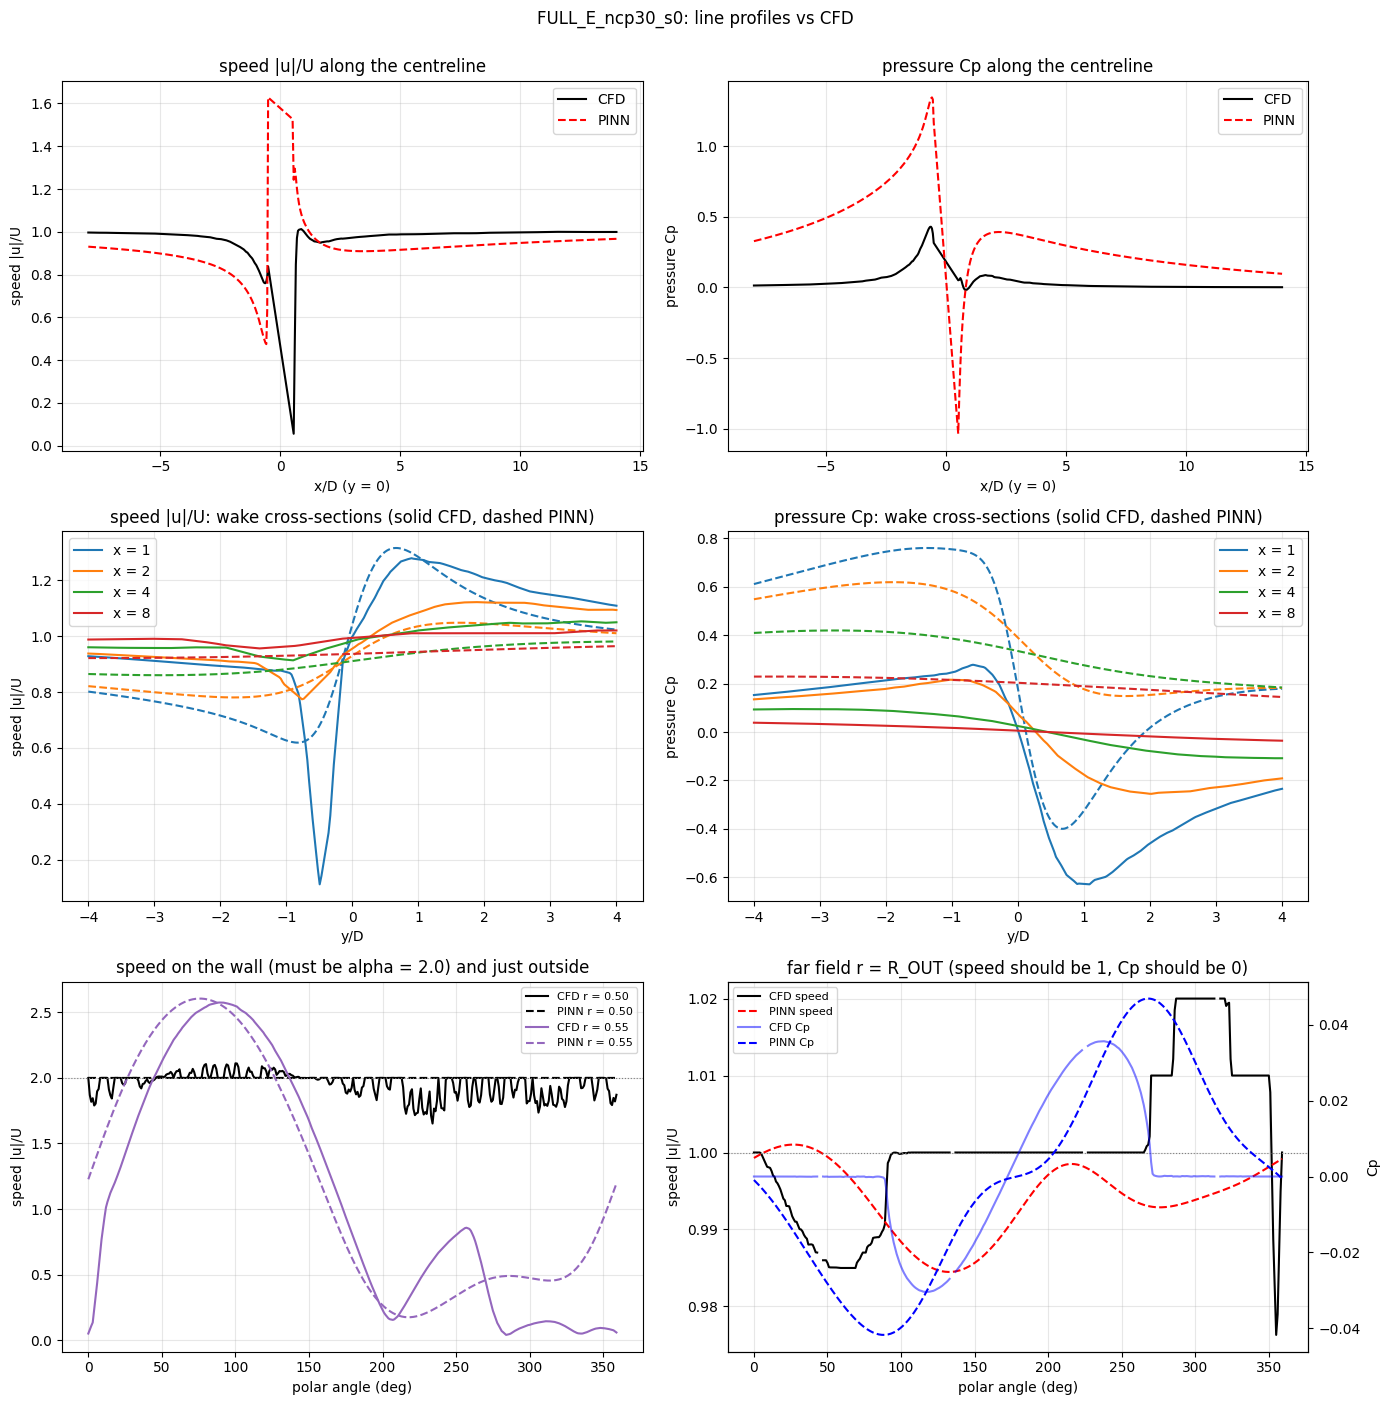

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_profiles.png


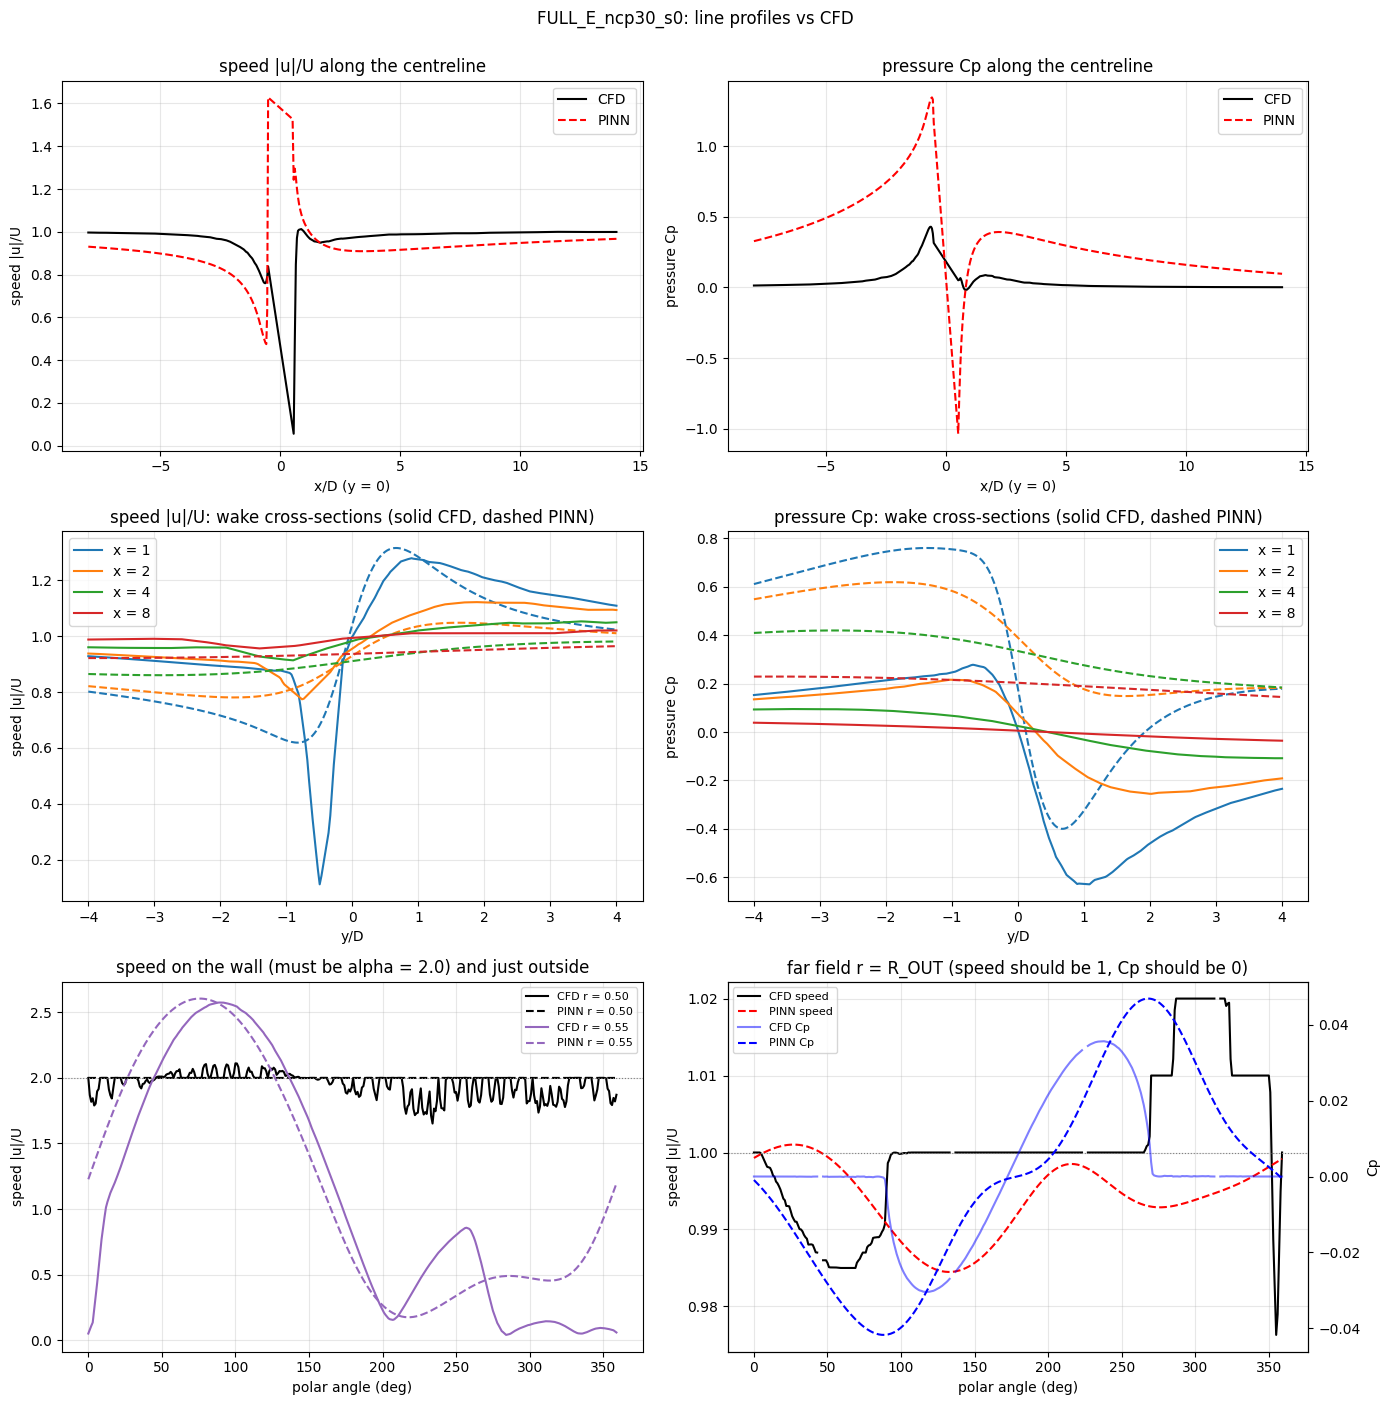

In [10]:
def profiles_figure(run_key=CMP_RUN, save=True):
    r = RUNS[run_key]; cfg, model = r["cfg"], r["model"]
    pn_nodes = pinn_fields(model, cfg, cfd["x"], cfd["y"]); shift = 0.0   # line profiles always use the far-field reference (PINN Cp = 0 on r = 25D, as in training and in the CFD)
    def P(x, y):
        f = pinn_fields(model, cfg, np.ravel(x), np.ravel(y)); f["pressure"] = f["pressure"] - shift; return f

    fig, ax = plt.subplots(3, 2, figsize=(14, 14))
    # (a), (b) along y = 0
    xs = np.concatenate([np.linspace(-8, -cfg.R_IN * 1.02, 200), np.linspace(cfg.R_IN * 1.02, 14, 300)])
    ys = np.zeros_like(xs); c = cfd_at(xs, ys); p = P(xs, ys)
    for k, (name, lab) in enumerate([("speed", "speed |u|/U"), ("pressure", "pressure Cp")]):
        a_ = ax[0, k]; a_.plot(xs, c[name], "k-", label="CFD"); a_.plot(xs, p[name], "r--", label="PINN")
        a_.set_xlabel("x/D (y = 0)"); a_.set_ylabel(lab); a_.set_title(f"{lab} along the centreline"); a_.grid(alpha=.3); a_.legend()
    # (c), (d) wake cross-sections
    cols = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    for k, (name, lab) in enumerate([("speed", "speed |u|/U"), ("pressure", "pressure Cp")]):
        a_ = ax[1, k]
        for xc, col in zip([1, 2, 4, 8], cols):
            yy = np.linspace(-4, 4, 300); xx = np.full_like(yy, float(xc))
            a_.plot(yy, cfd_at(xx, yy)[name], "-", color=col, label=f"x = {xc}")
            a_.plot(yy, P(xx, yy)[name], "--", color=col)
        a_.set_xlabel("y/D"); a_.set_ylabel(lab); a_.set_title(f"{lab}: wake cross-sections (solid CFD, dashed PINN)"); a_.grid(alpha=.3); a_.legend()
    # (e) wall and near-wall ring
    th = np.linspace(0, 2 * np.pi, 361)[:-1]
    for rr, col in [(cfg.R_IN, "k"), (cfg.R_IN * 1.1, "tab:purple")]:
        xr, yr = rr * np.cos(th), rr * np.sin(th)
        ax[2, 0].plot(np.degrees(th), cfd_at(xr, yr)["speed"], "-", color=col, label=f"CFD r = {rr:.2f}")
        ax[2, 0].plot(np.degrees(th), P(xr, yr)["speed"], "--", color=col, label=f"PINN r = {rr:.2f}")
    ax[2, 0].axhline(2.0, color="gray", lw=.8, ls=":"); ax[2, 0].set_xlabel("polar angle (deg)"); ax[2, 0].set_ylabel("speed |u|/U")
    ax[2, 0].set_title("speed on the wall (must be alpha = 2.0) and just outside"); ax[2, 0].grid(alpha=.3); ax[2, 0].legend(fontsize=8)
    # (f) far-field ring
    xr, yr = cfg.R_OUT * 0.999 * np.cos(th), cfg.R_OUT * 0.999 * np.sin(th)
    ax[2, 1].plot(np.degrees(th), cfd_at(xr, yr)["speed"], "k-", label="CFD speed"); ax[2, 1].plot(np.degrees(th), P(xr, yr)["speed"], "r--", label="PINN speed")
    ax2 = ax[2, 1].twinx()
    ax2.plot(np.degrees(th), cfd_at(xr, yr)["pressure"], "b-", alpha=.5, label="CFD Cp"); ax2.plot(np.degrees(th), P(xr, yr)["pressure"], "b--", label="PINN Cp")
    ax[2, 1].axhline(1.0, color="gray", lw=.8, ls=":"); ax[2, 1].set_xlabel("polar angle (deg)"); ax[2, 1].set_ylabel("speed |u|/U"); ax2.set_ylabel("Cp")
    ax[2, 1].set_title("far field r = R_OUT (speed should be 1, Cp should be 0)"); ax[2, 1].grid(alpha=.3)
    h1, l1 = ax[2, 1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax[2, 1].legend(h1 + h2, l1 + l2, fontsize=8)
    fig.suptitle(f"{cfg.run_id}: line profiles vs CFD", y=1.0); plt.tight_layout()
    if save:
        path = f"{OUT_DIR}/diag_{cfg.run_id}_profiles.png"; fig.savefig(path, dpi=200, bbox_inches="tight"); print("saved:", path)
    return fig

profiles_figure(); plt.show()

profiles_figure(); plt.show()

### 5.4  Wake decay: speed, Cp and total pressure along the wake

The wake of a lifting rotor is not on y = 0. For every x the CFD wake centre is taken as the point of lowest speed (searched between y = -6 and y = 2), and CFD and PINN are both read along that same curve. Top row: |u|/U, Cp and total-pressure coefficient H = Cp + |u|^2 - 1 along the wake (H is 0 in undisturbed flow and cannot be positive downstream of a body in a steady flow). Bottom row: absolute errors of |u|/U and Cp, and the path of the wake centre. If the PINN Cp does not return to 0 as CFD does, you see it here as a number.

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_wake_decay.png


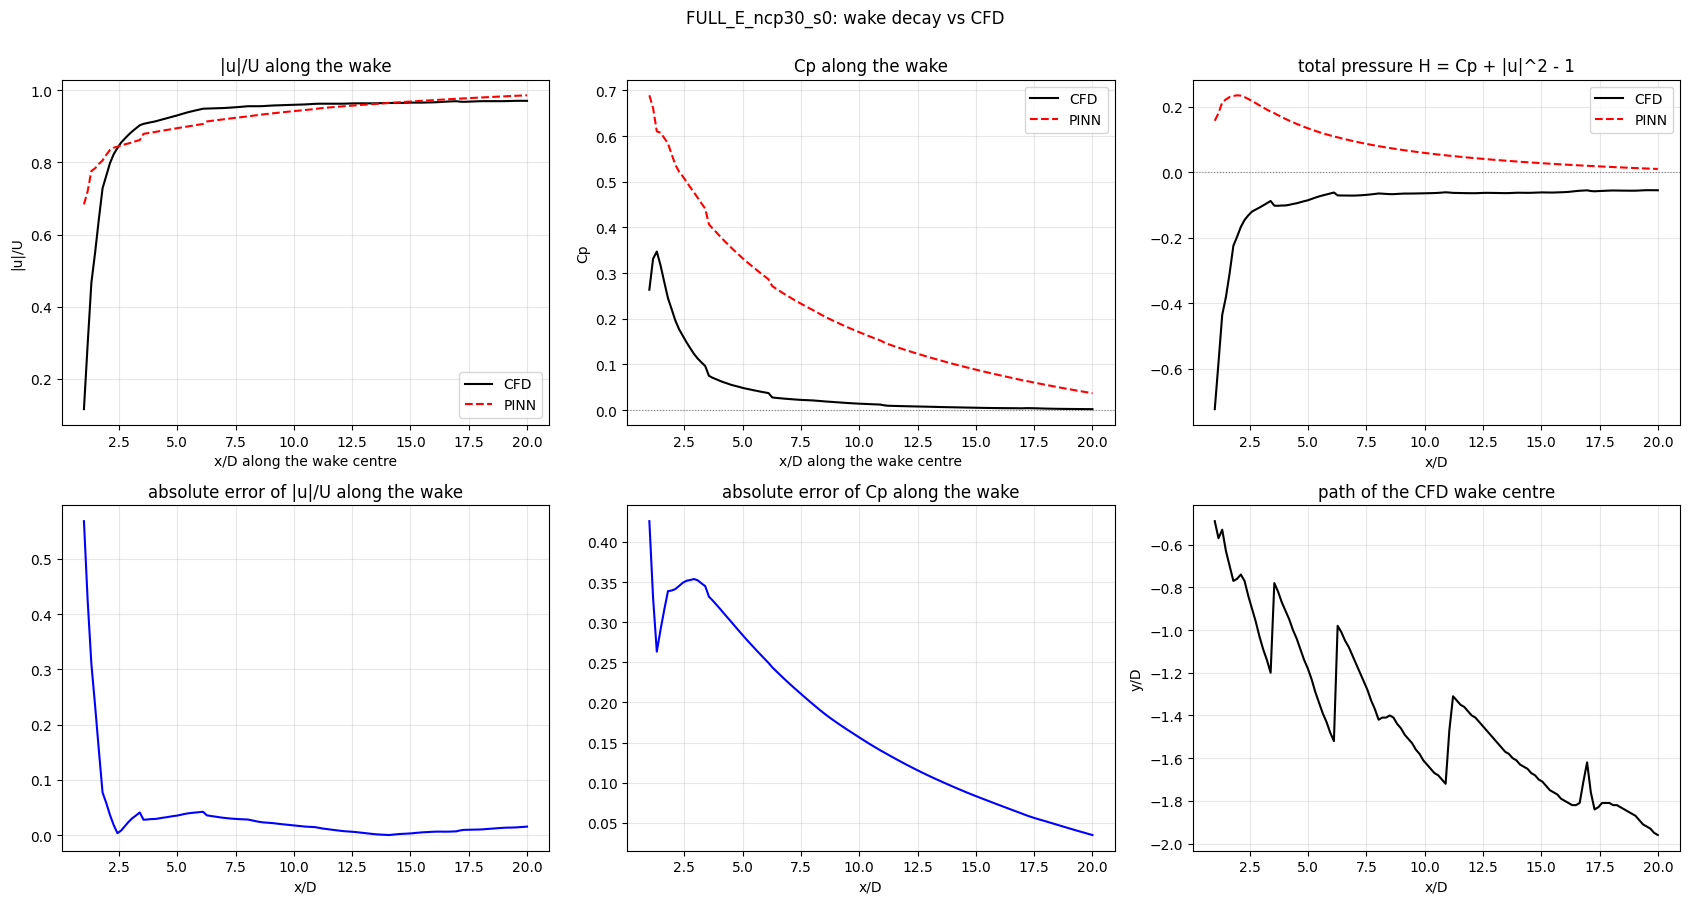

,x range (D),mean |err| |u|/U,mean |err| Cp,PINN Cp mean,CFD Cp mean
0,1-3,0.149,0.338,0.565,0.227
1,3-6,0.034,0.301,0.363,0.062
2,6-10,0.027,0.200,0.221,0.021
3,10-20,0.008,0.087,0.093,0.006


In [11]:
def wake_decay_figure(run_key=CMP_RUN, x_max=20.0, save=True):
    r = RUNS[run_key]; cfg, model = r["cfg"], r["model"]
    shift = 0.0   # far-field reference, so the decay towards Cp = 0 can be read directly
    xs = np.linspace(1.0, x_max, 120); yy = np.linspace(-6.0, 2.0, 801)
    yc = np.array([yy[np.nanargmin(cfd_at(np.full_like(yy, x), yy)["speed"])] for x in xs])
    c = cfd_at(xs, yc); p = pinn_fields(model, cfg, xs, yc); p["pressure"] = p["pressure"] - shift
    Hc = c["pressure"] + c["speed"] ** 2 - 1.0; Hp = p["pressure"] + p["speed"] ** 2 - 1.0
    fig, ax = plt.subplots(2, 3, figsize=(17, 9))
    for a, nm, lab in [(ax[0, 0], "speed", "|u|/U"), (ax[0, 1], "pressure", "Cp")]:
        a.plot(xs, c[nm], "k-", label="CFD"); a.plot(xs, p[nm], "r--", label="PINN"); a.set_xlabel("x/D along the wake centre"); a.set_ylabel(lab)
        a.set_title(f"{lab} along the wake"); a.grid(alpha=.3); a.legend()
    ax[0, 1].axhline(0.0, color="gray", lw=.8, ls=":")
    ax[0, 2].plot(xs, Hc, "k-", label="CFD"); ax[0, 2].plot(xs, Hp, "r--", label="PINN"); ax[0, 2].axhline(0, color="gray", lw=.8, ls=":")
    ax[0, 2].set_title("total pressure H = Cp + |u|^2 - 1"); ax[0, 2].set_xlabel("x/D"); ax[0, 2].grid(alpha=.3); ax[0, 2].legend()
    ax[1, 0].plot(xs, np.abs(p["speed"] - c["speed"]), "b-"); ax[1, 0].set_title("absolute error of |u|/U along the wake"); ax[1, 0].set_xlabel("x/D"); ax[1, 0].grid(alpha=.3)
    ax[1, 1].plot(xs, np.abs(p["pressure"] - c["pressure"]), "b-"); ax[1, 1].set_title("absolute error of Cp along the wake"); ax[1, 1].set_xlabel("x/D"); ax[1, 1].grid(alpha=.3)
    ax[1, 2].plot(xs, yc, "k-"); ax[1, 2].set_title("path of the CFD wake centre"); ax[1, 2].set_xlabel("x/D"); ax[1, 2].set_ylabel("y/D"); ax[1, 2].grid(alpha=.3)
    fig.suptitle(f"{cfg.run_id}: wake decay vs CFD", y=1.0); plt.tight_layout()
    bins = [(1, 3), (3, 6), (6, 10), (10, 20.01)]
    sel = lambda lo, hi: (xs >= lo) & (xs < hi)
    tab = pd.DataFrame({"x range (D)": [f"{lo}-{int(hi)}" for lo, hi in bins],
        "mean |err| |u|/U": [np.mean(np.abs(p["speed"] - c["speed"])[sel(lo, hi)]) for lo, hi in bins],
        "mean |err| Cp":    [np.mean(np.abs(p["pressure"] - c["pressure"])[sel(lo, hi)]) for lo, hi in bins],
        "PINN Cp mean":     [np.mean(p["pressure"][sel(lo, hi)]) for lo, hi in bins],
        "CFD Cp mean":      [np.mean(c["pressure"][sel(lo, hi)]) for lo, hi in bins]})
    if save:
        path = f"{OUT_DIR}/diag_{cfg.run_id}_wake_decay.png"; fig.savefig(path, dpi=200, bbox_inches="tight"); print("saved:", path)
        tab.to_csv(f"{OUT_DIR}/diag_{cfg.run_id}_wake_decay.csv", index=False)
    return fig, tab

_fig, _tab = wake_decay_figure(); plt.show()
display(_tab.round(3))

### 5.5  Error table by region

`MAE` is the mean absolute error (same units as u/U or Cp), `relL2` the relative L2 error, `bias` the mean of PINN minus CFD. A bias far from zero with a small relL2 means an offset, not a wrong pattern. Evaluated on the CFD nodes, no interpolation.

In [12]:
def region_table(run_key=CMP_RUN, save=True):
    r = RUNS[run_key]; cfg, model = r["cfg"], r["model"]
    pr = pinn_fields(model, cfg, cfd["x"], cfd["y"]); pr["pressure"] = pr["pressure"] - gauge_shift(pr)
    x, y = cfd["x"], cfd["y"]; rad = np.hypot(x, y)
    regions = {
        "whole domain":              np.ones(len(x), bool),
        "near wall r<1":             rad < 1.0,
        "near wall r<2":             rad < 2.0,
        "upstream x<-1, r<6":        (x < -1.0) & (rad < 6.0),
        "wake x 1-8, |y|<1.5":       (x >= 1.0) & (x <= 8.0) & (np.abs(y) < 1.5),
        "wide wake x 1-15, |y|<3":   (x >= 1.0) & (x <= 15.0) & (np.abs(y) < 3.0),
        "far field r>10":            rad > 10.0,
    }
    names = ["speed", "pressure"] + (["u", "v"] if cfd["has_vel"] else [])
    rows = []
    for rn, m in regions.items():
        row = {"region": rn, "n_nodes": int(m.sum())}
        for n in names:
            d = pr[n][m] - cfd[n][m]
            row[f"{n}_MAE"] = float(np.mean(np.abs(d)))
            row[f"{n}_relL2"] = float(np.sqrt(np.mean(d ** 2)) / (np.sqrt(np.mean(cfd[n][m] ** 2)) + 1e-12))
            row[f"{n}_bias"] = float(np.mean(d))
        rows.append(row)
    df = pd.DataFrame(rows)
    # boundary condition checks
    th = np.linspace(0, 2 * np.pi, 360, endpoint=False)
    wall = pinn_fields(model, cfg, cfg.R_IN * np.cos(th), cfg.R_IN * np.sin(th))
    ff = pinn_fields(model, cfg, cfg.R_OUT * np.cos(th), cfg.R_OUT * np.sin(th))
    print(f"PINN wall speed:  mean = {wall['speed'].mean():.3f}, min = {wall['speed'].min():.3f}, max = {wall['speed'].max():.3f}   (target {cfg.ALPHA:.2f})")
    print(f"PINN far-field:   mean speed = {ff['speed'].mean():.3f} (std {ff['speed'].std():.3f}),  Cp mean = {ff['pressure'].mean():.4f} (std {ff['pressure'].std():.4f})   (targets 1 and 0)")
    if save:
        path = f"{OUT_DIR}/diag_{cfg.run_id}_region_errors.csv"; df.to_csv(path, index=False); print("saved:", path)
    return df

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
display(region_table().round(3))

PINN wall speed:  mean = 2.000, min = 2.000, max = 2.000   (target 2.00)
PINN far-field:   mean speed = 0.994 (std 0.005),  Cp mean = 0.0000 (std 0.0265)   (targets 1 and 0)
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_region_errors.csv


,region,n_nodes,speed_MAE,speed_relL2,speed_bias,pressure_MAE,pressure_relL2,pressure_bias,u_MAE,u_relL2,u_bias,v_MAE,v_relL2,v_bias
0,whole domain,14319,0.170,0.270,0.034,0.414,0.413,0.254,0.125,0.235,-0.105,0.163,0.645,-0.103
1,near wall r<1,6347,0.336,0.347,0.121,0.773,0.402,0.414,0.230,0.319,-0.187,0.300,0.635,-0.169
2,near wall r<2,6652,0.328,0.343,0.110,0.764,0.405,0.421,0.227,0.315,-0.185,0.297,0.637,-0.171
3,"upstream x<-1, r<6",240,0.125,0.132,-0.125,0.561,3.074,0.561,0.119,0.124,-0.119,0.173,1.136,-0.173
4,"wake x 1-8, |y|<1.5",164,0.073,0.114,-0.011,0.297,1.591,0.297,0.122,0.142,-0.103,0.236,1.130,-0.236
5,"wide wake x 1-15, |y|<3",463,0.060,0.084,-0.038,0.235,1.877,0.235,0.088,0.107,-0.081,0.144,1.199,-0.144
6,far field r>10,6423,0.024,0.028,-0.023,0.070,3.236,0.067,0.025,0.030,-0.024,0.031,1.370,-0.026


### 5.6  Does the PINN satisfy its own equations?

Top row: the PINN's own continuity and momentum residuals (computed exactly as in training, with the SST eddy viscosity the network predicts) and the predicted eddy-viscosity ratio nu_t/nu (shown as log10 of 1 + ratio). Bottom row: the speed error and the pressure error from 5.2, placed under the residuals so you can compare where they are large. Residuals are shown as log10 of the magnitude. Residuals are measured on the PINN only; the CFD field is not tested against the PINN equations because the Fluent export has no k or omega.

median |momentum residual|: wake region = 2.83e-02, rest of window (r>3) = 2.79e-02
median |continuity residual|: wake region = 2.39e-02, rest of window (r>3) = 2.33e-02
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_residuals_ext4.png


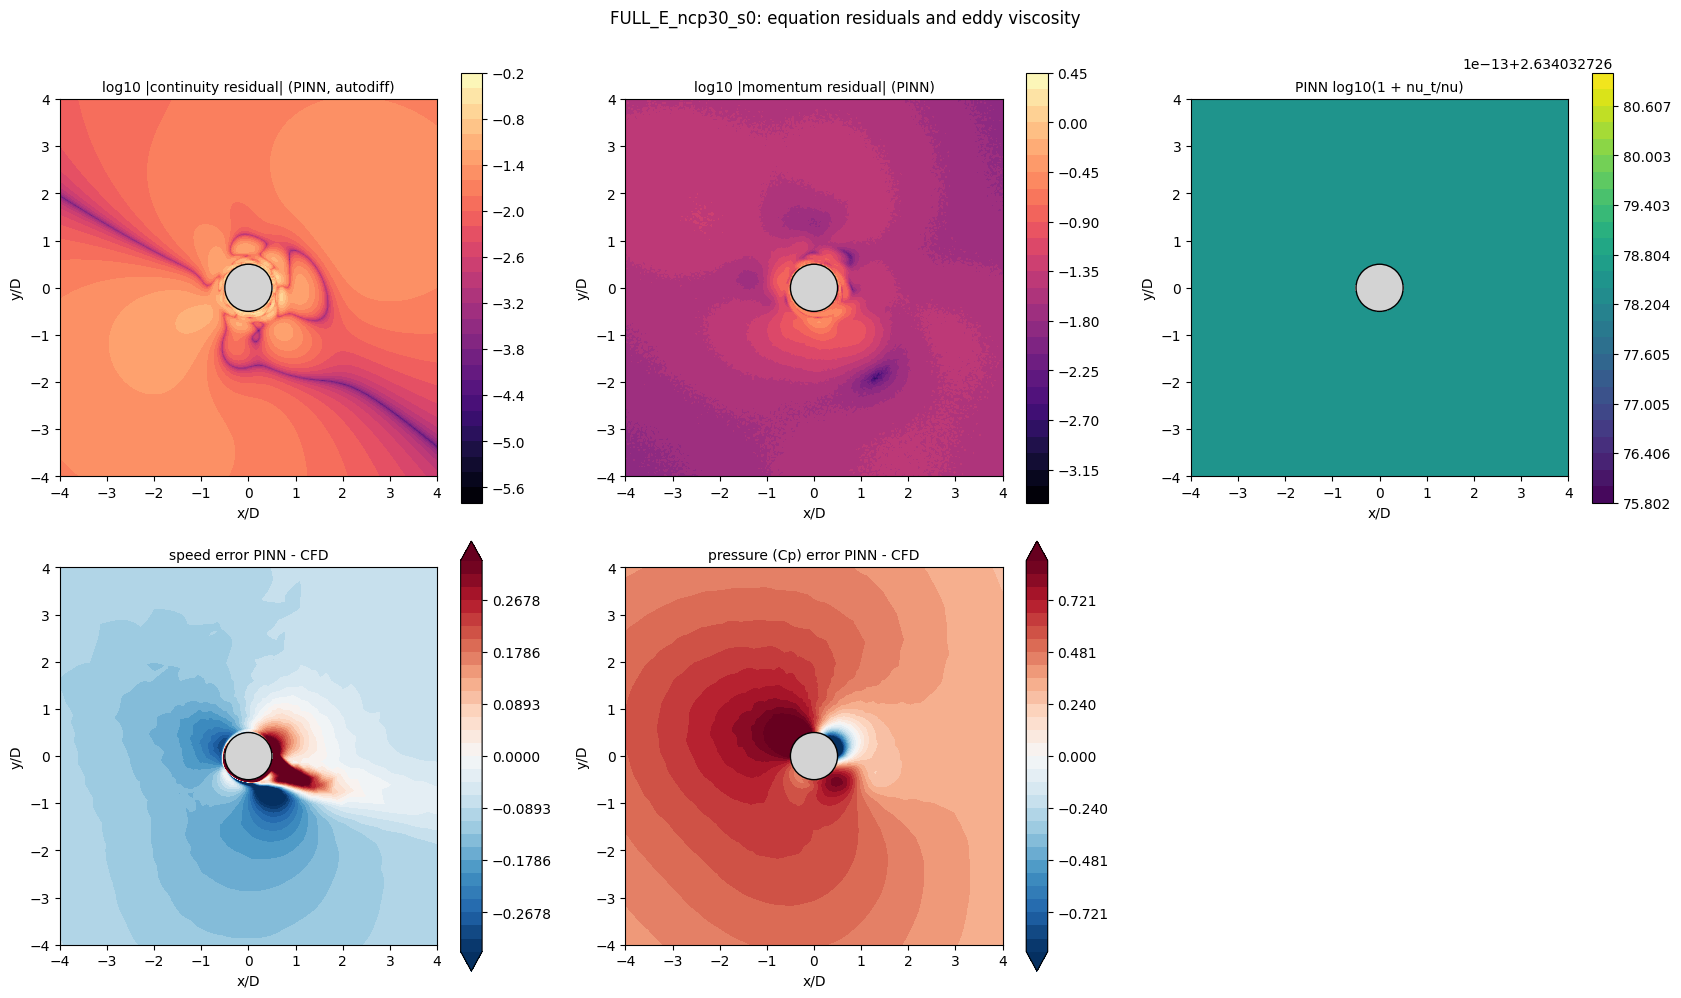

In [13]:
def pinn_residuals(model, cfg, x, y, eps=1e-3, chunk=10000):
    """continuity, momentum-x, momentum-y residuals and nu_t/nu, same formulas as the training loop (full turbulence)."""
    mk = make_input_fn(cfg); C = make_turb_constants(cfg)
    rc, rx, ry, nut = [], [], [], []
    for i in range(0, len(x), chunk):
        xi = x[i:i+chunk].reshape(-1, 1).astype(np.float32); yi = y[i:i+chunk].reshape(-1, 1).astype(np.float32)
        xy = tf.Variable(mk(xi, yi), trainable=False, dtype=tf.float32)
        with tf.GradientTape(persistent=True) as t:
            t.watch(xy)
            out = model(xy, training=False); uvp = get_uvp(out); ko = get_ko(out)
            u, v, p = uvp[:, 0:1], uvp[:, 1:2], uvp[:, 2:3]
        du = t.gradient(u, xy); dv = t.gradient(v, xy); dp = t.gradient(p, xy); del t
        n = xi.shape[0]
        dX = tf.constant(np.hstack([np.full((n, 1), eps), np.zeros((n, 1)), np.zeros((n, 1))]).astype(np.float32))
        dY = tf.constant(np.hstack([np.zeros((n, 1)), np.full((n, 1), eps), np.zeros((n, 1))]).astype(np.float32))
        uxp = get_uvp(model(xy + dX, training=False)); uxm = get_uvp(model(xy - dX, training=False))
        uyp = get_uvp(model(xy + dY, training=False)); uym = get_uvp(model(xy - dY, training=False))
        ie2 = 1.0 / eps ** 2
        d2u = (uxp[:, 0:1] - 2 * u + uxm[:, 0:1]) * ie2 + (uyp[:, 0:1] - 2 * u + uym[:, 0:1]) * ie2
        d2v = (uxp[:, 1:2] - 2 * v + uxm[:, 1:2]) * ie2 + (uyp[:, 1:2] - 2 * v + uym[:, 1:2]) * ie2
        nu_eff = tf.constant(nu_eff_of(model, cfg, ko)); nu_t = nu_eff - C["NU"]
        rc.append((du[:, 0:1] + dv[:, 1:2]).numpy())
        rx.append((u * du[:, 0:1] + v * du[:, 1:2] + dp[:, 0:1] - nu_eff * d2u).numpy())
        ry.append((u * dv[:, 0:1] + v * dv[:, 1:2] + dp[:, 1:2] - nu_eff * d2v).numpy())
        nut.append((nu_t / C["NU"]).numpy())
    f = lambda a: np.vstack(a).ravel()
    return f(rc), f(rx), f(ry), f(nut)

def residual_figure(run_key=CMP_RUN, save=True):
    r = RUNS[run_key]; cfg, model = r["cfg"], r["model"]
    xg = np.linspace(-EXTENT, EXTENT, NGRID); X, Y = np.meshgrid(xg, xg); inside = np.hypot(X, Y) < cfg.R_IN
    rc, rx, ry, nut = [a.reshape(X.shape) for a in pinn_residuals(model, cfg, X.ravel(), Y.ravel())]
    pf = pinn_fields(model, cfg, X.ravel(), Y.ravel())
    shift = gauge_shift(pinn_fields(model, cfg, cfd["x"], cfd["y"]))
    ref = cfd_at(X, Y)
    lg = lambda a: np.where(inside, np.nan, np.log10(np.abs(a) + 1e-12))
    mom = np.hypot(rx, ry)
    fig, ax = plt.subplots(2, 3, figsize=(17, 10))
    panels = [(ax[0, 0], lg(rc), "log10 |continuity residual| (PINN, autodiff)", "magma"),
              (ax[0, 1], lg(mom), "log10 |momentum residual| (PINN)", "magma"),
              (ax[0, 2], np.where(inside, np.nan, np.log10(nut + 1.0)), "PINN log10(1 + nu_t/nu)", "viridis")]
    sp_err = np.where(inside, np.nan, pf["speed"].reshape(X.shape) - ref["speed"])
    p_err = np.where(inside, np.nan, pf["pressure"].reshape(X.shape) - shift - ref["pressure"])
    panels += [(ax[1, 0], sp_err, "speed error PINN - CFD", "RdBu_r"),
               (ax[1, 1], p_err, "pressure (Cp) error PINN - CFD", "RdBu_r")]
    for a, f, title, cm in panels:
        f = np.ma.masked_invalid(f)
        if cm == "RdBu_r":
            m_ = np.nanpercentile(np.abs(f.filled(np.nan)), 99); c = a.contourf(X, Y, f, levels=np.linspace(-m_, m_, 31), cmap=cm, extend="both")
        else:
            c = a.contourf(X, Y, f, levels=30, cmap=cm)
        fig.colorbar(c, ax=a); a.set_title(title, fontsize=10)
        a.add_patch(plt.Circle((0, 0), cfg.R_IN, facecolor="lightgray", edgecolor="k", zorder=5))
        a.set_xlim(-EXTENT, EXTENT); a.set_ylim(-EXTENT, EXTENT); a.set_aspect("equal"); a.set_xlabel("x/D"); a.set_ylabel("y/D")
    ax[1, 2].axis("off")
    fig.suptitle(f"{cfg.run_id}: equation residuals and eddy viscosity", y=1.0); plt.tight_layout()
    # numbers in the wake region
    wake = (X >= 1) & (X <= 8) & (np.abs(Y) < 1.5) & ~inside
    far = (np.hypot(X, Y) > 3) & ~inside
    print(f"median |momentum residual|: wake region = {np.median(mom[wake]):.2e}, rest of window (r>3) = {np.median(mom[far]):.2e}")
    print(f"median |continuity residual|: wake region = {np.median(np.abs(rc[wake])):.2e}, rest of window (r>3) = {np.median(np.abs(rc[far])):.2e}")
    if save:
        path = f"{OUT_DIR}/diag_{cfg.run_id}_residuals_ext{EXTENT:g}.png"; fig.savefig(path, dpi=200, bbox_inches="tight"); print("saved:", path)
    return fig

residual_figure(); plt.show()

### 5.7  Force audit: is the CFD itself consistent with the wind tunnel?

The net force on the rotor can be computed on any circle of radius R around it from the momentum theorem (force on body = minus the integral over the circle of momentum flux + pressure - viscous stress). In a steady, correct flow the answer must not depend on R, and at R = 0.5 it must equal the force from the wall pressure. Three curves are drawn against R:

- CFD circle: velocity and pressure interpolated from the Fluent export (viscous stress neglected; it is tiny away from the wall).
- PINN circle: same formula on the PINN field, without eddy stress.
- PINN circle + eddy stress: same, with the modelled stress nu_eff x (grad u + grad u transposed).

Horizontal lines: the wall-integral values of the PINN run and the wind-tunnel values. Reading it: if the CFD curve is flat but far below the wind-tunnel drag, the CFD and the experiment are not the same physical flow, so CFD cannot be used as the truth for the drag-carrying wake. If the PINN curve changes strongly with R, the PINN field is not momentum-consistent (it does not satisfy its own equations in integral form).

Wind tunnel (Bordogna):  CL = 5.917   CD = 1.745
PINN wall integral:      CL = 5.208   CD = 1.939
saved: diag_FULL_E_ncp30_s0_force_audit.(png/csv)


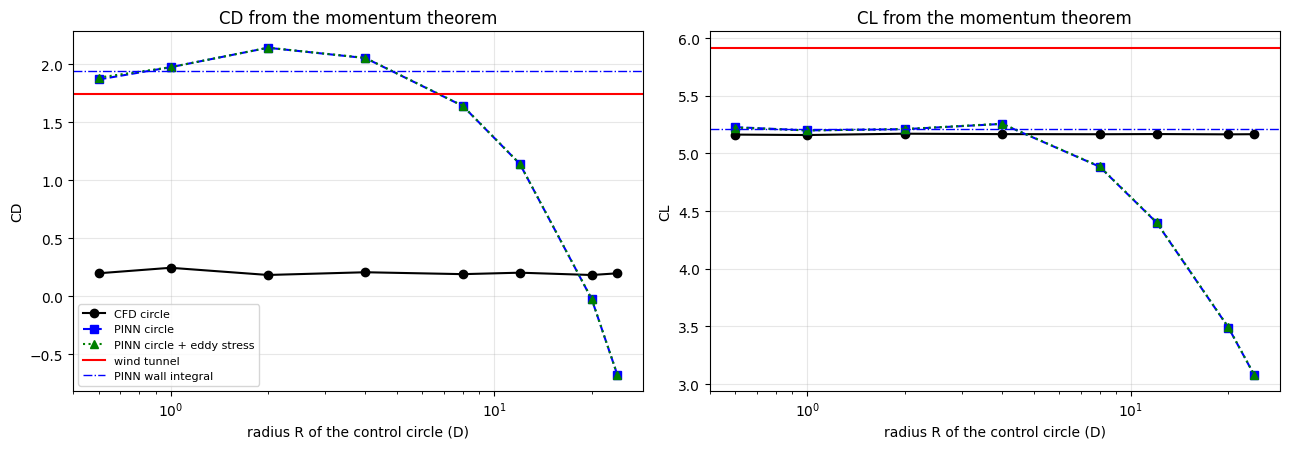

,R,CFD_CD,CFD_CL,PINN_CD,PINN_CL,PINN_eddy_CD,PINN_eddy_CL
0,0.6,0.199,5.163,1.870,5.228,1.886,5.224
1,1.0,0.246,5.160,1.975,5.200,1.976,5.200
2,2.0,0.184,5.171,2.143,5.210,2.144,5.211
3,4.0,0.207,5.167,2.054,5.256,2.056,5.258
4,8.0,0.191,5.166,1.641,4.885,1.642,4.887
5,12.0,0.204,5.168,1.141,4.400,1.143,4.402
6,20.0,0.184,5.165,-0.024,3.489,-0.023,3.491
7,24.0,0.198,5.167,-0.677,3.080,-0.675,3.082


In [14]:
def _ring_points(Rc, n):
    th = np.linspace(0, 2 * np.pi, n, endpoint=False)
    return th, np.cos(th), np.sin(th), Rc * np.cos(th), Rc * np.sin(th), 2 * np.pi * Rc / n

def cfd_ring_forces(Rc, n=1440):
    th, nx, ny, x, y, ds = _ring_points(Rc, n)
    f = cfd_at(x, y); u, v, p = f["u"], f["v"], f["pressure"] / 2.0       # p = Cp/2 (rho = U = 1)
    un = u * nx + v * ny
    Fx = -np.nansum(u * un + p * nx) * ds
    Fy = -np.nansum(v * un + p * ny) * ds
    return Fx / 0.5, Fy / 0.5                                               # (CD, CL), D = 1

def pinn_ring_forces(model, cfg, Rc, n=1440):
    th, nx, ny, x, y, ds = _ring_points(Rc, n)
    mk = make_input_fn(cfg); C = make_turb_constants(cfg)
    xy = tf.Variable(mk(x.reshape(-1, 1).astype(np.float32), y.reshape(-1, 1).astype(np.float32)), trainable=False, dtype=tf.float32)
    with tf.GradientTape(persistent=True) as t:
        t.watch(xy)
        out = model(xy, training=False); uvp = get_uvp(out); ko = get_ko(out)
        u_, v_ = uvp[:, 0:1], uvp[:, 1:2]
    du = t.gradient(u_, xy).numpy(); dv = t.gradient(v_, xy).numpy(); del t
    u = uvp[:, 0].numpy(); v = uvp[:, 1].numpy()
    p = uvp[:, 2].numpy() - pinn_pref(model, cfg)
    nu_eff = nu_eff_of(model, cfg, ko).ravel()
    un = u * nx + v * ny
    ax = -np.sum(u * un + p * nx) * ds; ay = -np.sum(v * un + p * ny) * ds
    tx = nu_eff * (2 * du[:, 0] * nx + (du[:, 1] + dv[:, 0]) * ny)
    ty = nu_eff * ((du[:, 1] + dv[:, 0]) * nx + 2 * dv[:, 1] * ny)
    bx = ax + np.sum(tx) * ds; by = ay + np.sum(ty) * ds                   # + tau.n term
    return (ax / 0.5, ay / 0.5), (bx / 0.5, by / 0.5)

def force_audit(run_key=CMP_RUN, radii=(0.6, 1, 2, 4, 8, 12, 20, 24), save=True):
    r = RUNS[run_key]; cfg, model, m = r["cfg"], r["model"], r["metrics"]
    rows = []
    for Rc in radii:
        c_cd, c_cl = cfd_ring_forces(Rc)
        (p_cd, p_cl), (e_cd, e_cl) = pinn_ring_forces(model, cfg, Rc)
        rows.append(dict(R=Rc, CFD_CD=c_cd, CFD_CL=c_cl, PINN_CD=p_cd, PINN_CL=p_cl, PINN_eddy_CD=e_cd, PINN_eddy_CL=e_cl))
    df = pd.DataFrame(rows)
    print(f"Wind tunnel (Bordogna):  CL = {data['cl_ref']:.3f}   CD = {data['cd_ref']:.3f}")
    print(f"PINN wall integral:      CL = {m['CL']:.3f}   CD = {m['CD']:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
    for a, nm, ref_val, wall_val in [(ax[0], "CD", data["cd_ref"], m["CD"]), (ax[1], "CL", data["cl_ref"], m["CL"])]:
        a.semilogx(df["R"], df["CFD_" + nm], "ko-", label="CFD circle")
        a.semilogx(df["R"], df["PINN_" + nm], "bs--", label="PINN circle")
        a.semilogx(df["R"], df["PINN_eddy_" + nm], "g^:", label="PINN circle + eddy stress")
        a.axhline(ref_val, color="r", lw=1.5, label="wind tunnel")
        a.axhline(wall_val, color="b", lw=1.0, ls="-.", label="PINN wall integral")
        a.set_xlabel("radius R of the control circle (D)"); a.set_ylabel(nm); a.set_title(nm + " from the momentum theorem"); a.grid(alpha=0.3)
    ax[0].legend(fontsize=8)
    plt.tight_layout()
    if save:
        df.to_csv(f"{OUT_DIR}/diag_{cfg.run_id}_force_audit.csv", index=False)
        fig.savefig(f"{OUT_DIR}/diag_{cfg.run_id}_force_audit.png", dpi=200, bbox_inches="tight"); print("saved: diag_" + cfg.run_id + "_force_audit.(png/csv)")
    return df

_df_force = force_audit(); plt.show()
display(_df_force.round(3))

### 5.8  Eddy viscosity and total pressure

Eddy-viscosity table: nu_t/nu of the PINN at the CFD node locations, by region. `cap share` is the fraction of nodes sitting at the clip limit (the network is asking for more eddy viscosity than allowed). `Re_eff` is 1/(nu + nu_t), the effective Reynolds number the momentum equation sees there. At the true Re = 3.6e5, values of Re_eff of order 10 in the wake mean the PINN is solving an almost viscous creeping flow in the wake, which would give a smeared, too-wide wake.

Total-pressure figure: H = Cp + |u|^2 - 1. It is zero in the undisturbed flow and can only be negative downstream of a body in steady flow (the body removes total pressure). Large positive H far from the rotor, or positive H anywhere in the wake, is not physical and shows the pressure and velocity of the PINN do not belong together.

molecular Re = 3.6e+05; eddy-viscosity cap = 0.1 (ratio 36000)


,region,n,nut/nu median,nut/nu p90,nut/nu p99,cap share,Re_eff median
0,all nodes,14319,429.55899,429.55899,429.55899,0.0,836.122
1,wall layer r<0.6,3068,429.55899,429.55899,429.55899,0.0,836.122
2,near r<2,6652,429.55899,429.55899,429.55899,0.0,836.122
3,"wake x 1-8, |y|<1.5",164,429.55899,429.55899,429.55899,0.0,836.122
4,"lower half y<-1, r<10",608,429.55899,429.55899,429.55899,0.0,836.122
5,far r>10,6423,429.55899,429.55899,429.55899,0.0,836.122


fraction of window (r>3) with H > +0.1:  CFD = 0.000   PINN = 1.000
saved total pressure figure


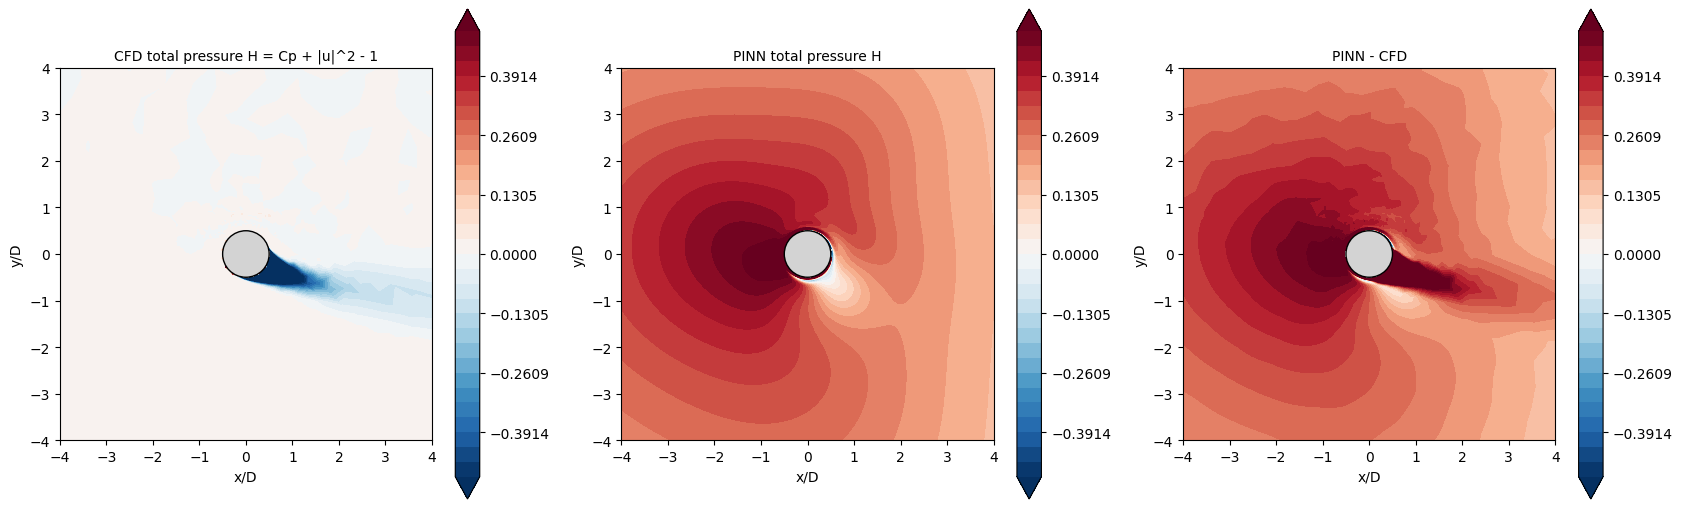

In [15]:
def pinn_ko(model, cfg, x, y, chunk=20000):
    mk = make_input_fn(cfg); out = []
    for i in range(0, len(x), chunk):
        xi = x[i:i+chunk].reshape(-1, 1).astype(np.float32); yi = y[i:i+chunk].reshape(-1, 1).astype(np.float32)
        out.append(get_ko(model(mk(xi, yi), training=False)).numpy())
    return np.vstack(out)

def nut_audit(run_key=CMP_RUN):
    r = RUNS[run_key]; cfg, model = r["cfg"], r["model"]; C = make_turb_constants(cfg)
    x, y = cfd["x"], cfd["y"]; rad = np.hypot(x, y)
    ko = pinn_ko(model, cfg, x, y)
    cap = getattr(cfg, "nut_max", 0.1)
    nut = nu_eff_of(model, cfg, ko).ravel() - float(C["NU"])
    ratio = nut / C["NU"]
    regions = {"all nodes": np.ones(len(x), bool), "wall layer r<0.6": rad < 0.6, "near r<2": rad < 2.0,
               "wake x 1-8, |y|<1.5": (x >= 1) & (x <= 8) & (np.abs(y) < 1.5),
               "lower half y<-1, r<10": (y < -1) & (rad < 10), "far r>10": rad > 10}
    rows = []
    for nm, mk_ in regions.items():
        q = ratio[mk_]
        rows.append({"region": nm, "n": int(mk_.sum()), "nut/nu median": np.median(q), "nut/nu p90": np.percentile(q, 90),
                     "nut/nu p99": np.percentile(q, 99), "cap share": float(np.mean(nut[mk_] >= 0.999 * cap)),
                     "Re_eff median": float(np.median(1.0 / (C["NU"] + nut[mk_])))})
    print(f"molecular Re = {1.0 / C['NU']:.3g}; eddy-viscosity cap = {cap} (ratio {cap / C['NU']:.0f})")
    return pd.DataFrame(rows)

def total_pressure_figure(run_key=CMP_RUN, save=True):
    r = RUNS[run_key]; cfg, model = r["cfg"], r["model"]
    xg = np.linspace(-EXTENT, EXTENT, NGRID); X, Y = np.meshgrid(xg, xg); inside = np.hypot(X, Y) < cfg.R_IN
    ref = cfd_at(X, Y)
    pf = pinn_fields(model, cfg, X.ravel(), Y.ravel())
    shift = gauge_shift(pinn_fields(model, cfg, cfd["x"], cfd["y"]))
    Hc = ref["pressure"] + ref["speed"] ** 2 - 1.0
    Hp = (pf["pressure"] - shift).reshape(X.shape) + pf["speed"].reshape(X.shape) ** 2 - 1.0
    Hc = np.where(inside, np.nan, Hc); Hp = np.where(inside, np.nan, Hp)
    m_ = np.nanpercentile(np.abs(np.concatenate([Hc[np.isfinite(Hc)], Hp[np.isfinite(Hp)]])), 99)
    lv = np.linspace(-m_, m_, 31)
    fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
    for a, f, t_ in [(ax[0], Hc, "CFD total pressure H = Cp + |u|^2 - 1"), (ax[1], Hp, "PINN total pressure H"), (ax[2], Hp - Hc, "PINN - CFD")]:
        c = a.contourf(X, Y, np.ma.masked_invalid(f), levels=lv, cmap="RdBu_r", extend="both"); fig.colorbar(c, ax=a); a.set_title(t_, fontsize=10)
        a.add_patch(plt.Circle((0, 0), cfg.R_IN, facecolor="lightgray", edgecolor="k", zorder=5))
        a.set_xlim(-EXTENT, EXTENT); a.set_ylim(-EXTENT, EXTENT); a.set_aspect("equal"); a.set_xlabel("x/D"); a.set_ylabel("y/D")
    plt.tight_layout()
    far = (np.hypot(X, Y) > 3) & ~inside
    print(f"fraction of window (r>3) with H > +0.1:  CFD = {np.nanmean(Hc[far] > 0.1):.3f}   PINN = {np.nanmean(Hp[far] > 0.1):.3f}")
    if save:
        fig.savefig(f"{OUT_DIR}/diag_{cfg.run_id}_total_pressure_ext{EXTENT:g}.png", dpi=200, bbox_inches="tight"); print("saved total pressure figure")
    return fig

display(nut_audit().round(3))
total_pressure_figure(); plt.show()

### 5.9  All diagnostics for one case

`diagnose("full_e_ncp30")` or `diagnose("full_ecfd_ncp30")` draws 5.2 to 5.8 for that case.


In [16]:
def diagnose(run_key):
    compare_figure(run_key); plt.show()
    profiles_figure(run_key); plt.show()
    f_, t_ = wake_decay_figure(run_key); plt.show(); display(t_.round(3))
    display(region_table(run_key).round(3))
    residual_figure(run_key); plt.show()
    force_audit(run_key); plt.show()
    display(nut_audit(run_key).round(3))
    total_pressure_figure(run_key); plt.show()

# used by 5.11 below

### 5.10  Final summary table for the manuscript (both cases, both pressure references)

`farfield`: Cp referenced to the mean far-field pressure (as in training).
`best_constant`: the constant offset between PINN and CFD pressure is removed first (shows the pattern error alone).
The table is saved as `final_summary_regions.csv` in OUT_DIR.

In [17]:
_gauge_saved = P_GAUGE
rows = []
for key in [k for k in CASES if k in RUNS]:
    for gauge in ["farfield", "best_constant"]:
        P_GAUGE = gauge
        t = region_table(key, save=False)
        t.insert(0, "case", RUNS[key]["label"]); t.insert(1, "pressure_reference", gauge)
        rows.append(t)
P_GAUGE = _gauge_saved
summary = pd.concat(rows, ignore_index=True)
cols = ["case", "pressure_reference", "region", "n_nodes", "speed_MAE", "u_MAE", "v_MAE", "pressure_MAE",
        "speed_relL2", "pressure_relL2", "pressure_bias"]
summary = summary[[c for c in cols if c in summary.columns]]
summary.to_csv(f"{OUT_DIR}/final_summary_regions.csv", index=False)
display(summary.round(3))

force_rows = []
for key in [k for k in CASES if k in RUNS]:
    m, d = RUNS[key]["metrics"], RUNS[key]["data"]
    force_rows.append(dict(case=RUNS[key]["label"], wall_Cp_MAE=m["MAE"], wall_Cp_MAE_no_shift=m["MAE_no_shift"],
                           CL=m["CL"], CL_ref=d["cl_ref"], CL_err_pct=100 * abs(m["CL"] - d["cl_ref"]) / d["cl_ref"],
                           CD=m["CD"], CD_ref=d["cd_ref"], CD_err_pct=100 * abs(m["CD"] - d["cd_ref"]) / d["cd_ref"],
                           Re_eff=float(core.re_eff_of(RUNS[key]["model"], RUNS[key]["cfg"]))))
forces = pd.DataFrame(force_rows); forces.to_csv(f"{OUT_DIR}/final_summary_forces.csv", index=False)
display(forces.round(3))

PINN wall speed:  mean = 2.000, min = 2.000, max = 2.000   (target 2.00)
PINN far-field:   mean speed = 0.994 (std 0.005),  Cp mean = 0.0000 (std 0.0265)   (targets 1 and 0)
PINN wall speed:  mean = 2.000, min = 2.000, max = 2.000   (target 2.00)
PINN far-field:   mean speed = 0.994 (std 0.005),  Cp mean = 0.0000 (std 0.0265)   (targets 1 and 0)
PINN wall speed:  mean = 2.000, min = 2.000, max = 2.000   (target 2.00)
PINN far-field:   mean speed = 1.000 (std 0.024),  Cp mean = -0.0000 (std 0.0261)   (targets 1 and 0)
PINN wall speed:  mean = 2.000, min = 2.000, max = 2.000   (target 2.00)
PINN far-field:   mean speed = 1.000 (std 0.024),  Cp mean = -0.0000 (std 0.0261)   (targets 1 and 0)
PINN wall speed:  mean = 2.000, min = 2.000, max = 2.000   (target 2.00)
PINN far-field:   mean speed = 0.994 (std 0.030),  Cp mean = -0.0000 (std 0.0259)   (targets 1 and 0)
PINN wall speed:  mean = 2.000, min = 2.000, max = 2.000   (target 2.00)
PINN far-field:   mean speed = 0.994 (std 0.030),  Cp 

,case,pressure_reference,region,n_nodes,speed_MAE,u_MAE,v_MAE,pressure_MAE,speed_relL2,pressure_relL2,pressure_bias
0,A: experimental Cp,farfield,whole domain,14319,0.170,0.125,0.163,0.414,0.270,0.413,0.254
1,A: experimental Cp,farfield,near wall r<1,6347,0.336,0.230,0.300,0.773,0.347,0.402,0.414
2,A: experimental Cp,farfield,near wall r<2,6652,0.328,0.227,0.297,0.764,0.343,0.405,0.421
3,A: experimental Cp,farfield,"upstream x<-1, r<6",240,0.125,0.119,0.173,0.561,0.132,3.074,0.561
4,A: experimental Cp,farfield,"wake x 1-8, |y|<1.5",164,0.073,0.122,0.236,0.297,0.114,1.591,0.297
5,A: experimental Cp,farfield,"wide wake x 1-15, |y|<3",463,0.060,0.088,0.144,0.235,0.084,1.877,0.235
6,A: experimental Cp,farfield,far field r>10,6423,0.024,0.025,0.031,0.070,0.028,3.236,0.067
7,A: experimental Cp,best_constant,whole domain,14319,0.170,0.125,0.163,0.383,0.270,0.375,-0.000
8,A: experimental Cp,best_constant,near wall r<1,6347,0.336,0.230,0.300,0.641,0.347,0.362,0.160
9,A: experimental Cp,best_constant,near wall r<2,6652,0.328,0.227,0.297,0.626,0.343,0.363,0.167


,case,wall_Cp_MAE,wall_Cp_MAE_no_shift,CL,CL_ref,CL_err_pct,CD,CD_ref,CD_err_pct,Re_eff
0,A: experimental Cp,0.047,0.034,5.208,5.917,11.978,1.939,1.745,11.162,836.122
1,B: CFD Cp (method check),0.051,0.030,5.244,5.145,1.930,0.314,0.182,72.400,902.152
2,"B2: CFD Cp, option 2",0.136,0.060,5.246,5.145,1.974,0.278,0.182,52.170,986.039


### 5.11  All figures for both cases

Saves the field comparison, line profiles, wake decay, force audit and total-pressure figures for both cases in OUT_DIR.


==================== A: experimental Cp ====================
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_fields_uvp_ext4.png


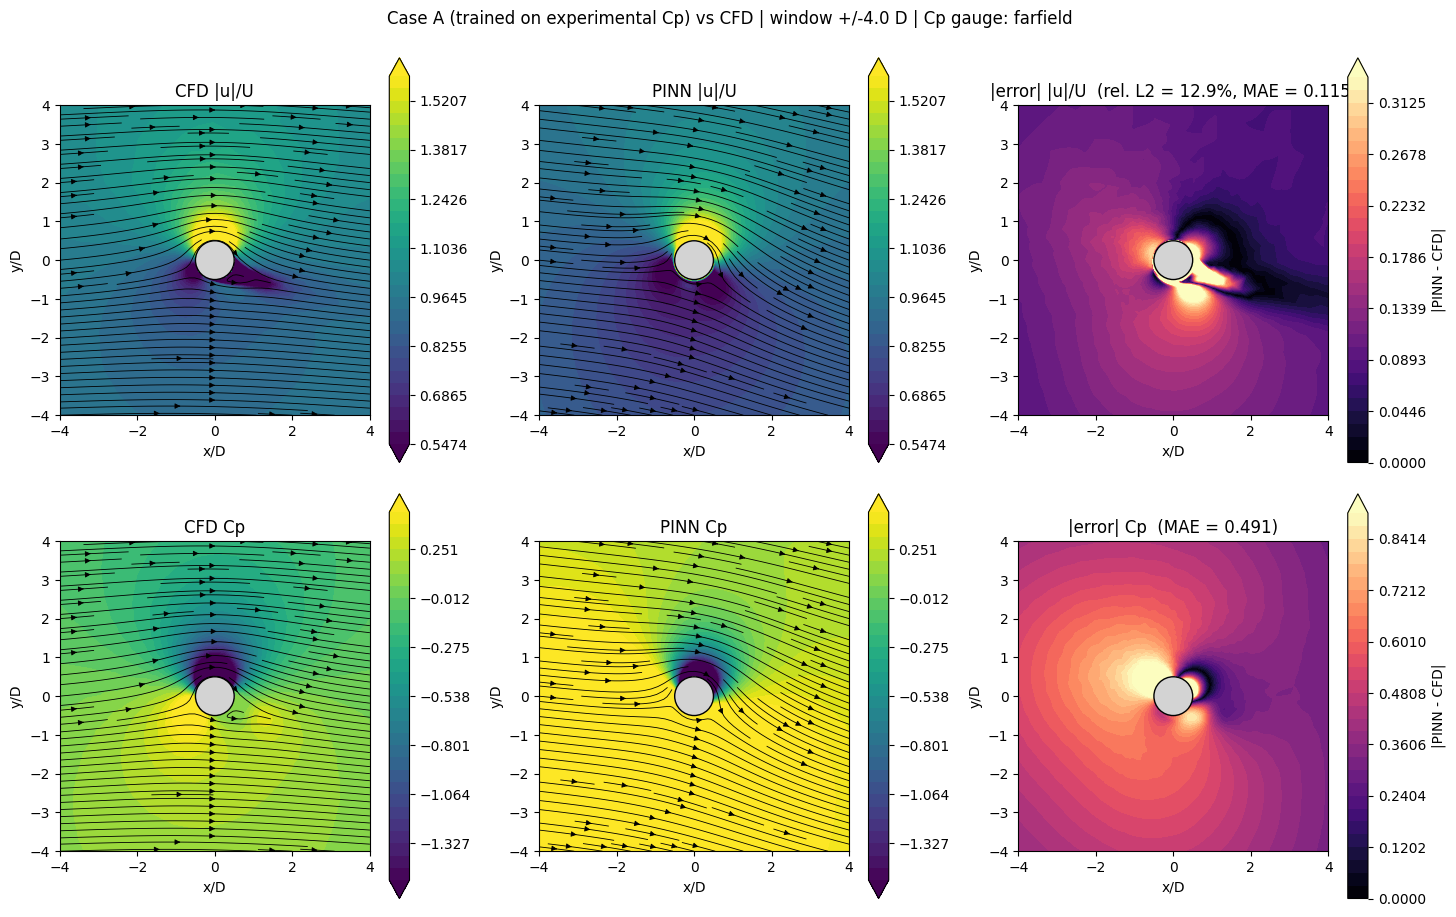

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_profiles.png


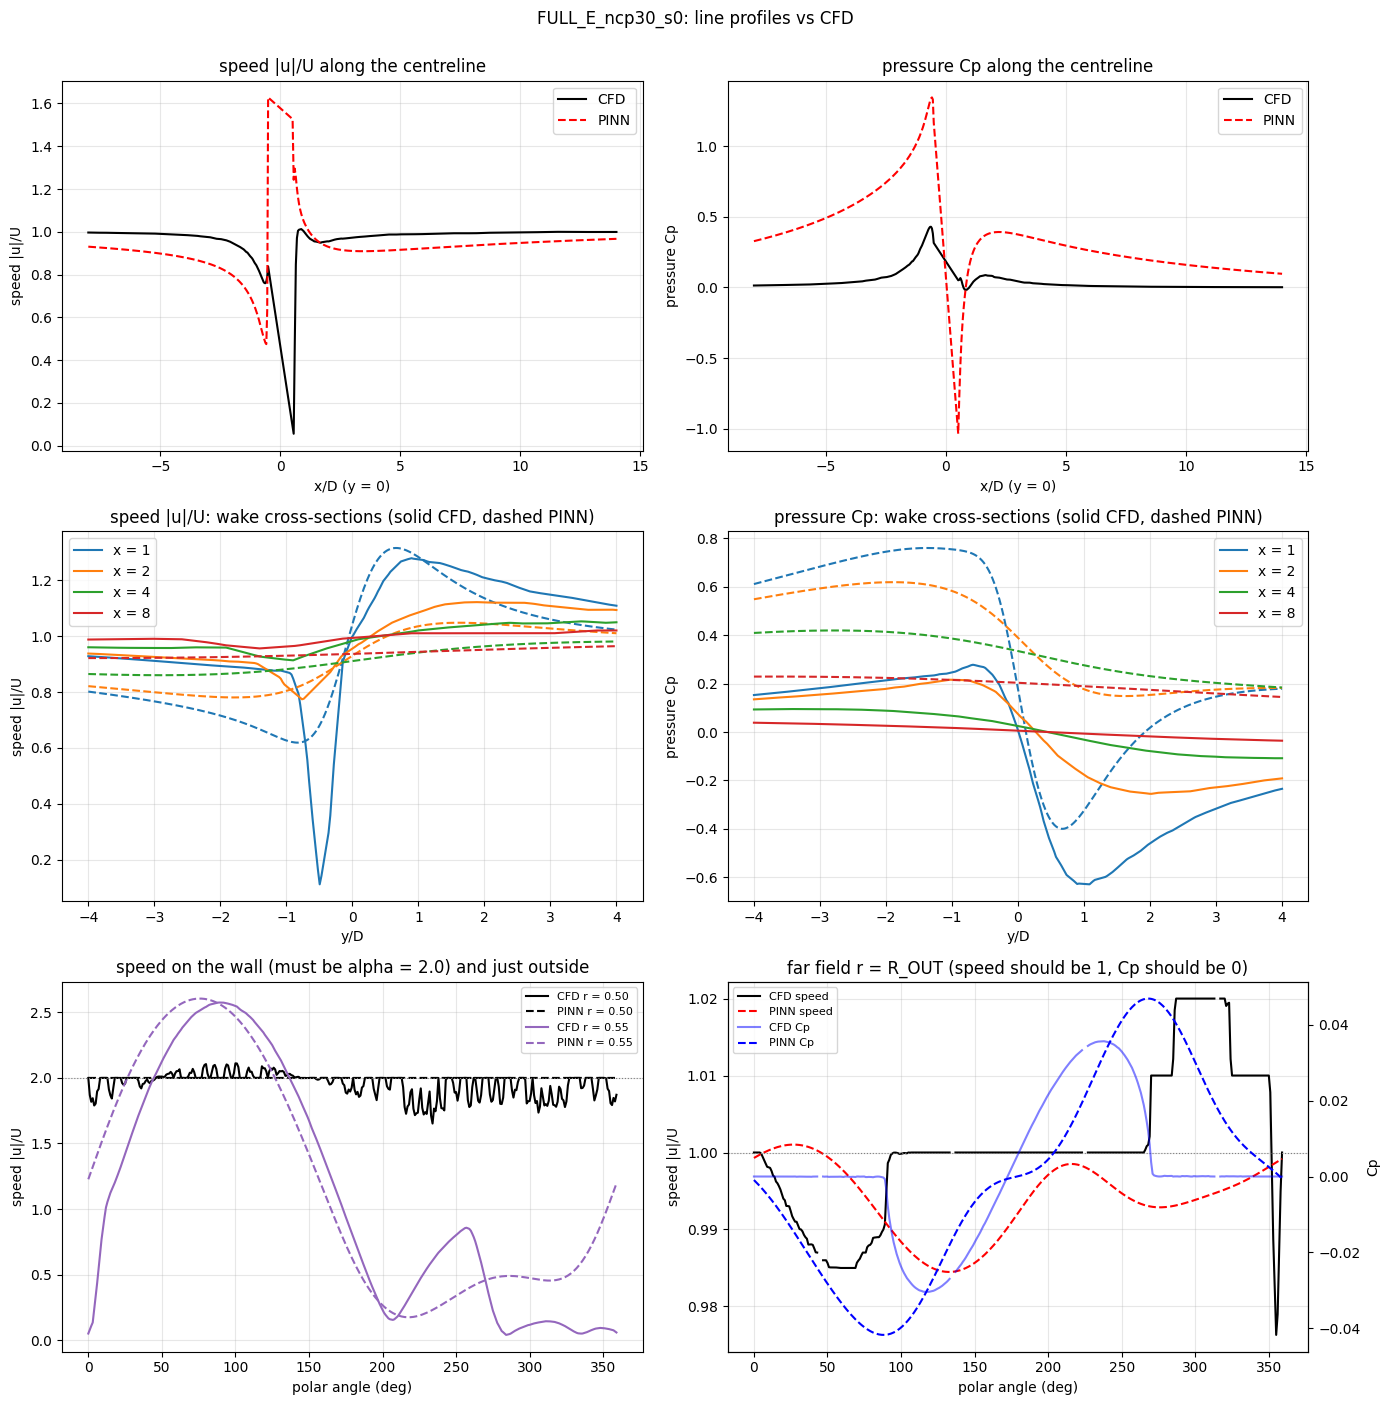

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_wake_decay.png


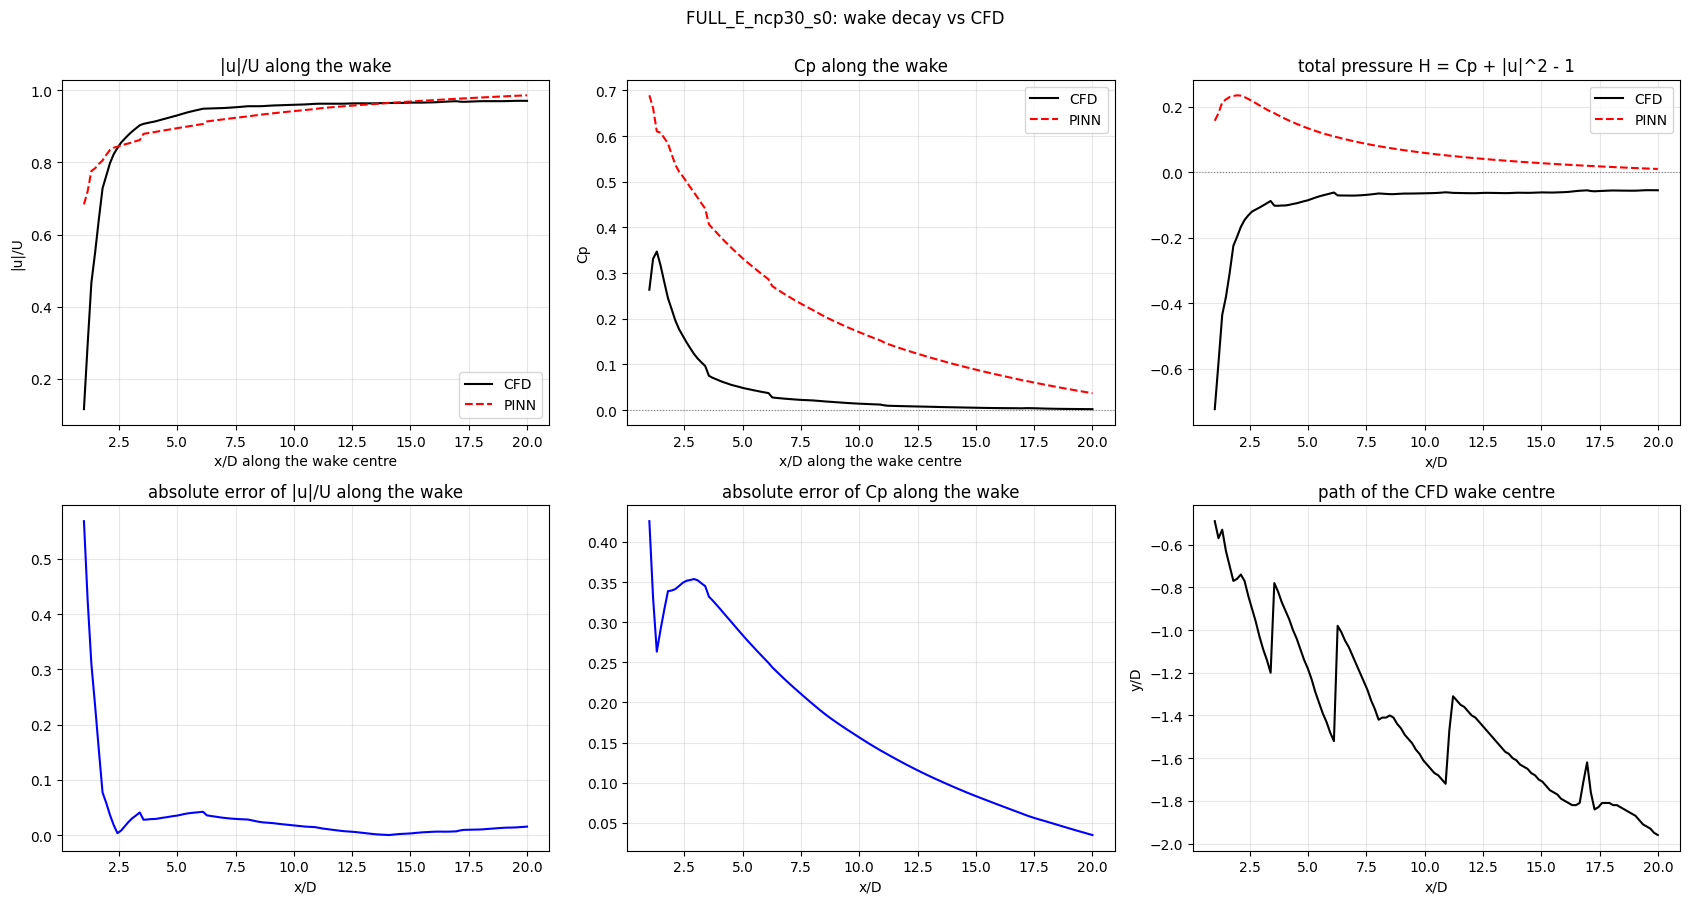

,x range (D),mean |err| |u|/U,mean |err| Cp,PINN Cp mean,CFD Cp mean
0,1-3,0.149,0.338,0.565,0.227
1,3-6,0.034,0.301,0.363,0.062
2,6-10,0.027,0.200,0.221,0.021
3,10-20,0.008,0.087,0.093,0.006


PINN wall speed:  mean = 2.000, min = 2.000, max = 2.000   (target 2.00)
PINN far-field:   mean speed = 0.994 (std 0.005),  Cp mean = 0.0000 (std 0.0265)   (targets 1 and 0)
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_region_errors.csv


,region,n_nodes,speed_MAE,speed_relL2,speed_bias,pressure_MAE,pressure_relL2,pressure_bias,u_MAE,u_relL2,u_bias,v_MAE,v_relL2,v_bias
0,whole domain,14319,0.170,0.270,0.034,0.414,0.413,0.254,0.125,0.235,-0.105,0.163,0.645,-0.103
1,near wall r<1,6347,0.336,0.347,0.121,0.773,0.402,0.414,0.230,0.319,-0.187,0.300,0.635,-0.169
2,near wall r<2,6652,0.328,0.343,0.110,0.764,0.405,0.421,0.227,0.315,-0.185,0.297,0.637,-0.171
3,"upstream x<-1, r<6",240,0.125,0.132,-0.125,0.561,3.074,0.561,0.119,0.124,-0.119,0.173,1.136,-0.173
4,"wake x 1-8, |y|<1.5",164,0.073,0.114,-0.011,0.297,1.591,0.297,0.122,0.142,-0.103,0.236,1.130,-0.236
5,"wide wake x 1-15, |y|<3",463,0.060,0.084,-0.038,0.235,1.877,0.235,0.088,0.107,-0.081,0.144,1.199,-0.144
6,far field r>10,6423,0.024,0.028,-0.023,0.070,3.236,0.067,0.025,0.030,-0.024,0.031,1.370,-0.026


median |momentum residual|: wake region = 2.83e-02, rest of window (r>3) = 2.79e-02
median |continuity residual|: wake region = 2.39e-02, rest of window (r>3) = 2.33e-02
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_E_ncp30_s0_residuals_ext4.png


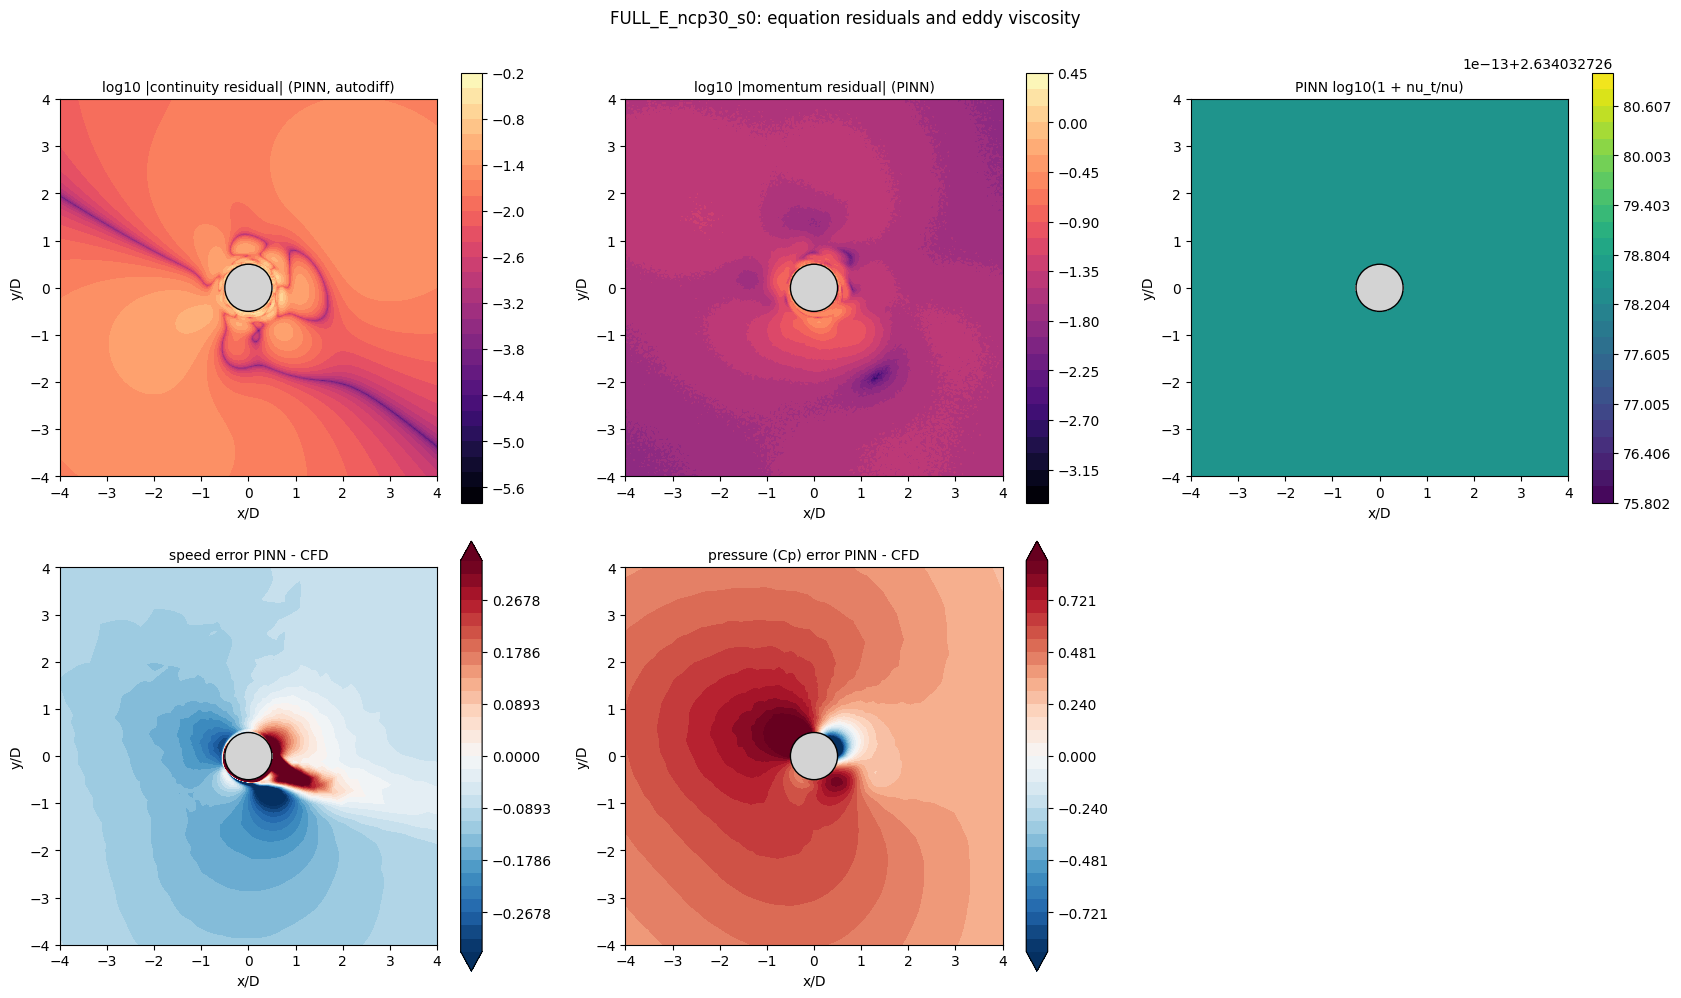

Wind tunnel (Bordogna):  CL = 5.917   CD = 1.745
PINN wall integral:      CL = 5.208   CD = 1.939
saved: diag_FULL_E_ncp30_s0_force_audit.(png/csv)


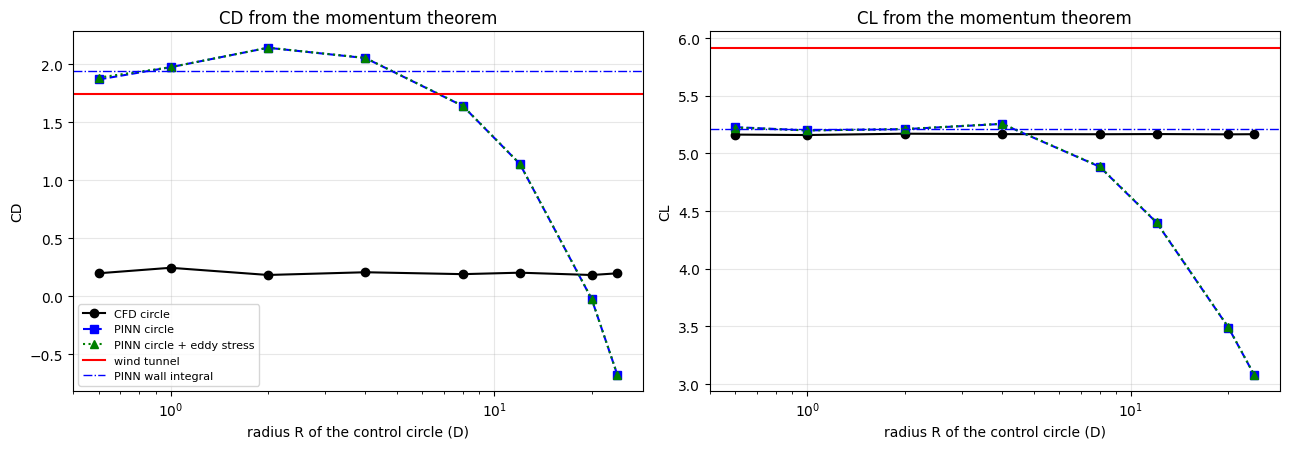

molecular Re = 3.6e+05; eddy-viscosity cap = 0.1 (ratio 36000)


,region,n,nut/nu median,nut/nu p90,nut/nu p99,cap share,Re_eff median
0,all nodes,14319,429.55899,429.55899,429.55899,0.0,836.122
1,wall layer r<0.6,3068,429.55899,429.55899,429.55899,0.0,836.122
2,near r<2,6652,429.55899,429.55899,429.55899,0.0,836.122
3,"wake x 1-8, |y|<1.5",164,429.55899,429.55899,429.55899,0.0,836.122
4,"lower half y<-1, r<10",608,429.55899,429.55899,429.55899,0.0,836.122
5,far r>10,6423,429.55899,429.55899,429.55899,0.0,836.122


fraction of window (r>3) with H > +0.1:  CFD = 0.000   PINN = 1.000
saved total pressure figure


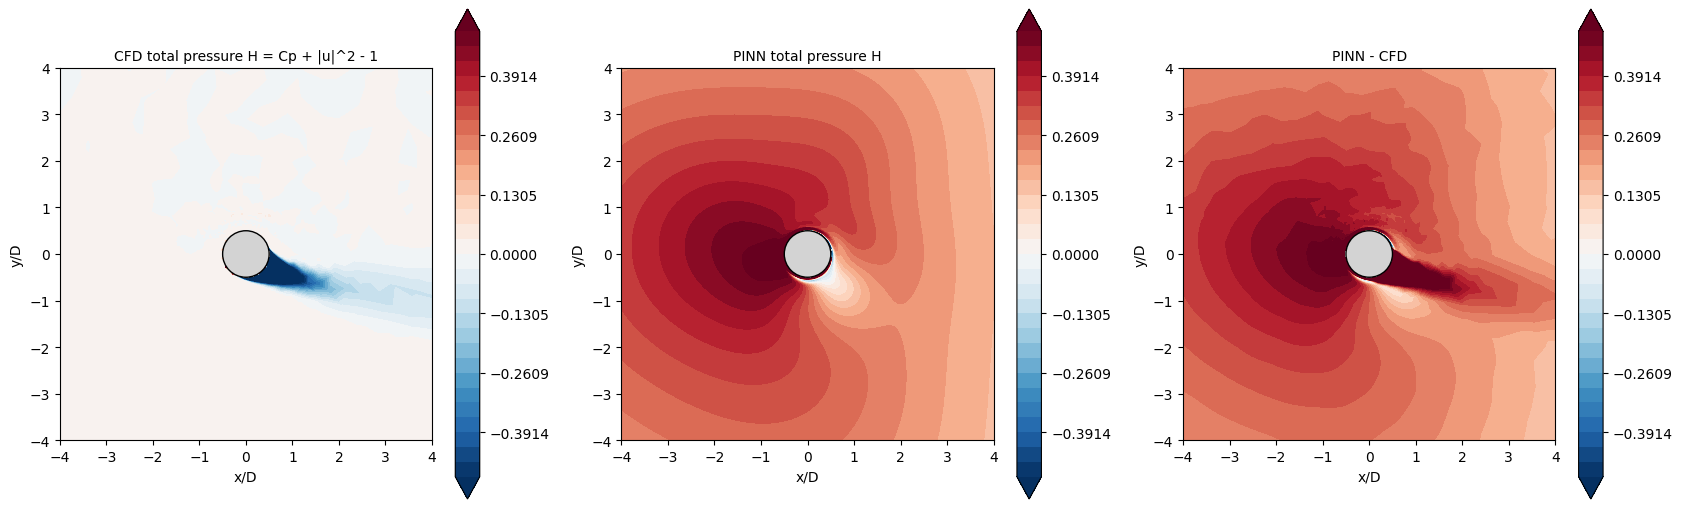


==================== B: CFD Cp (method check) ====================
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD_ncp30_s0_fields_uvp_ext4.png


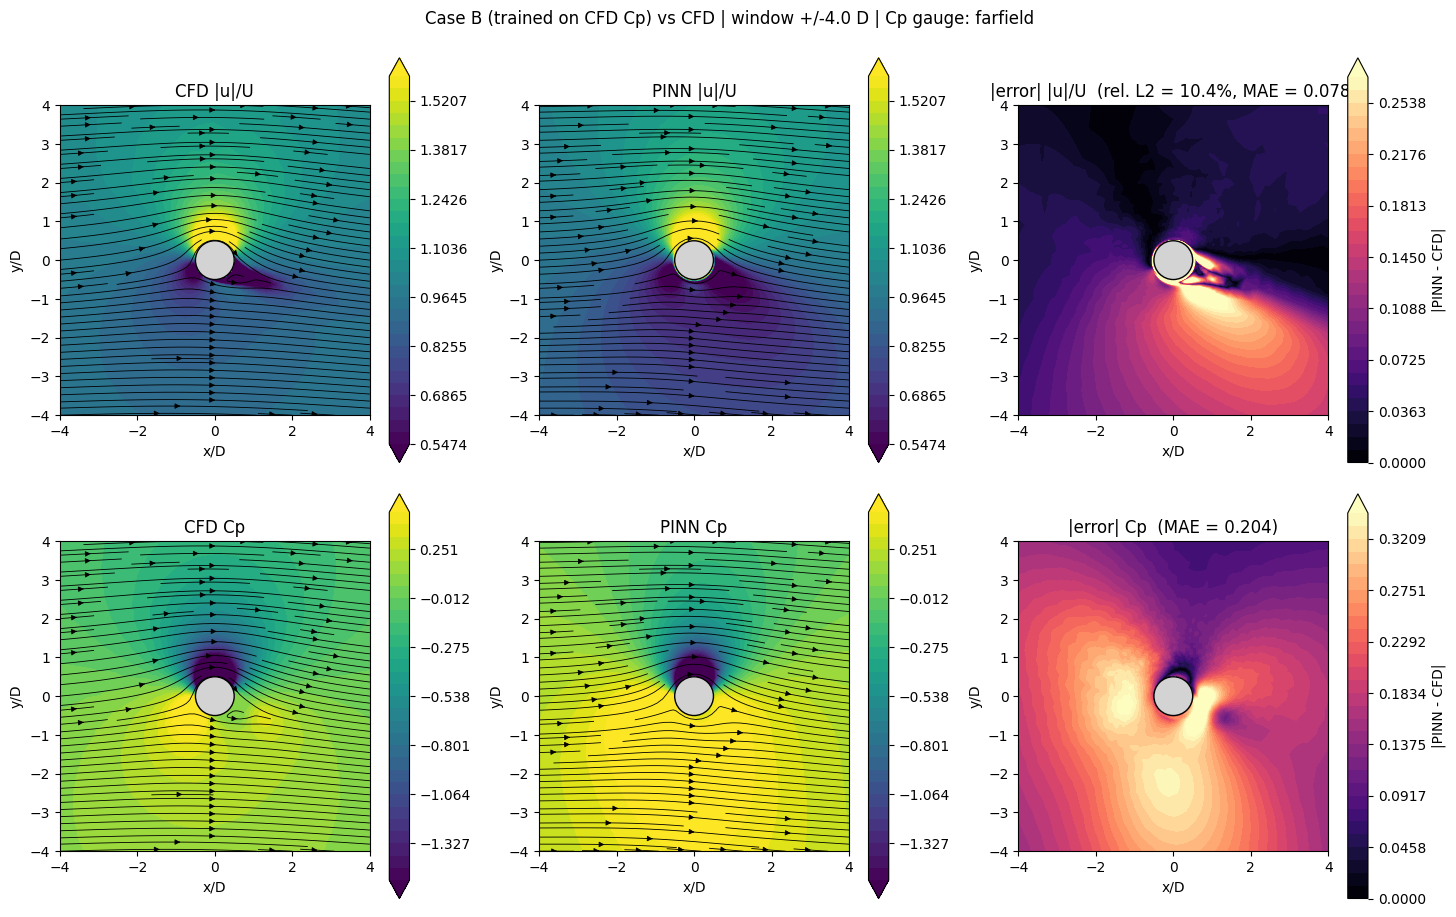

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD_ncp30_s0_profiles.png


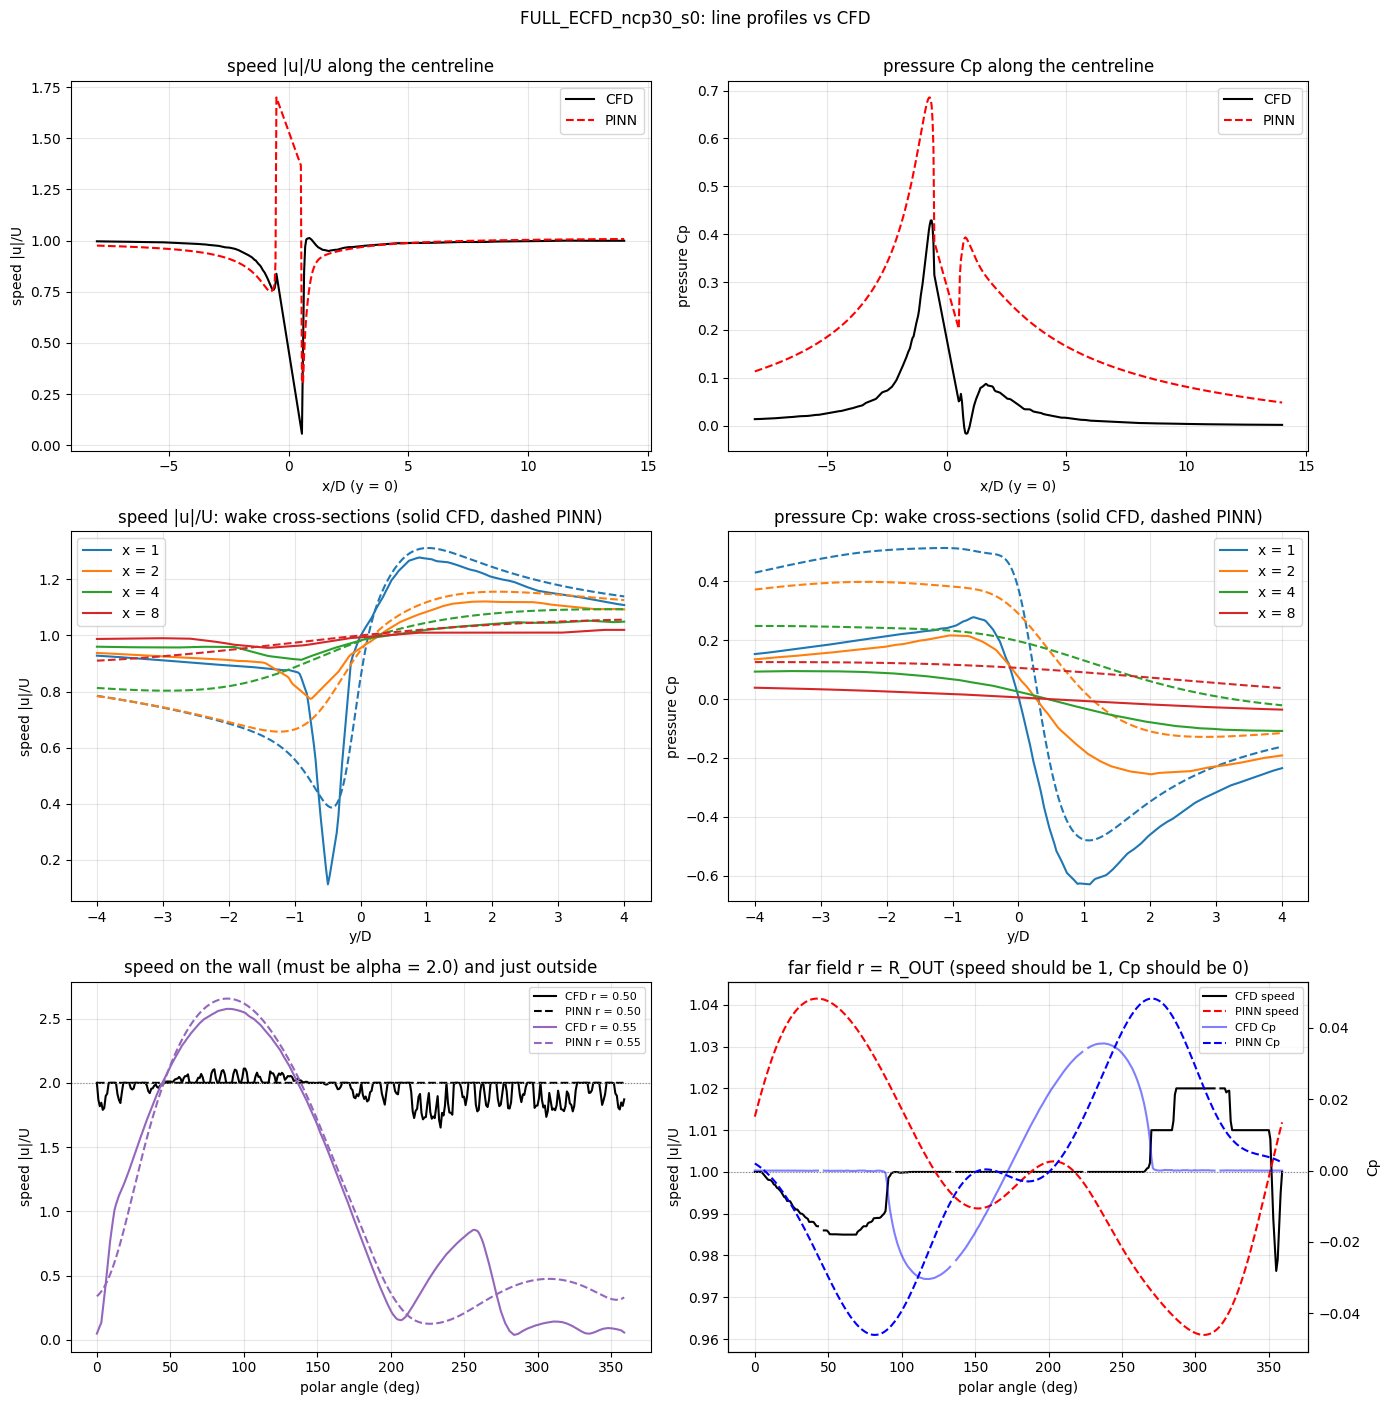

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD_ncp30_s0_wake_decay.png


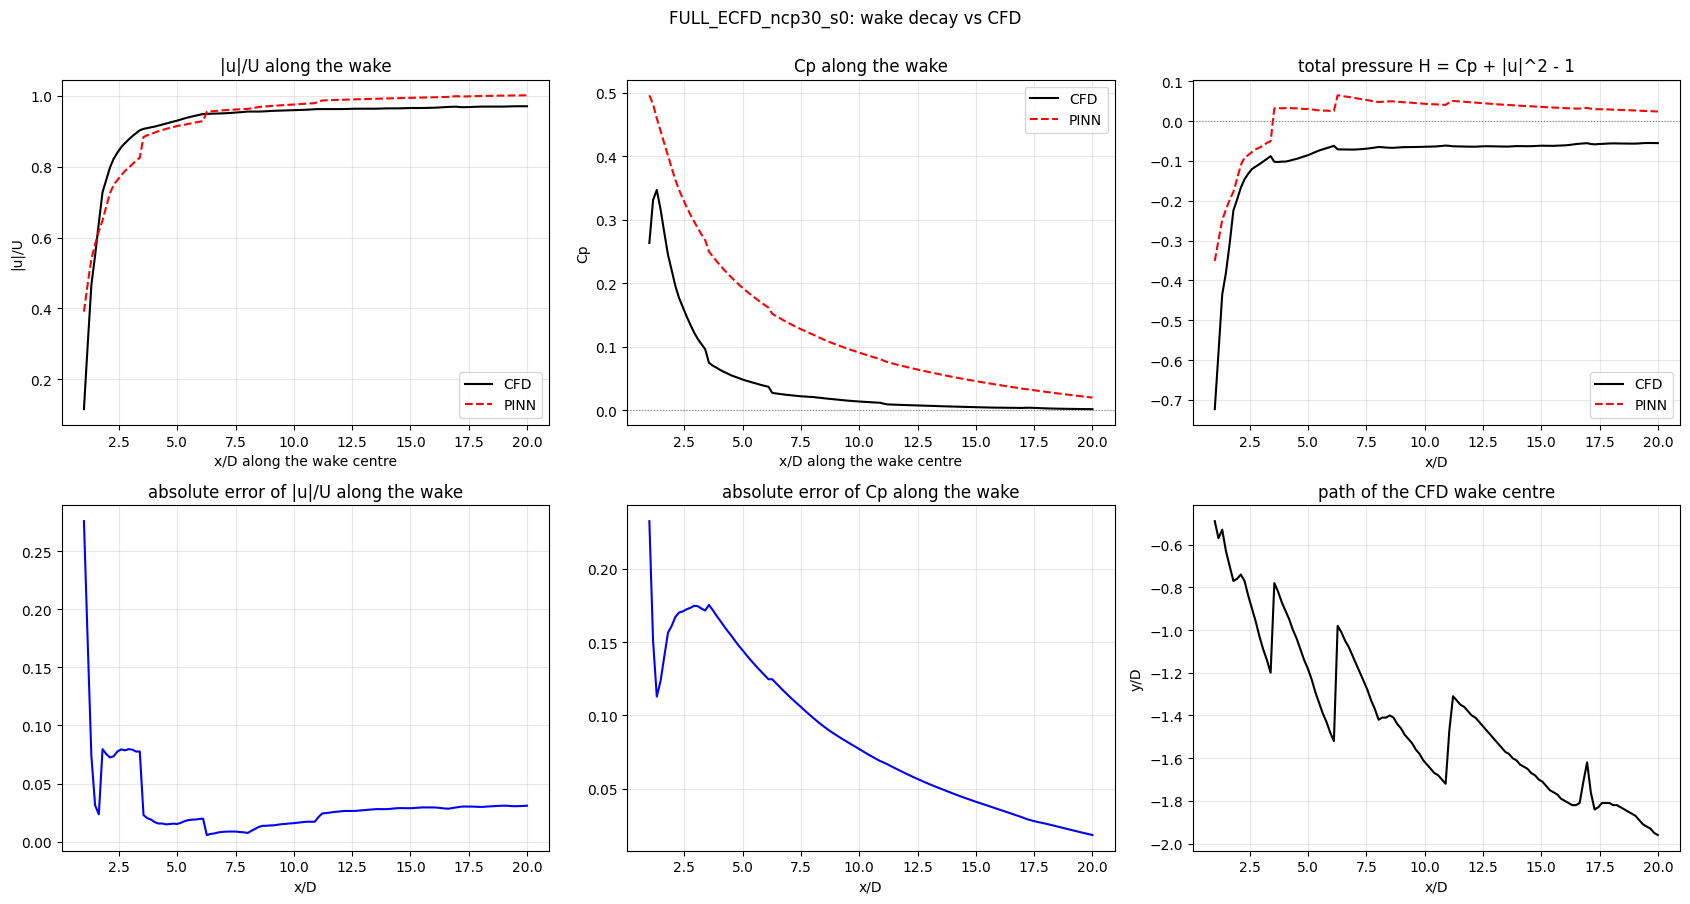

,x range (D),mean |err| |u|/U,mean |err| Cp,PINN Cp mean,CFD Cp mean
0,1-3,0.092,0.162,0.389,0.227
1,3-6,0.027,0.154,0.215,0.062
2,6-10,0.011,0.100,0.121,0.021
3,10-20,0.027,0.043,0.049,0.006


PINN wall speed:  mean = 2.000, min = 2.000, max = 2.000   (target 2.00)
PINN far-field:   mean speed = 1.000 (std 0.024),  Cp mean = -0.0000 (std 0.0261)   (targets 1 and 0)
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD_ncp30_s0_region_errors.csv


,region,n_nodes,speed_MAE,speed_relL2,speed_bias,pressure_MAE,pressure_relL2,pressure_bias,u_MAE,u_relL2,u_bias,v_MAE,v_relL2,v_bias
0,whole domain,14319,0.121,0.226,0.029,0.114,0.108,0.103,0.111,0.223,-0.072,0.082,0.456,0.022
1,near wall r<1,6347,0.227,0.290,0.083,0.188,0.099,0.170,0.205,0.304,-0.146,0.162,0.457,0.043
2,near wall r<2,6652,0.221,0.286,0.076,0.190,0.103,0.174,0.200,0.300,-0.142,0.156,0.456,0.041
3,"upstream x<-1, r<6",240,0.054,0.064,-0.053,0.223,1.243,0.223,0.052,0.063,-0.051,0.031,0.218,-0.031
4,"wake x 1-8, |y|<1.5",164,0.051,0.089,-0.015,0.179,0.969,0.179,0.051,0.090,-0.009,0.024,0.158,0.020
5,"wide wake x 1-15, |y|<3",463,0.046,0.076,-0.012,0.124,1.010,0.124,0.046,0.077,-0.010,0.024,0.202,0.022
6,far field r>10,6423,0.030,0.037,-0.006,0.031,1.445,0.024,0.030,0.037,-0.006,0.018,0.807,0.010


median |momentum residual|: wake region = 2.84e-02, rest of window (r>3) = 1.36e-02
median |continuity residual|: wake region = 1.82e-02, rest of window (r>3) = 1.52e-02
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD_ncp30_s0_residuals_ext4.png


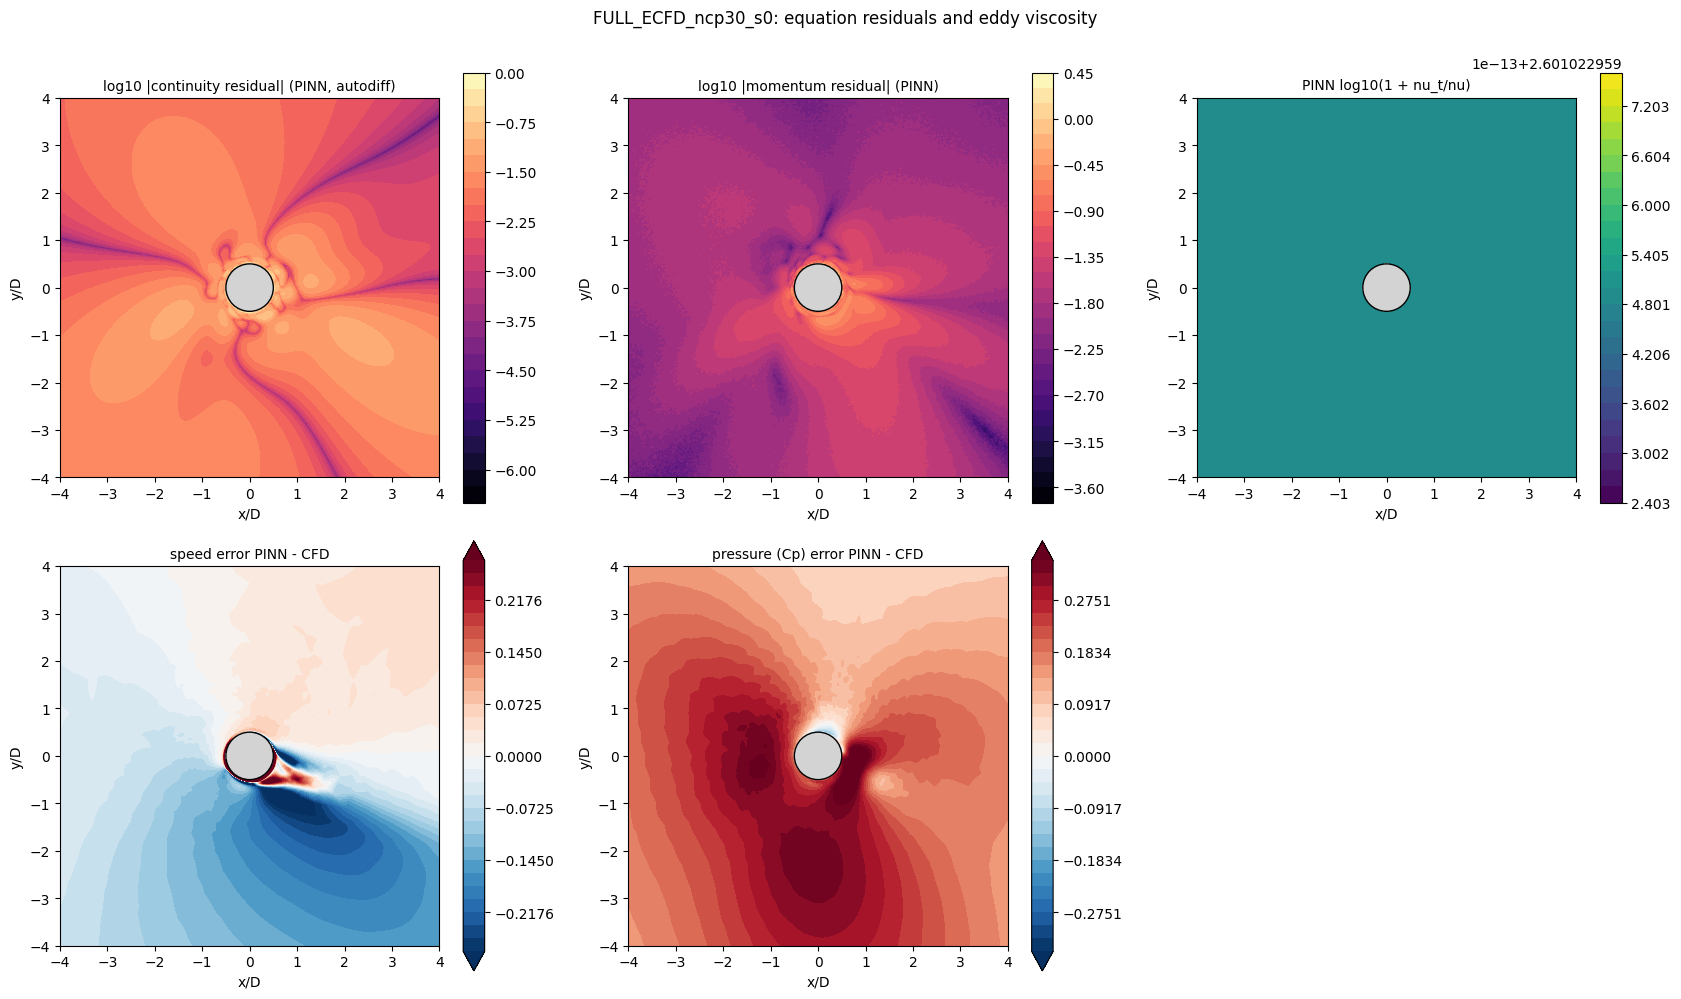

Wind tunnel (Bordogna):  CL = 5.917   CD = 1.745
PINN wall integral:      CL = 5.244   CD = 0.314
saved: diag_FULL_ECFD_ncp30_s0_force_audit.(png/csv)


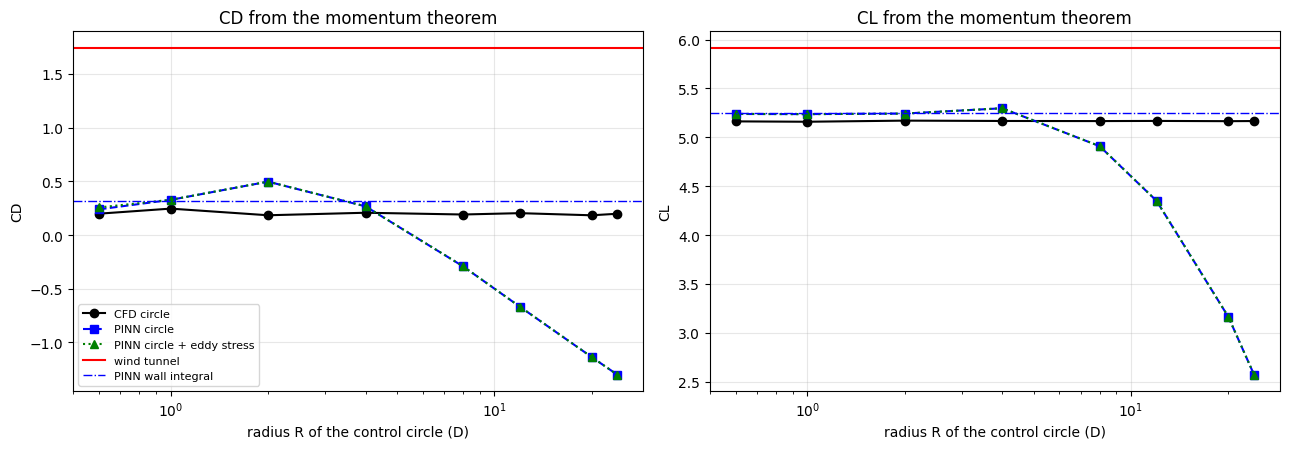

molecular Re = 3.6e+05; eddy-viscosity cap = 0.1 (ratio 36000)


,region,n,nut/nu median,nut/nu p90,nut/nu p99,cap share,Re_eff median
0,all nodes,14319,398.04599,398.04599,398.04599,0.0,902.152
1,wall layer r<0.6,3068,398.04599,398.04599,398.04599,0.0,902.152
2,near r<2,6652,398.04599,398.04599,398.04599,0.0,902.152
3,"wake x 1-8, |y|<1.5",164,398.04599,398.04599,398.04599,0.0,902.152
4,"lower half y<-1, r<10",608,398.04599,398.04599,398.04599,0.0,902.152
5,far r>10,6423,398.04599,398.04599,398.04599,0.0,902.152


fraction of window (r>3) with H > +0.1:  CFD = 0.000   PINN = 0.577
saved total pressure figure


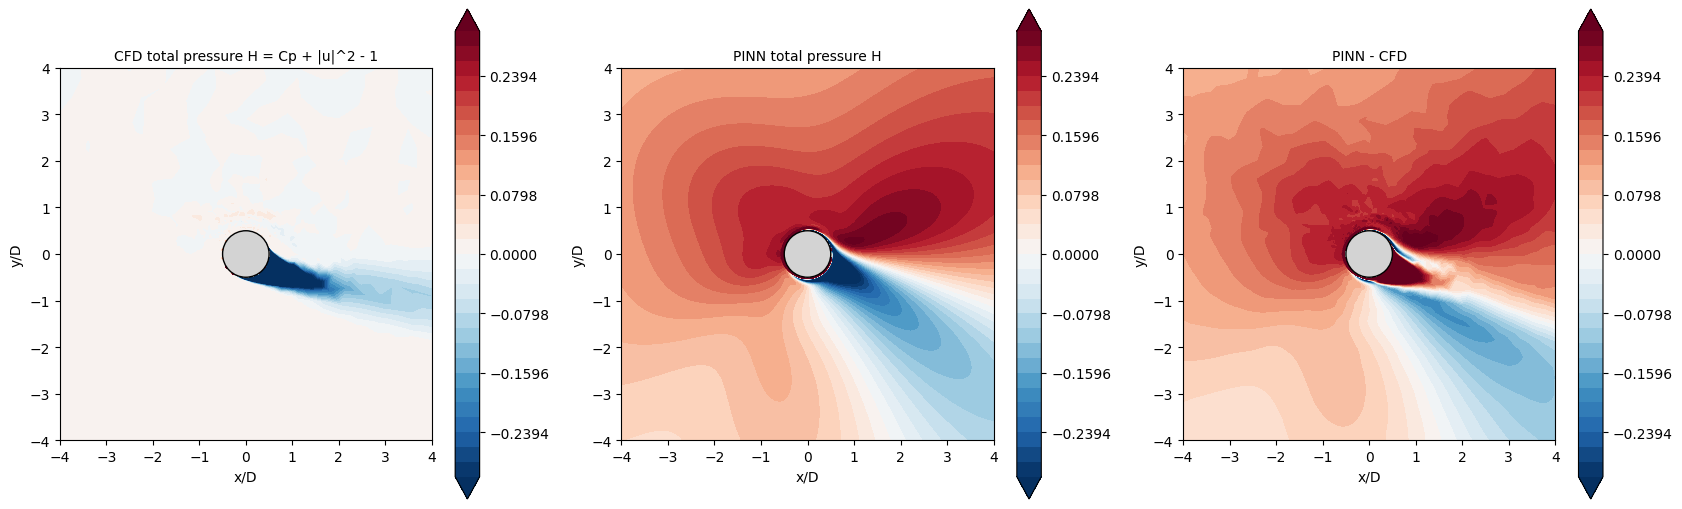


==================== B2: CFD Cp, option 2 ====================
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD2_ncp60_s0_fields_uvp_ext4.png


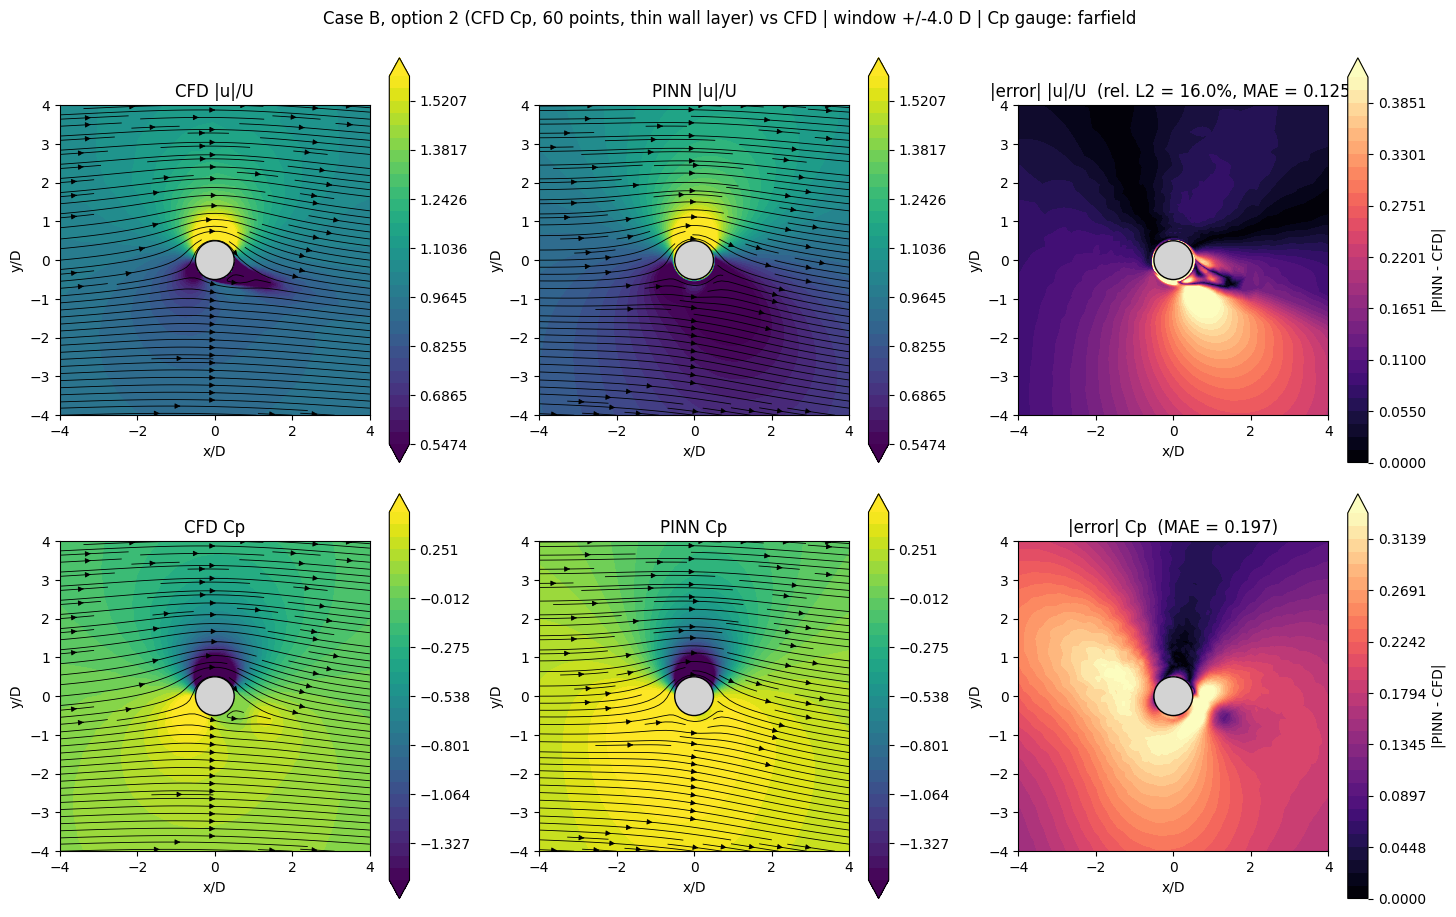

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD2_ncp60_s0_profiles.png


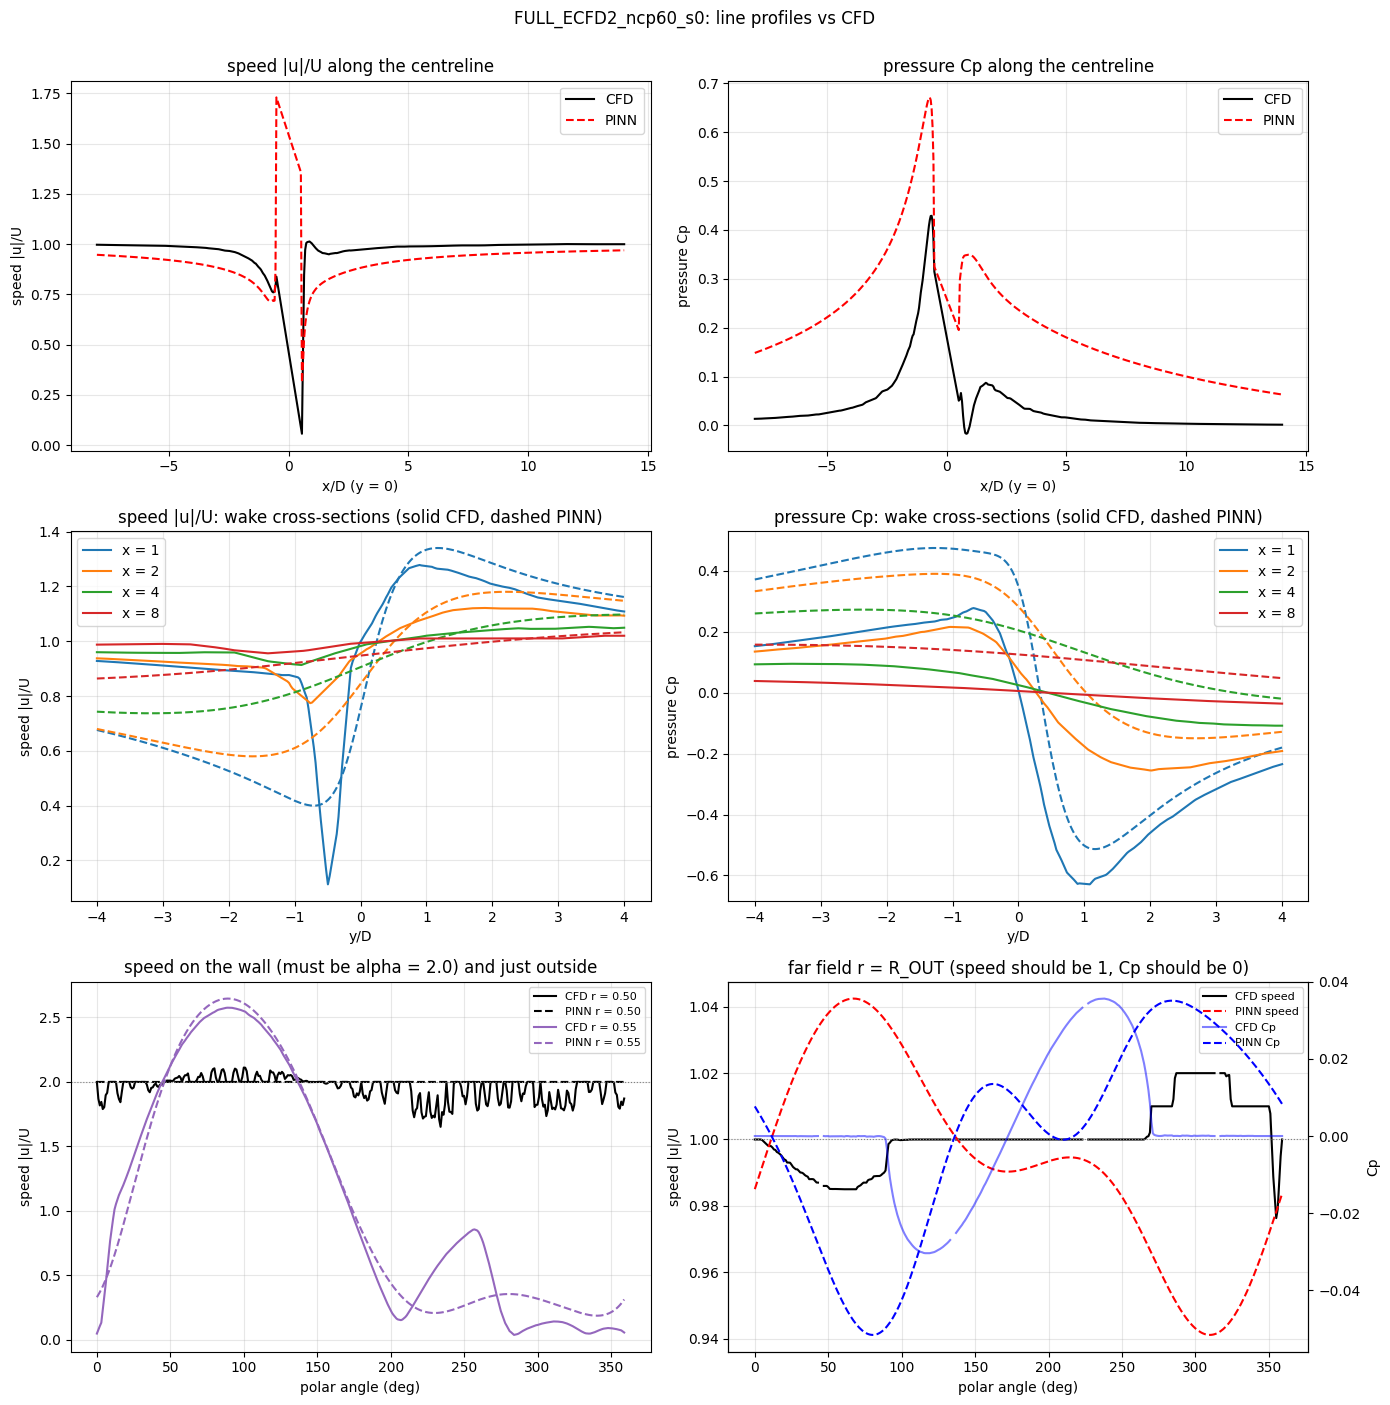

saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD2_ncp60_s0_wake_decay.png


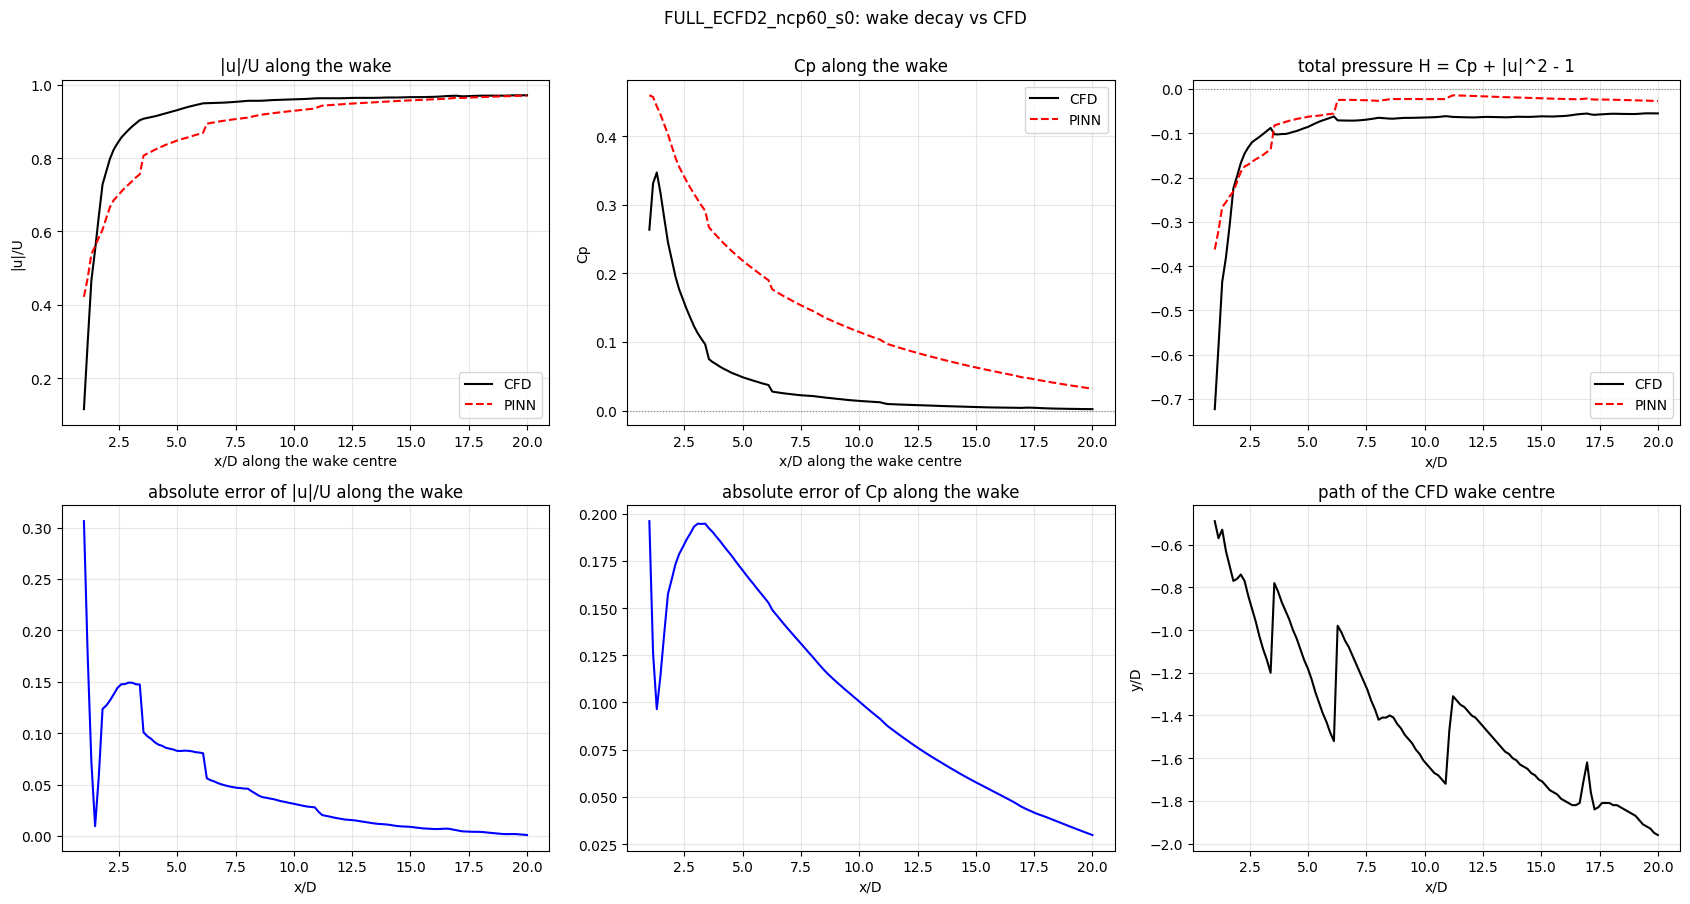

,x range (D),mean |err| |u|/U,mean |err| Cp,PINN Cp mean,CFD Cp mean
0,1-3,0.133,0.161,0.388,0.227
1,3-6,0.097,0.177,0.239,0.062
2,6-10,0.044,0.125,0.146,0.021
3,10-20,0.011,0.060,0.066,0.006


PINN wall speed:  mean = 2.000, min = 2.000, max = 2.000   (target 2.00)
PINN far-field:   mean speed = 0.994 (std 0.030),  Cp mean = -0.0000 (std 0.0259)   (targets 1 and 0)
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD2_ncp60_s0_region_errors.csv


,region,n_nodes,speed_MAE,speed_relL2,speed_bias,pressure_MAE,pressure_relL2,pressure_bias,u_MAE,u_relL2,u_bias,v_MAE,v_relL2,v_bias
0,whole domain,14319,0.133,0.229,0.012,0.113,0.106,0.101,0.126,0.230,-0.084,0.083,0.459,0.022
1,near wall r<1,6347,0.236,0.291,0.064,0.181,0.096,0.161,0.221,0.310,-0.154,0.163,0.459,0.054
2,near wall r<2,6652,0.233,0.288,0.056,0.183,0.099,0.164,0.218,0.307,-0.151,0.157,0.458,0.051
3,"upstream x<-1, r<6",240,0.086,0.099,-0.086,0.235,1.292,0.235,0.082,0.097,-0.082,0.062,0.424,-0.062
4,"wake x 1-8, |y|<1.5",164,0.090,0.130,-0.069,0.179,0.965,0.179,0.087,0.132,-0.064,0.035,0.234,0.011
5,"wide wake x 1-15, |y|<3",463,0.073,0.116,-0.059,0.131,1.035,0.131,0.073,0.118,-0.058,0.022,0.236,0.006
6,far field r>10,6423,0.039,0.049,-0.018,0.037,1.649,0.029,0.039,0.049,-0.018,0.016,0.675,0.001


median |momentum residual|: wake region = 3.50e-02, rest of window (r>3) = 1.48e-02
median |continuity residual|: wake region = 6.00e-02, rest of window (r>3) = 2.83e-02
saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/diag_FULL_ECFD2_ncp60_s0_residuals_ext4.png


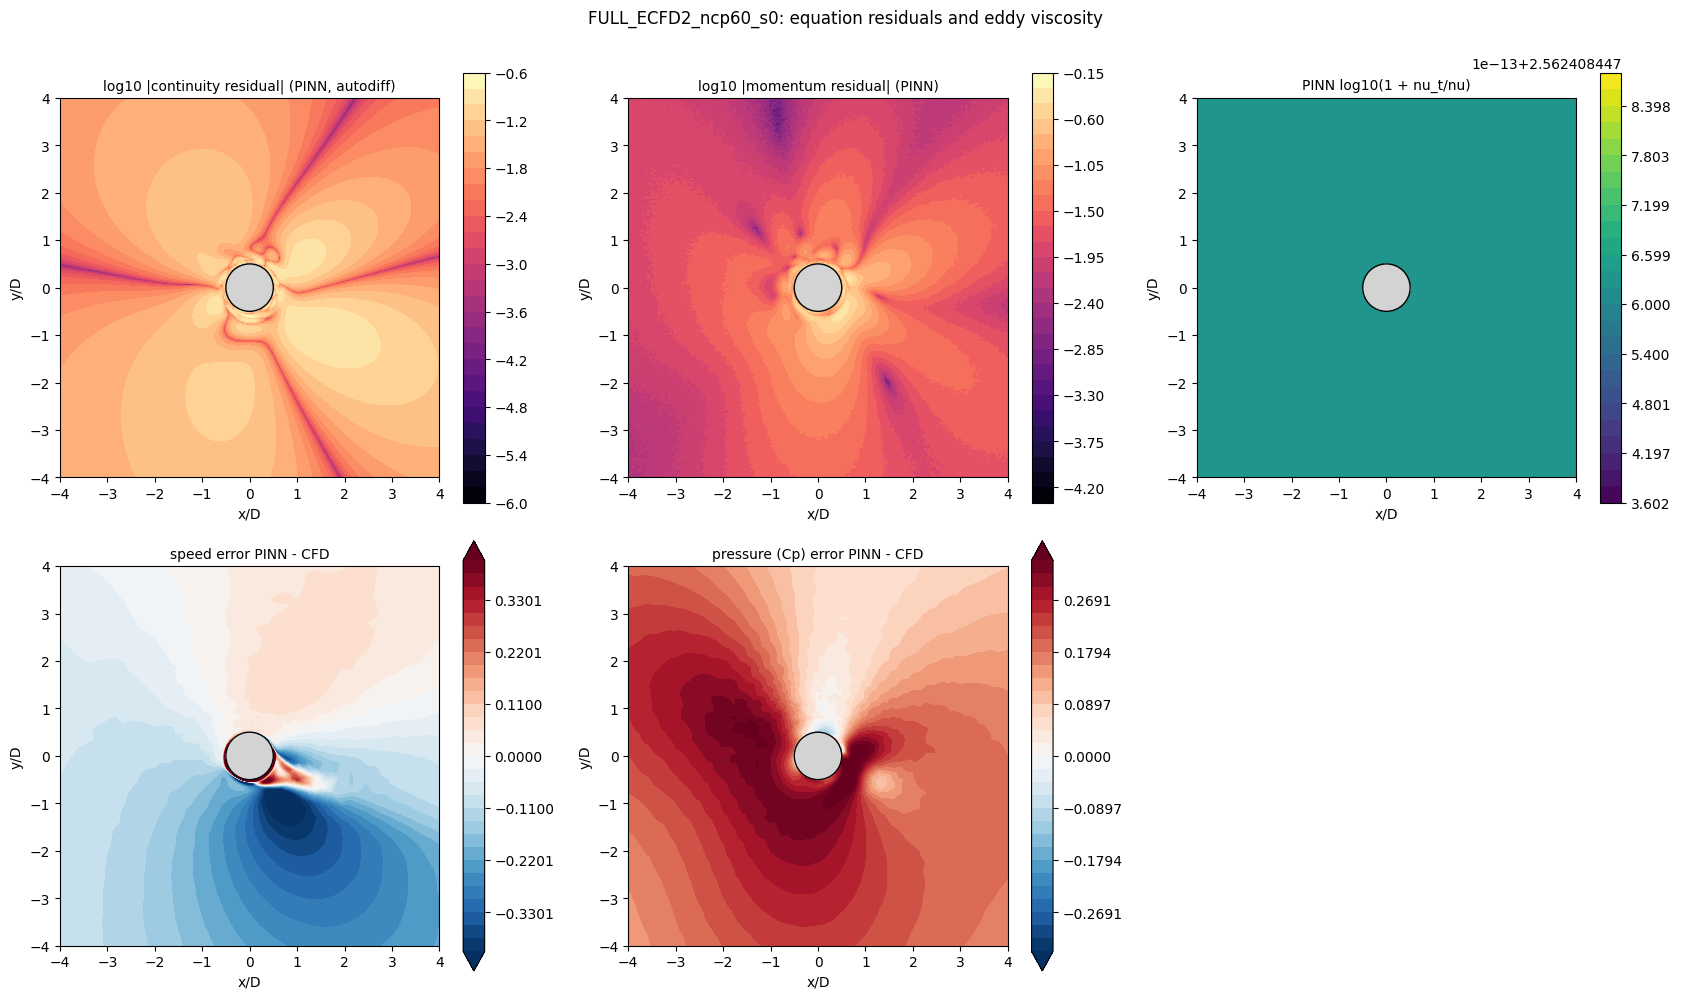

Wind tunnel (Bordogna):  CL = 5.917   CD = 1.745
PINN wall integral:      CL = 5.246   CD = 0.278
saved: diag_FULL_ECFD2_ncp60_s0_force_audit.(png/csv)


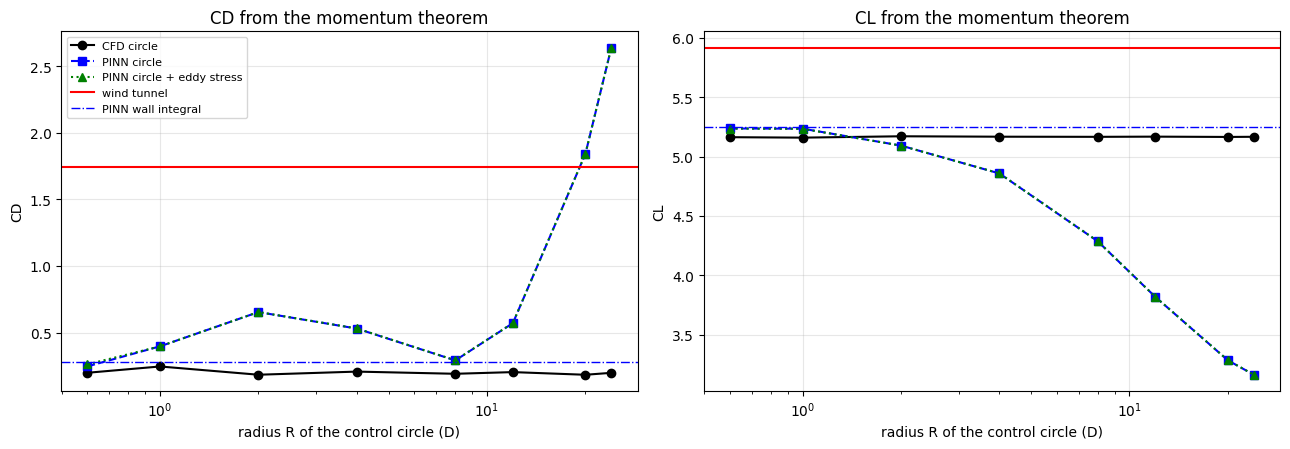

molecular Re = 3.6e+05; eddy-viscosity cap = 0.1 (ratio 36000)


,region,n,nut/nu median,nut/nu p90,nut/nu p99,cap share,Re_eff median
0,all nodes,14319,364.096985,364.096985,364.096985,0.0,986.039
1,wall layer r<0.6,3068,364.096985,364.096985,364.096985,0.0,986.039
2,near r<2,6652,364.096985,364.096985,364.096985,0.0,986.039
3,"wake x 1-8, |y|<1.5",164,364.096985,364.096985,364.096985,0.0,986.039
4,"lower half y<-1, r<10",608,364.096985,364.096985,364.096985,0.0,986.039
5,far r>10,6423,364.096985,364.096985,364.096985,0.0,986.039


fraction of window (r>3) with H > +0.1:  CFD = 0.000   PINN = 0.475
saved total pressure figure


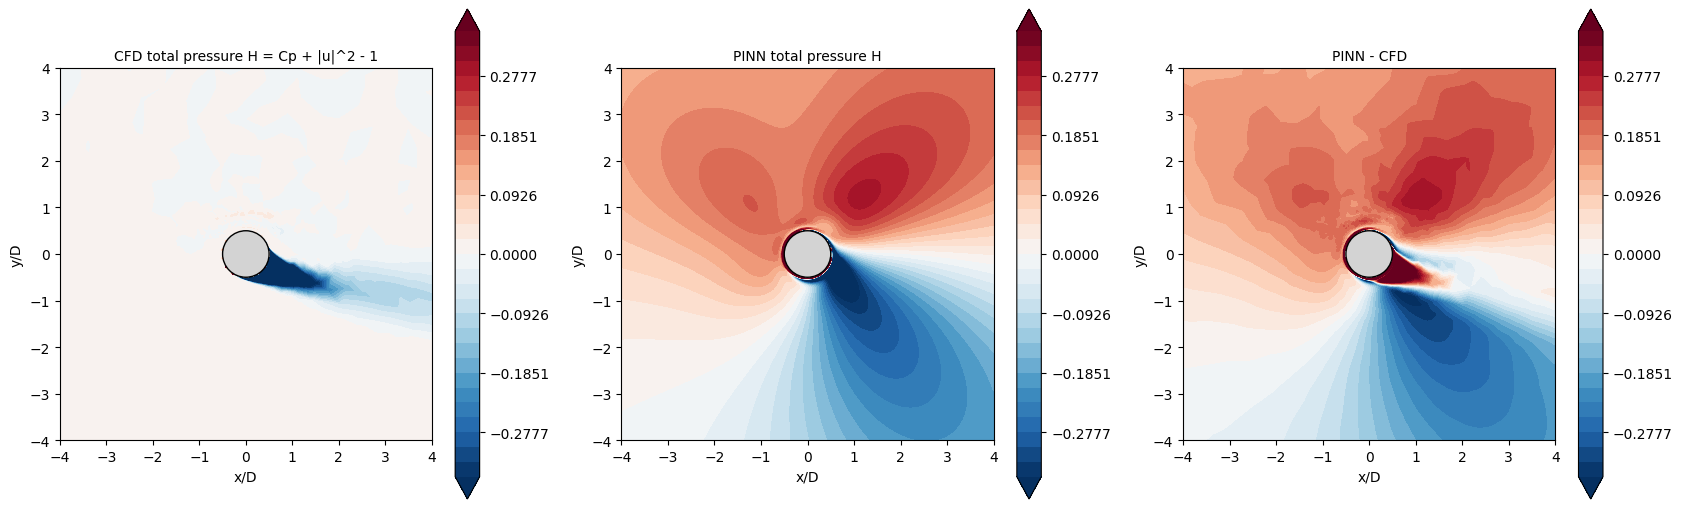

In [18]:
for key in [k for k in CASES if k in RUNS]:
    print(f"\n==================== {RUNS[key]['label']} ====================")
    diagnose(key)

### 5.12  Data floor: how far apart are the experiment and the CFD at the wall?

Case A is trained on the experimental wall Cp. Its pressure field cannot agree with the CFD better than the two data sets agree with each other at the wall.
This cell compares the experimental and the CFD wall Cp at the same angles. No training.


experiment vs CFD wall Cp, 30 angles
  MAE (as measured)            = 1.152
  MAE (one constant removed)   = 1.122   (constant = +0.110)
  largest difference           = 2.384 at theta = 163.3
  CL exp / CFD = 5.917 / 5.145 | CD exp / CFD = 1.745 / 0.182


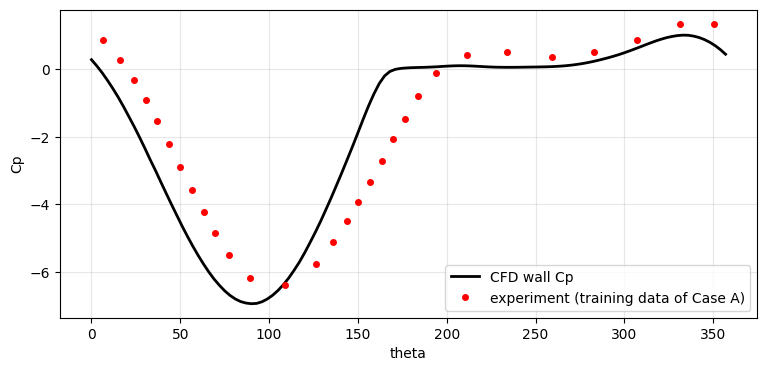

In [19]:
th_e, cp_e = np.asarray(data_main["theta_exp"]).ravel(), np.asarray(data_main["cp_exp"]).ravel()
th_c, cp_c = np.asarray(data_cfd["theta_exp"]).ravel(), np.asarray(data_cfd["cp_exp"]).ravel()
o = np.argsort(th_c)
cp_c_at_e = np.interp(th_e, th_c[o], cp_c[o], period=360.0 if th_c.max() > 7 else 2 * np.pi)
d = cp_e - cp_c_at_e
print(f"experiment vs CFD wall Cp, {len(th_e)} angles")
print(f"  MAE (as measured)            = {np.mean(np.abs(d)):.3f}")
print(f"  MAE (one constant removed)   = {np.mean(np.abs(d - d.mean())):.3f}   (constant = {d.mean():+.3f})")
print(f"  largest difference           = {np.max(np.abs(d)):.3f} at theta = {th_e[np.argmax(np.abs(d))]:.1f}")
print(f"  CL exp / CFD = {data_main['cl_ref']:.3f} / {data_cfd['cl_ref']:.3f} | CD exp / CFD = {data_main['cd_ref']:.3f} / {data_cfd['cd_ref']:.3f}")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(th_c[o], cp_c[o], "k-", lw=2, label="CFD wall Cp")
ax.plot(th_e, cp_e, "ro", ms=4, label="experiment (training data of Case A)")
ax.set_xlabel("theta"); ax.set_ylabel("Cp"); ax.grid(alpha=.3); ax.legend()
fig.savefig(f"{OUT_DIR}/data_floor_exp_vs_cfd_wall_cp.png", dpi=200, bbox_inches="tight"); plt.show()


### 5.13  Force decomposition: fitted wall pressure versus viscous stress

Splits the PINN C_L and C_D into the part from the wall pressure and the part from the viscous stress of the reconstructed field,
and compares them with the integral of the 30 training Cp values alone (no PINN). This shows how much of each coefficient the
PINN adds to what the data already contain. No training.


In [20]:
# Force decomposition: where do C_L and C_D come from?  (no training; uses the loaded runs)
# (1) direct integral of the training Cp data alone (no PINN)
# (2) PINN pressure part   (integral of the reconstructed wall pressure)
# (3) PINN viscous part    (integral of the viscous stress nu_eff (grad u + grad u^T) of the reconstructed field)
# (4) PINN total = (2) + (3)  -> the C_L, C_D reported in the manuscript
# Convention as in the data loaders: theta = 0 facing the wind, 90 deg = lift side; C_D = 1/2 \oint Cp cos(theta), C_L = -1/2 \oint Cp sin(theta)

def data_integral(theta_deg, cp, n=3600):
    th = np.asarray(theta_deg, float).ravel(); c = np.asarray(cp, float).ravel()
    o = np.argsort(th); th, c = th[o], c[o]
    g = np.arange(n) * 360.0 / n
    cg = np.interp(g, np.r_[th, th[0] + 360.0], np.r_[c, c[0]])      # linear between the points, periodic
    t = np.radians(g); dt = 2 * np.pi / n
    return float(-0.5 * np.sum(cg * np.sin(t)) * dt), float(0.5 * np.sum(cg * np.cos(t)) * dt)

def pinn_force_parts(model, cfg, n_f=512, h=1e-3):
    mk = make_input_fn(cfg); rw = float(core.r_wall(cfg)); dth = 2 * np.pi / n_f
    th = np.linspace(0, 2 * np.pi, n_f, endpoint=False, dtype=np.float32)
    xf = (-rw * np.cos(th)).reshape(-1, 1); yf = (rw * np.sin(th)).reshape(-1, 1)
    nx, ny = xf / rw, yf / rw
    def uvp(xp, yp):
        return get_uvp(model(mk(xp.astype(np.float32), yp.astype(np.float32)), training=False)).numpy()
    o = uvp(xf, yf); p0 = o[:, 2:3] - pinn_pref(model, cfg)
    ox_p, ox_m = uvp(xf + h, yf), uvp(xf - h, yf); oy_p, oy_m = uvp(xf, yf + h), uvp(xf, yf - h)
    du_dx = (ox_p[:, 0:1] - ox_m[:, 0:1]) / (2 * h); du_dy = (oy_p[:, 0:1] - oy_m[:, 0:1]) / (2 * h)
    dv_dx = (ox_p[:, 1:2] - ox_m[:, 1:2]) / (2 * h); dv_dy = (oy_p[:, 1:2] - oy_m[:, 1:2]) / (2 * h)
    nu = 1.0 / float(core.re_eff_of(model, cfg)) if getattr(cfg, "turb_model", "") == "constant_nu" else 1.0 / cfg.RE
    txx, txy, tyy = 2 * nu * du_dx, nu * (du_dy + dv_dx), 2 * nu * dv_dy
    fx_p = float(np.sum(-p0 * nx) * rw * dth); fy_p = float(np.sum(-p0 * ny) * rw * dth)
    fx_v = float(np.sum(txx * nx + txy * ny) * rw * dth); fy_v = float(np.sum(txy * nx + tyy * ny) * rw * dth)
    return dict(CL_pressure=fy_p / 0.5, CD_pressure=fx_p / 0.5, CL_viscous=fy_v / 0.5, CD_viscous=fx_v / 0.5)

rows = []
for key in [k for k in CASES if k in RUNS]:
    r = RUNS[key]; d = r["data"]; cfg = r["cfg"]
    sel = np.asarray(core.select_cp_points(d["theta_exp"], d["cp_exp"], cfg)["train_idx"])
    cl_d, cd_d = data_integral(np.asarray(d["theta_exp"])[sel], np.asarray(d["cp_exp"])[sel])
    f = pinn_force_parts(r["model"], cfg)
    rows.append({"case": r["label"],
                 "C_L data integral (30 Cp)": cl_d, "C_D data integral (30 Cp)": cd_d,
                 "C_L PINN pressure": f["CL_pressure"], "C_D PINN pressure": f["CD_pressure"],
                 "C_L PINN viscous": f["CL_viscous"], "C_D PINN viscous": f["CD_viscous"],
                 "C_L PINN total": f["CL_pressure"] + f["CL_viscous"], "C_D PINN total": f["CD_pressure"] + f["CD_viscous"],
                 "C_L reference": d["cl_ref"], "C_D reference": d["cd_ref"]})
forces = pd.DataFrame(rows).set_index("case").T.round(3)
print("Reference = wind tunnel for Case A; CFD pressure-only integral for Case B (CFD total incl. friction: C_L 5.26, C_D 0.22).")
display(forces)
forces.to_csv(f"{OUT_DIR}/force_decomposition.csv"); print("saved:", f"{OUT_DIR}/force_decomposition.csv")


Reference = wind tunnel for Case A; CFD pressure-only integral for Case B (CFD total incl. friction: C_L 5.26, C_D 0.22).


case,A: experimental Cp,B: CFD Cp (method check),"B2: CFD Cp, option 2"
C_L data integral (30 Cp),5.101,5.124,5.140
C_D data integral (30 Cp),1.801,0.186,0.183
C_L PINN pressure,5.148,5.139,5.142
C_D PINN pressure,1.761,0.176,0.147
C_L PINN viscous,0.060,0.105,0.105
C_D PINN viscous,0.178,0.139,0.131
C_L PINN total,5.208,5.244,5.246
C_D PINN total,1.939,0.314,0.278
C_L reference,5.917,5.145,5.145
C_D reference,1.745,0.182,0.182


saved: /content/drive/MyDrive/PINN_Flettner2/refined_runs/force_decomposition.csv
